# 4_phase-1

## 11.17.26 | ordination

In [55]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(microbiome)
})
    
options(repr.plot.width=15, repr.plot.height=12)

In [8]:
# Read phyloseq object - bacteria ASVs and relative abundances
ps_bacteria <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel-bacteria.rds")

### Gill + gut

In [70]:
# Subset phase 1 samples in new phyloseq object
ps <- subset_samples(ps_bacteria, Phase == 1 & Tissue != "filter")
ps <- prune_taxa(taxa_sums(ps) > 0, ps)
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 10050 taxa and 48 samples ]
sample_data() Sample Data:       [ 48 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 10050 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 10050 reference sequences ]

In [71]:
# Compute distance matrix
dist_bray <- phyloseq::distance(ps, method = "bray")

In [72]:
# Ordinate using PCoA
pcoa_bray <- ordinate(ps, method = "PCoA", distance = dist_bray)

# Variance explained by each axis
pcoa_bray$values$Relative_eig[1:5] %>% round(3)

[1] 0.208 0.081 0.078 0.072 0.056

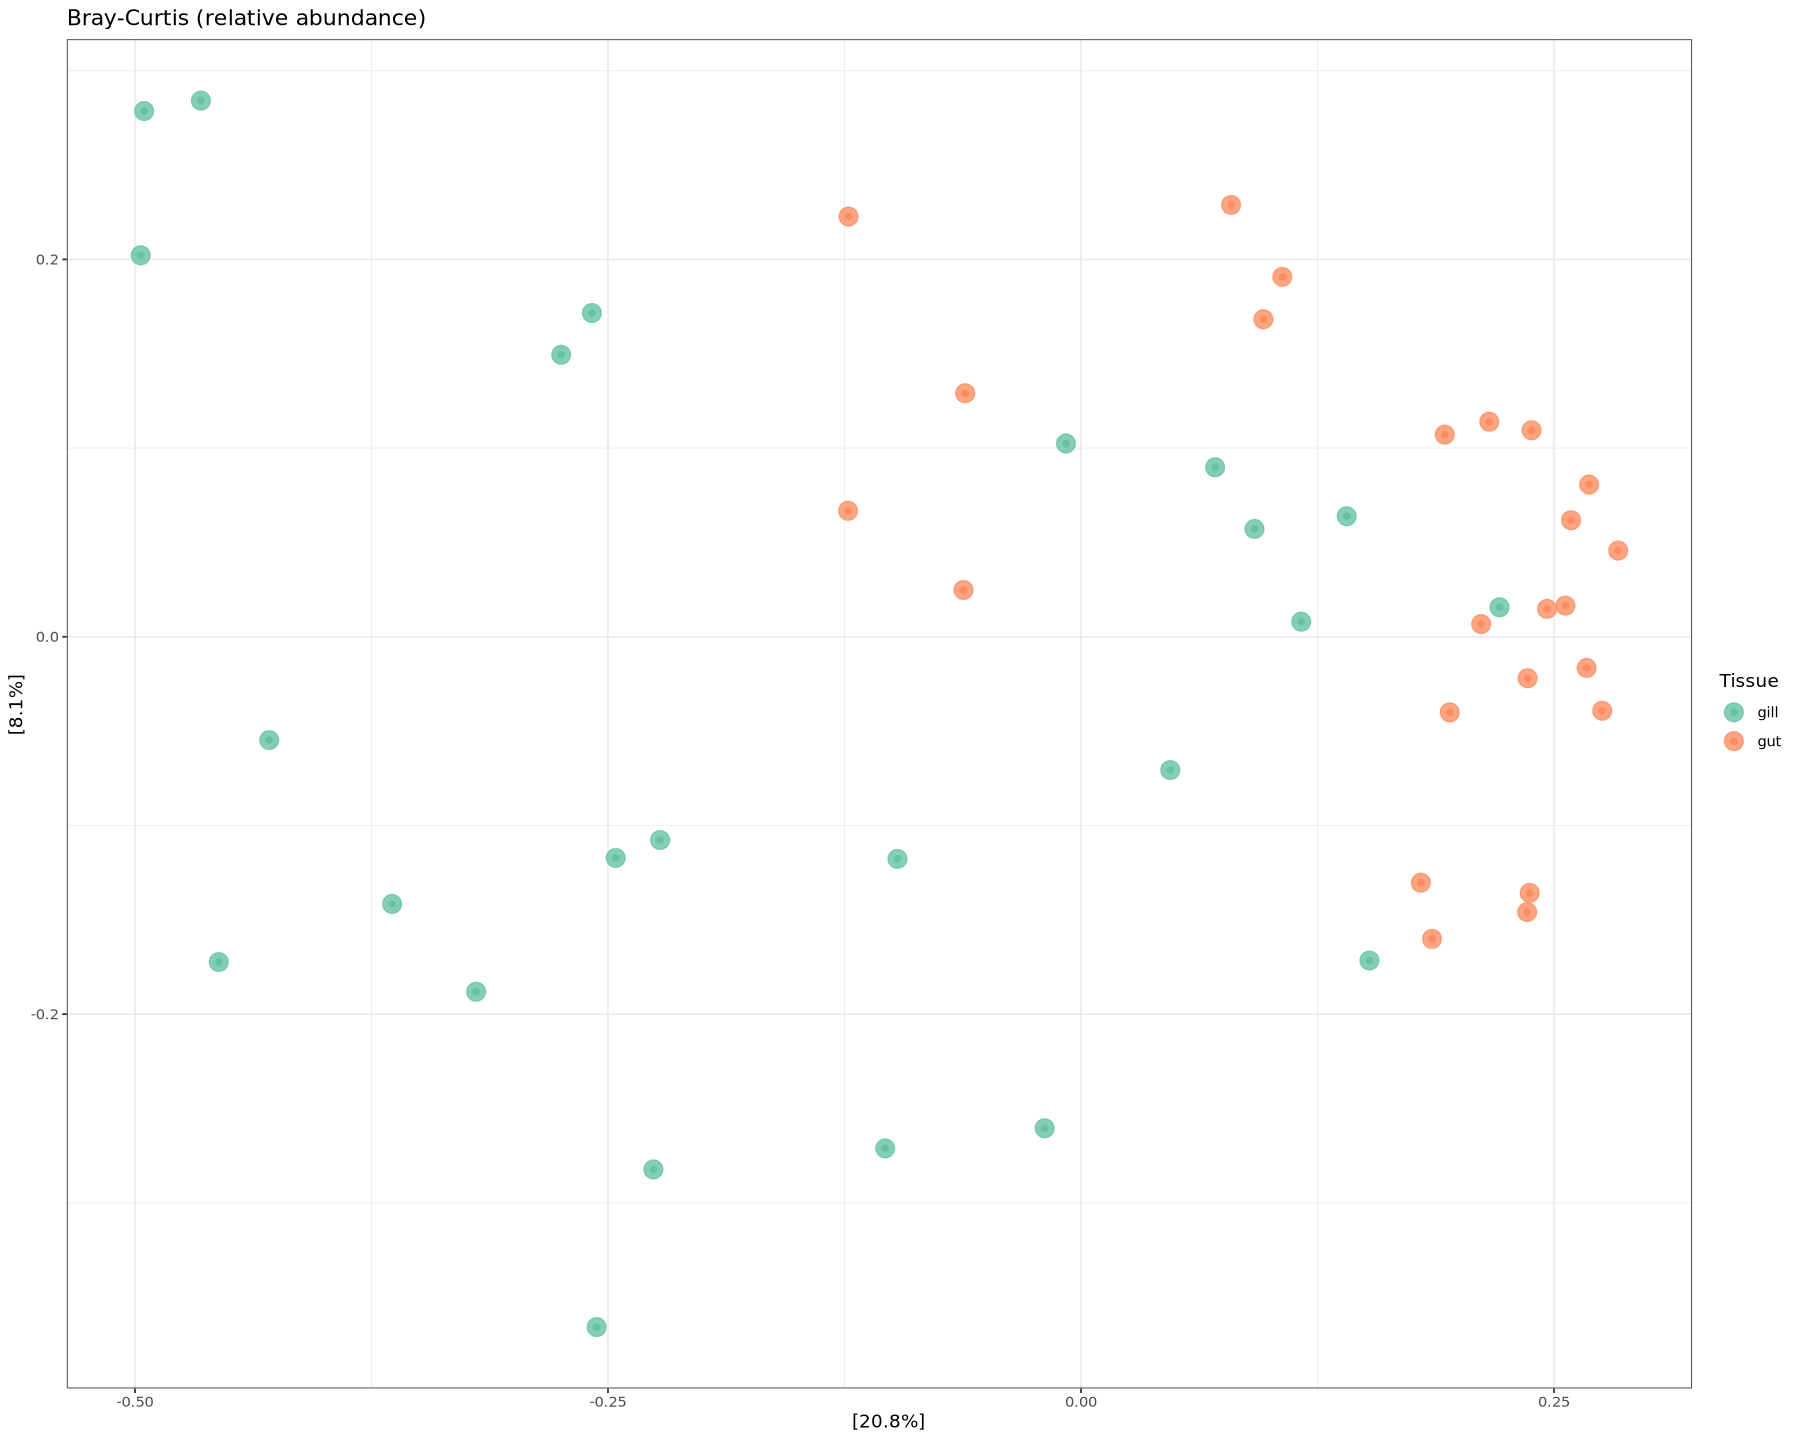

In [73]:
# Visualize PCoA
p_pcoa_bray <- plot_ordination(ps, pcoa_bray, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_pcoa_bray

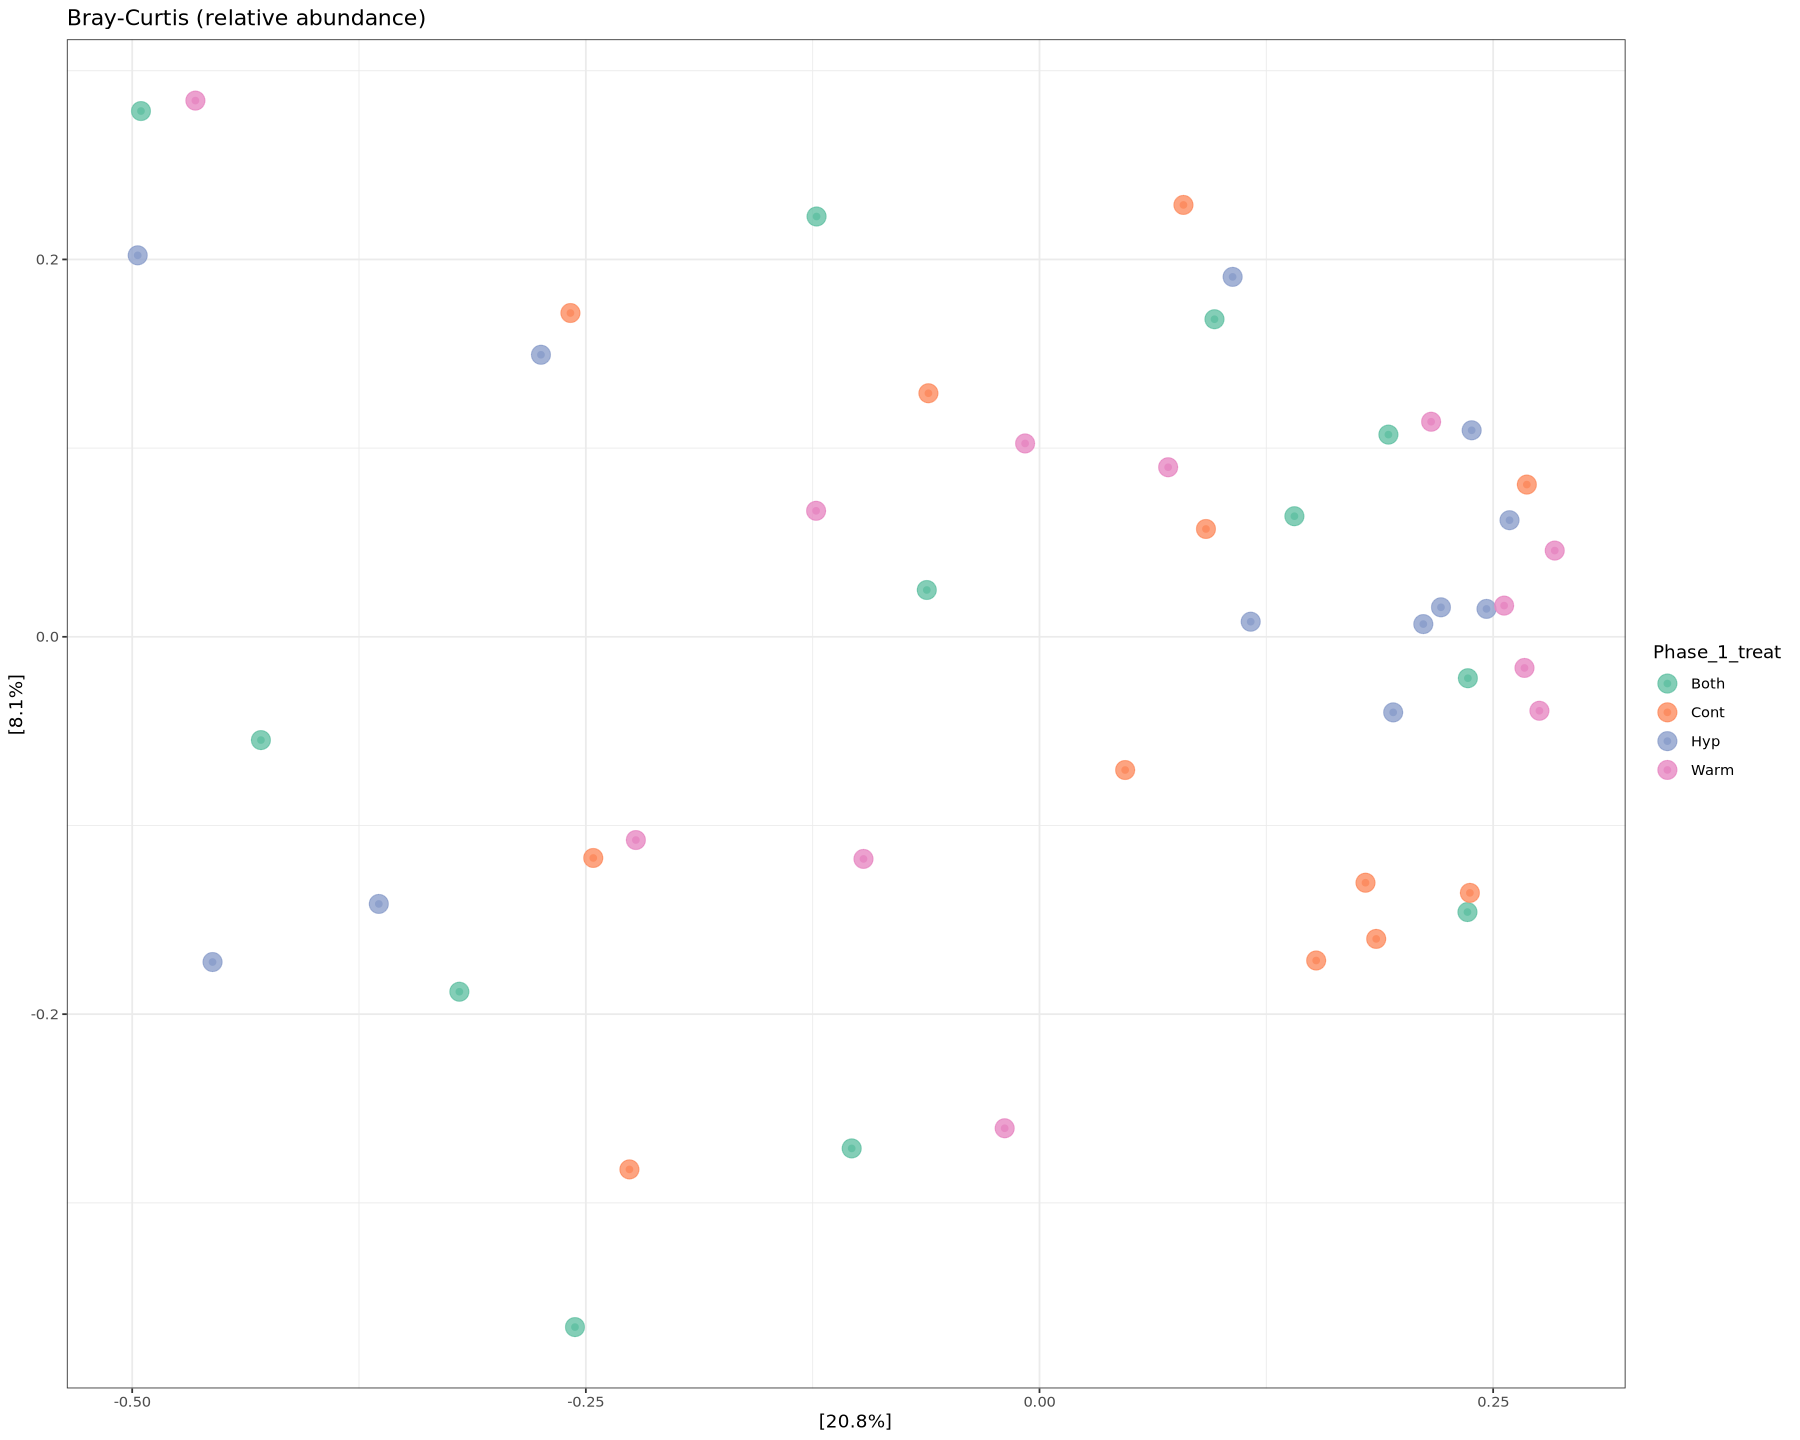

In [74]:
# Visualize PCoA
p_pcoa_bray <- plot_ordination(ps, pcoa_bray, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_pcoa_bray

In [75]:
# Ordinate using nMDS
nmds_bray <- ordinate(ps, method = "NMDS", distance = dist_bray)

Run 0 stress 0.1648777 
Run 1 stress 0.1804307 
Run 2 stress 0.1765021 
Run 3 stress 0.1757302 
Run 4 stress 0.1613762 
... New best solution
... Procrustes: rmse 0.07315363  max resid 0.2861191 
Run 5 stress 0.1654767 
Run 6 stress 0.1685991 
Run 7 stress 0.170347 
Run 8 stress 0.1750264 
Run 9 stress 0.1675622 
Run 10 stress 0.202137 
Run 11 stress 0.1711608 
Run 12 stress 0.1765021 
Run 13 stress 0.1658909 
Run 14 stress 0.1648091 
Run 15 stress 0.1818032 
Run 16 stress 0.1843411 
Run 17 stress 0.1773544 
Run 18 stress 0.1613773 
... Procrustes: rmse 0.00172799  max resid 0.007792466 
... Similar to previous best
Run 19 stress 0.1877986 
Run 20 stress 0.1731794 
*** Best solution repeated 1 times


In [76]:
# nMDS stress value (< 0.2 okay)
nmds_bray$stress

[1] 0.1613762

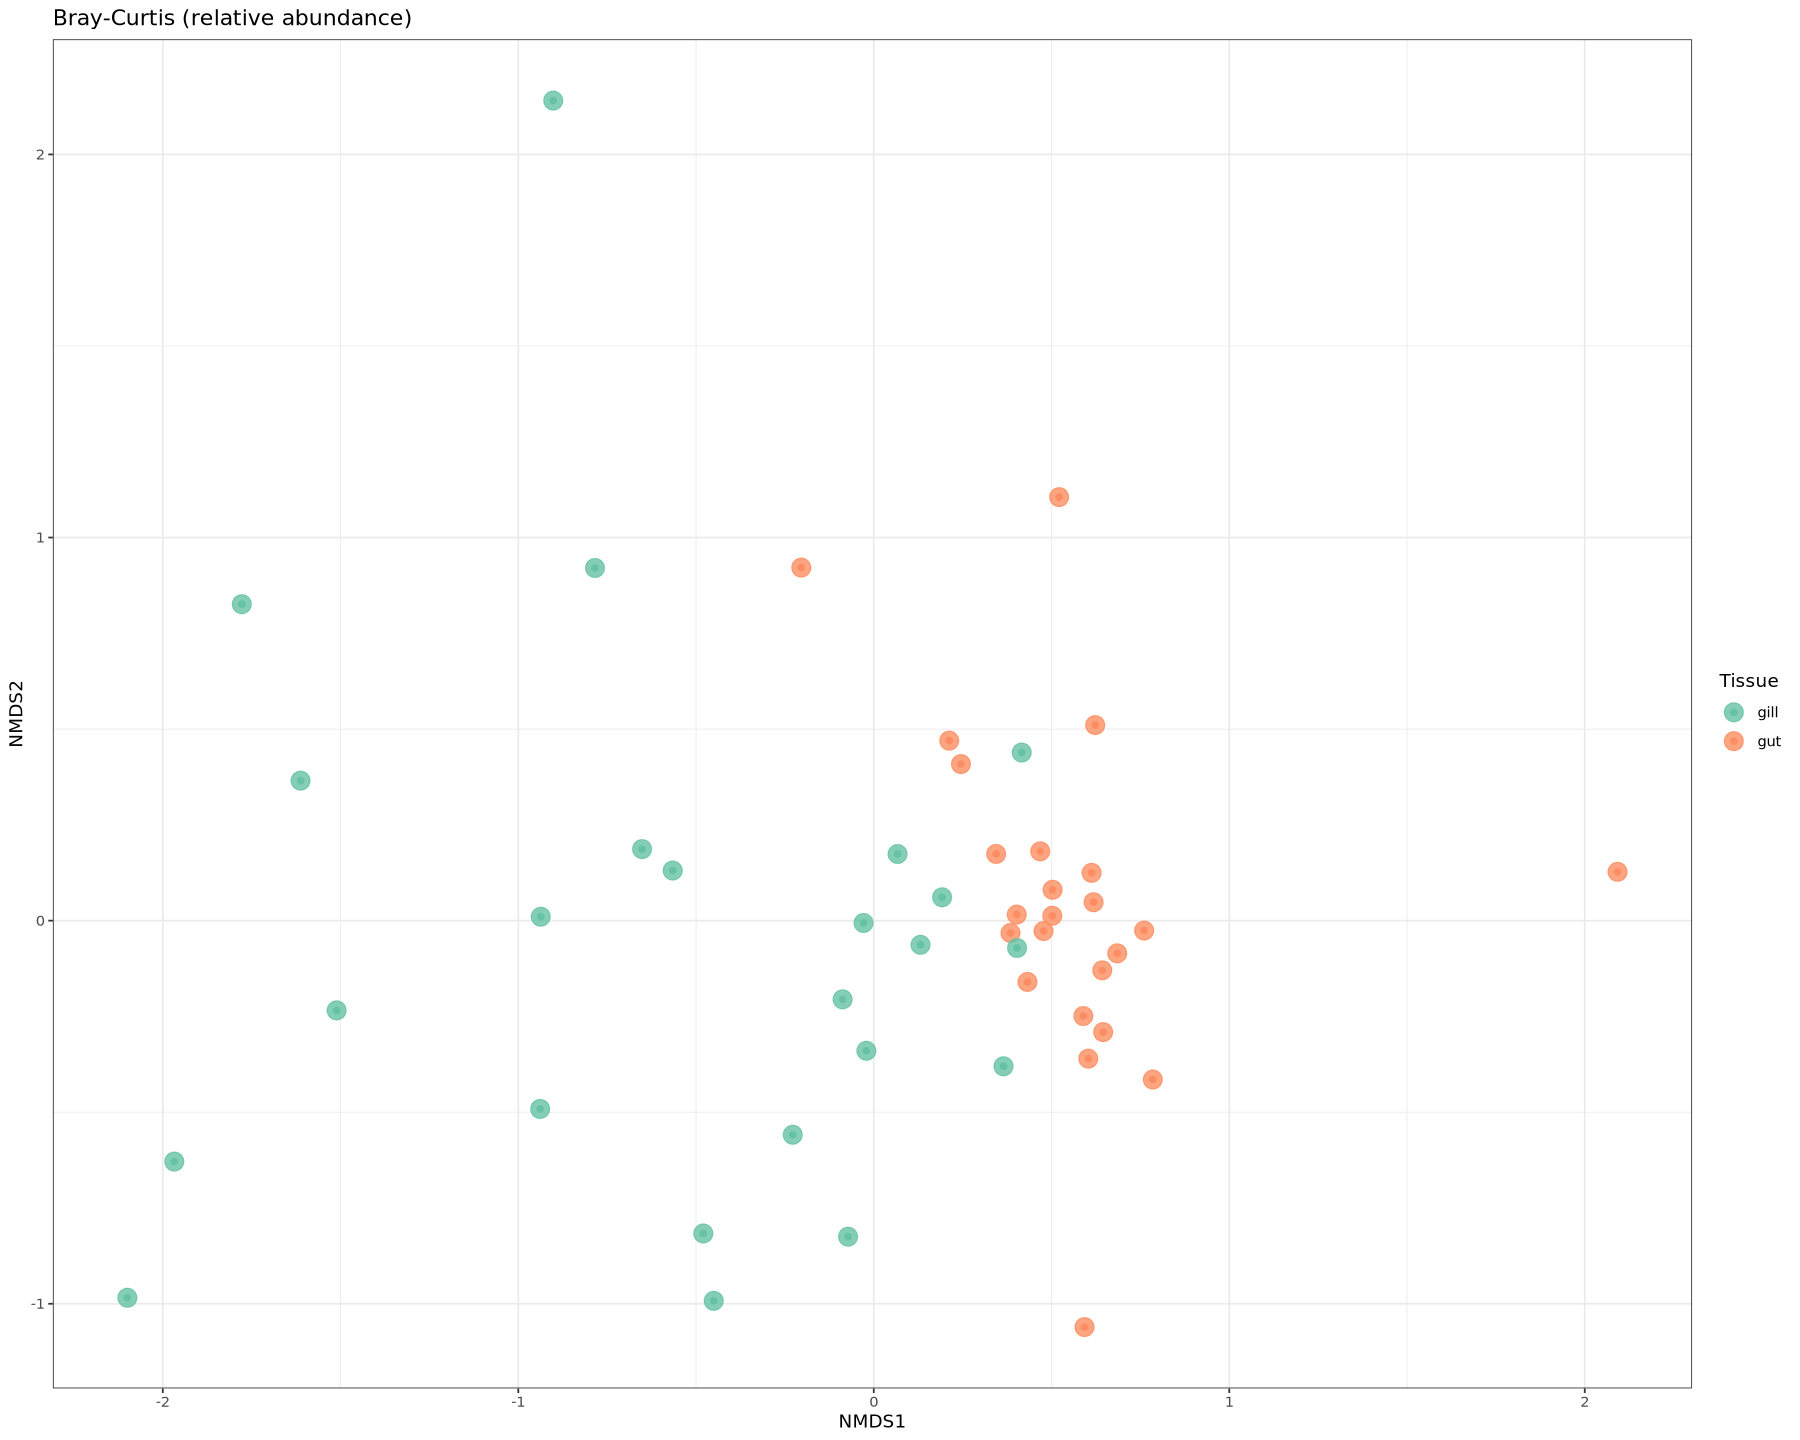

In [77]:
# Visualize nMDS
p_nmds_bray <- plot_ordination(ps, nmds_bray, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw() 
p_nmds_bray

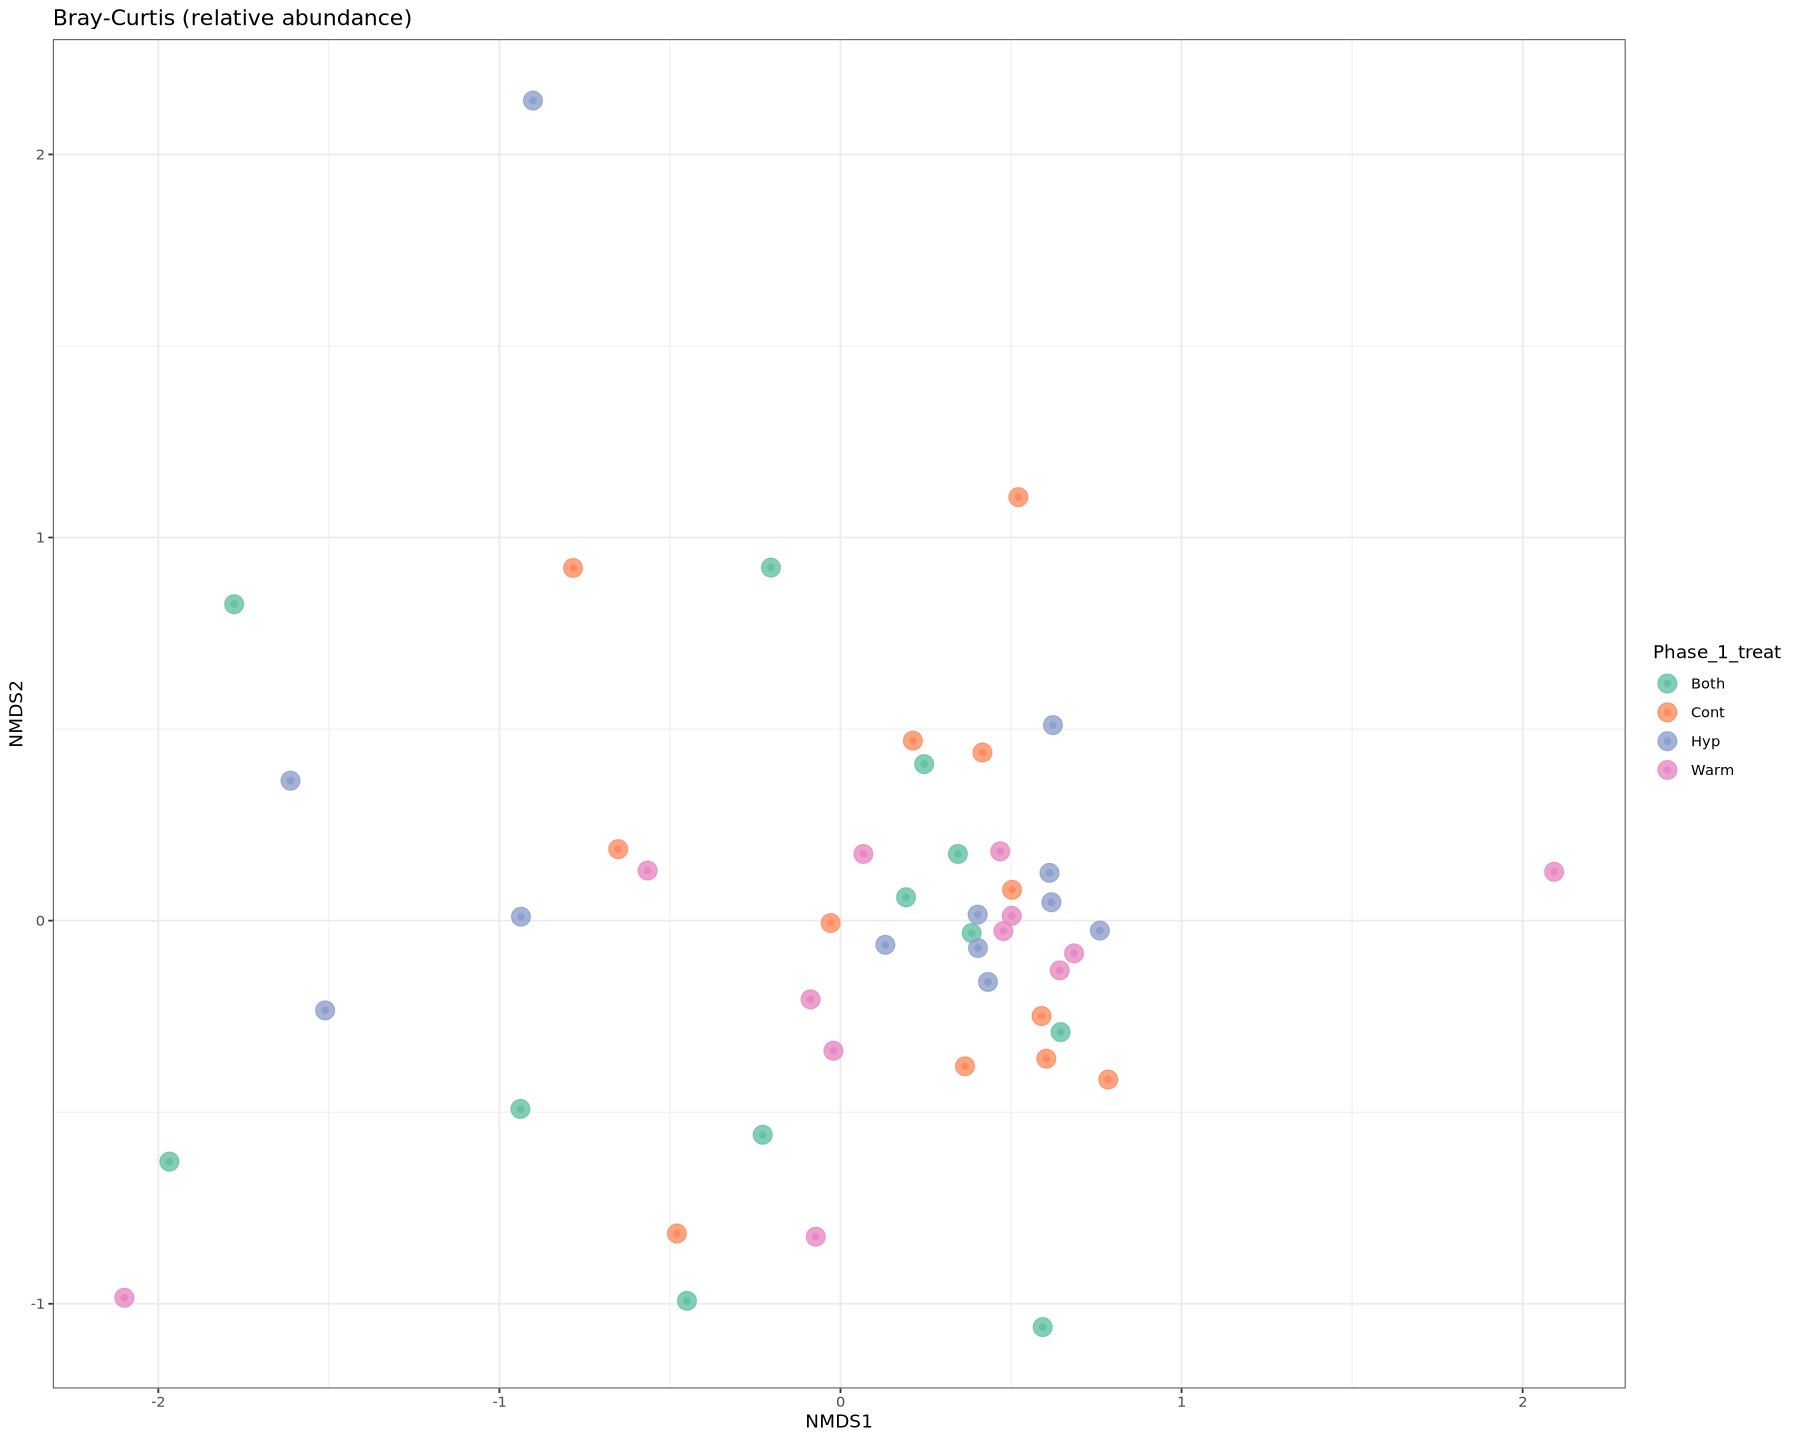

In [80]:
# Visualize nMDS
p_nmds_bray <- plot_ordination(ps, nmds_bray, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw() 
p_nmds_bray

#### Gill

In [81]:
# Subset gill samples in new phyloseq object
ps_gill <- subset_samples(ps, Tissue == "gill")
ps_gill <- prune_taxa(taxa_sums(ps_gill) > 0, ps_gill)
ps_gill

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 4535 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 4535 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 4535 reference sequences ]

In [82]:
# Compute distance matrix
dist_bray_gill <- phyloseq::distance(ps_gill, method = "bray")

In [83]:
# Ordinate using PCoA
pcoa_bray_gill <- ordinate(ps_gill, method = "PCoA", distance = dist_bray_gill)

# Variance explained by each axis
pcoa_bray_gill$values$Relative_eig[1:5] %>% round(3)

[1] 0.196 0.147 0.125 0.093 0.062

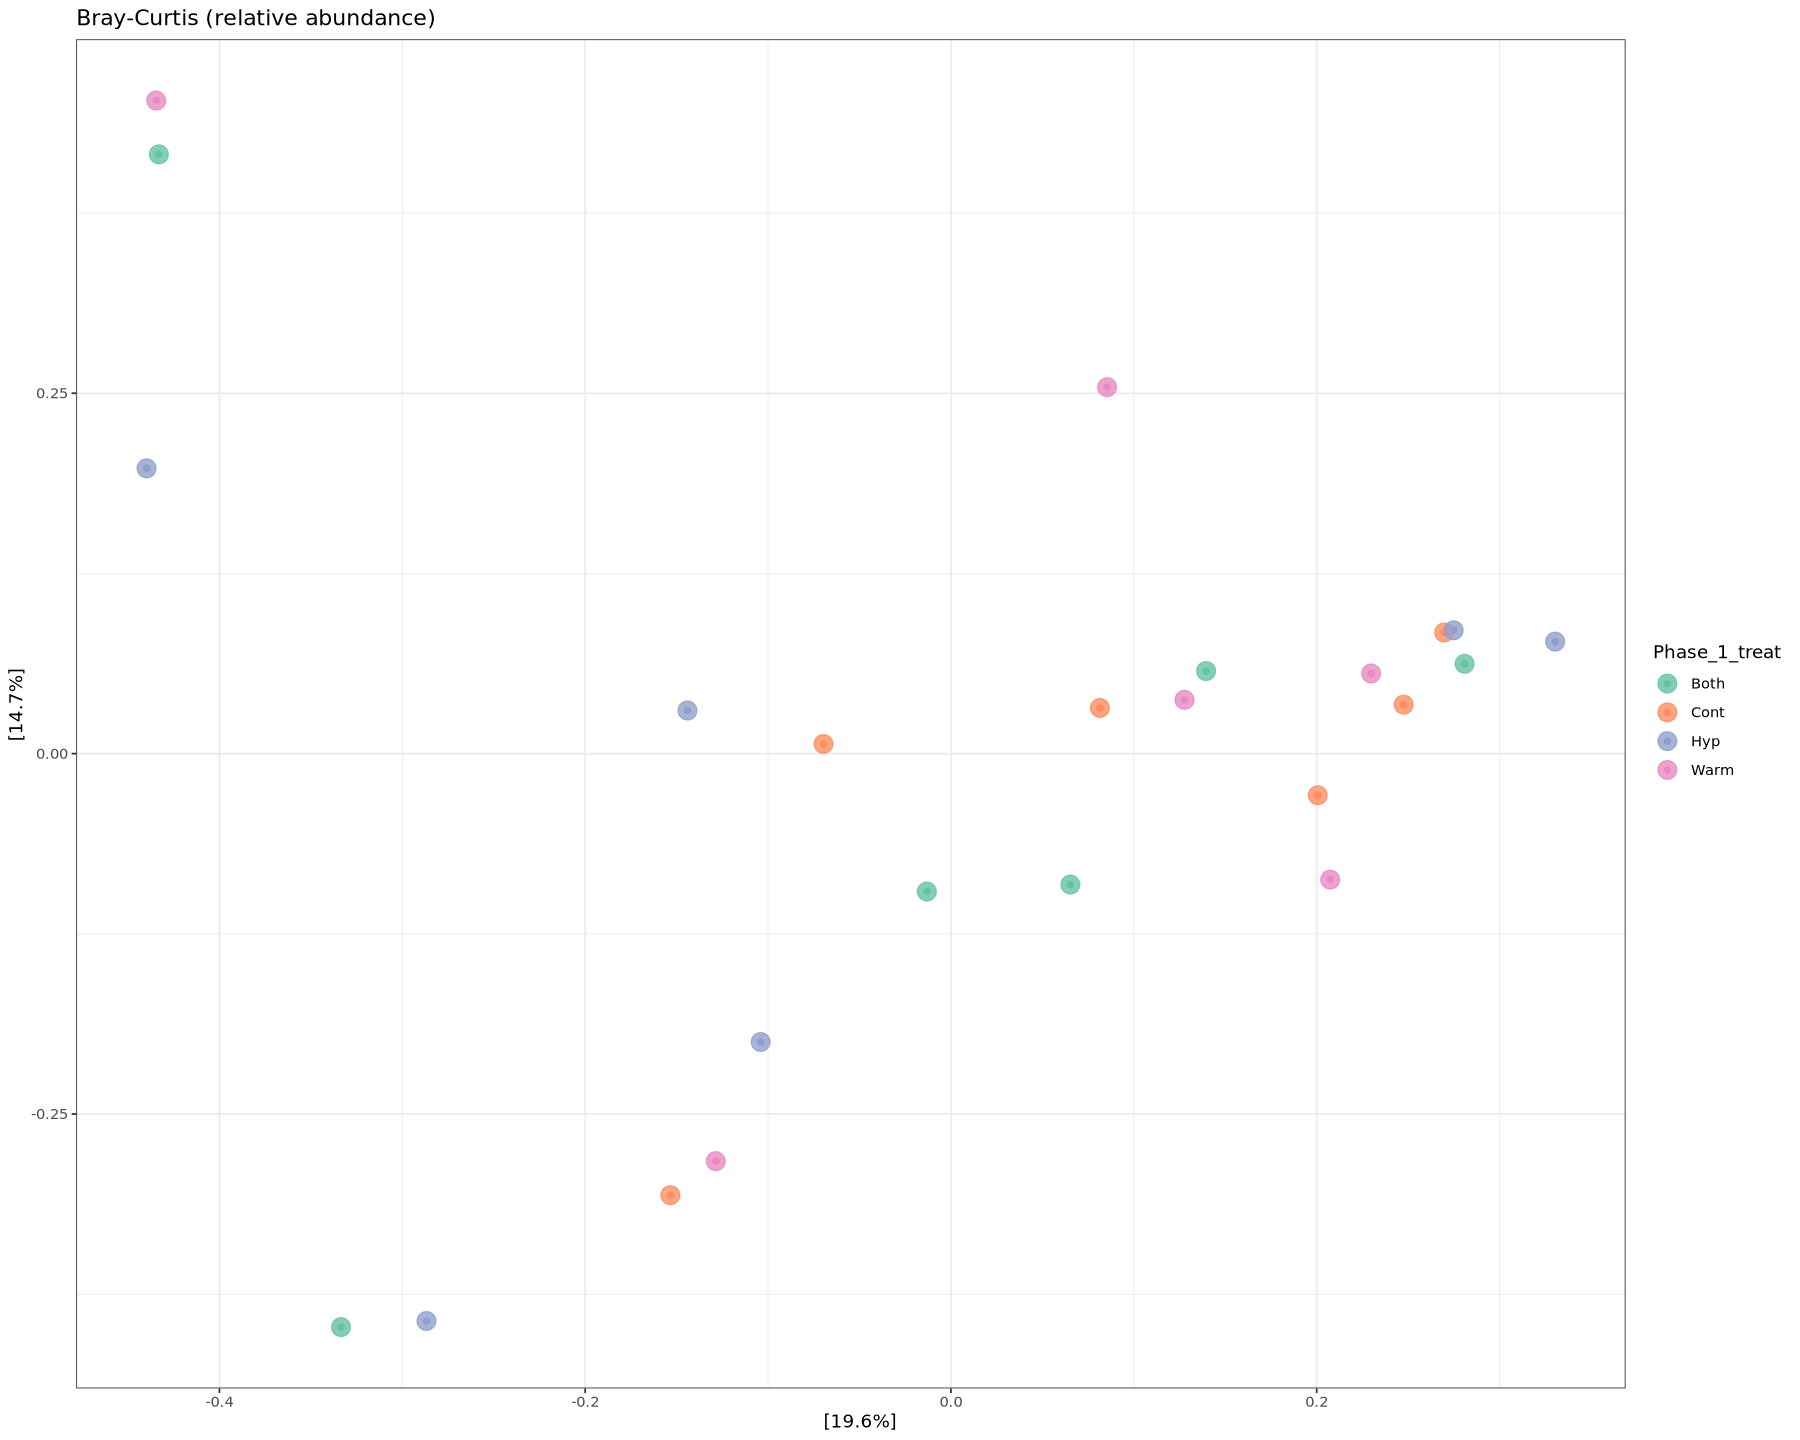

In [84]:
# Visualize PCoA
p_pcoa_bray_gill <- plot_ordination(ps_gill, pcoa_bray_gill, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_pcoa_bray_gill

In [85]:
# Ordinate using nMDS
nmds_bray_gill <- ordinate(ps_gill, method = "NMDS", distance = dist_bray_gill)

Run 0 stress 0.2052477 
Run 1 stress 0.2065068 
Run 2 stress 0.2101303 
Run 3 stress 0.204361 
... New best solution
... Procrustes: rmse 0.1581174  max resid 0.4508472 
Run 4 stress 0.1909087 
... New best solution
... Procrustes: rmse 0.1548748  max resid 0.3828722 
Run 5 stress 0.2050506 
Run 6 stress 0.1948854 
Run 7 stress 0.2045897 
Run 8 stress 0.204361 
Run 9 stress 0.2054504 
Run 10 stress 0.1908963 
... New best solution
... Procrustes: rmse 0.004153448  max resid 0.01503701 
Run 11 stress 0.1931994 
Run 12 stress 0.2087165 
Run 13 stress 0.194701 
Run 14 stress 0.2012268 
Run 15 stress 0.1944708 
Run 16 stress 0.2098013 
Run 17 stress 0.2455681 
Run 18 stress 0.1931994 
Run 19 stress 0.1948854 
Run 20 stress 0.1944703 
*** Best solution was not repeated -- monoMDS stopping criteria:
    20: stress ratio > sratmax


In [86]:
# nMDS stress value (< 0.2 okay)
nmds_bray_gill$stress

[1] 0.1908963

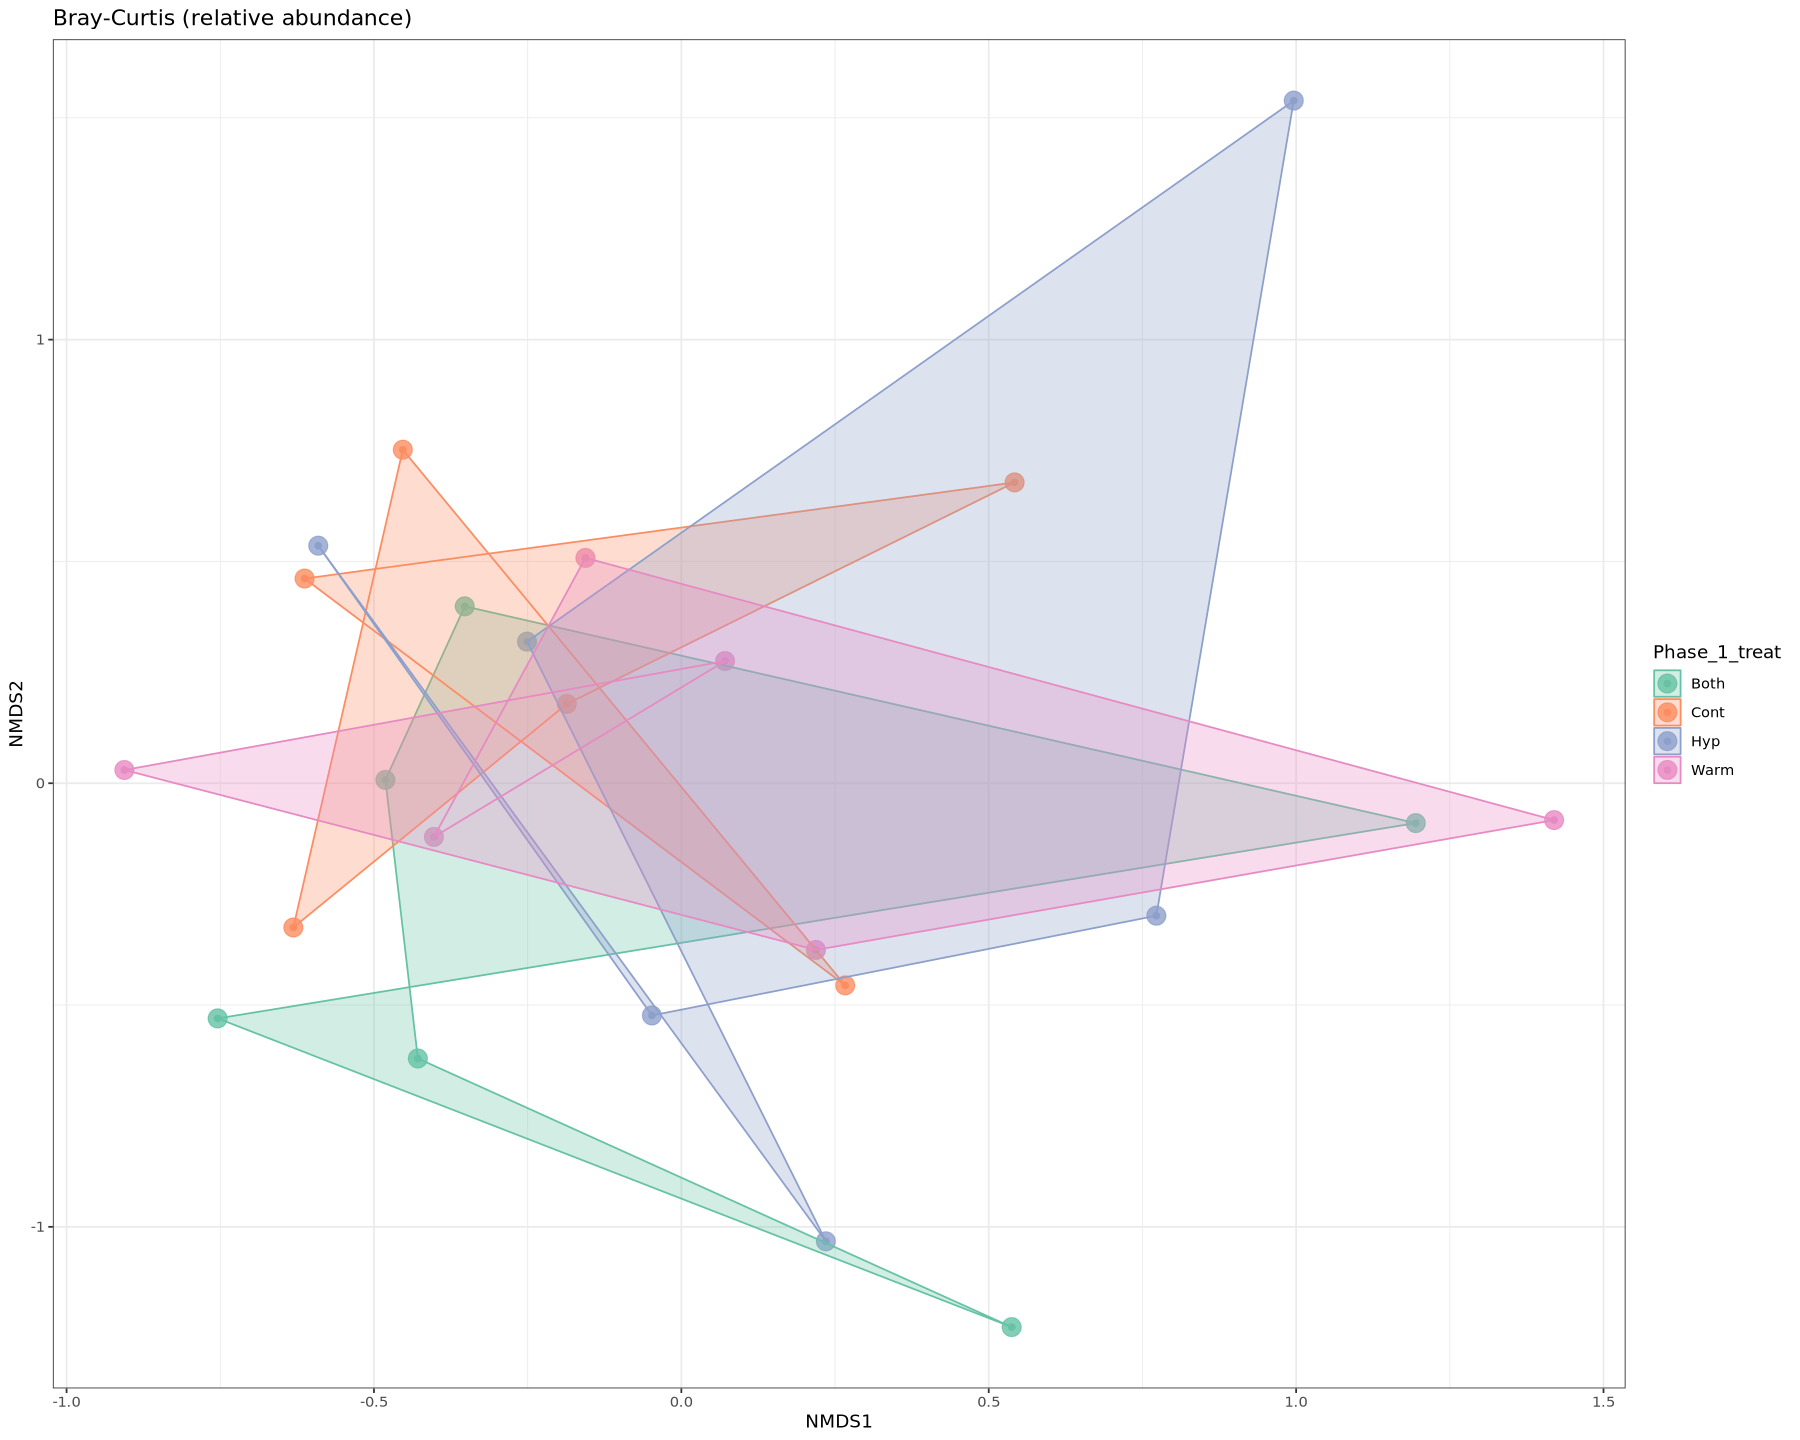

In [87]:
# Visualize nMDS
p_nmds_bray_gill <- plot_ordination(ps_gill, nmds_bray_gill, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw() 

p_nmds_bray_gill

#### Gut

Still contains chloroplasts!

In [88]:
# Subset gut samples in new phyloseq object
ps_gut <- subset_samples(ps, Tissue == "gut")
ps_gut <- prune_taxa(taxa_sums(ps_gut) > 0, ps_gut)
ps_gut

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 7727 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 7727 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 7727 reference sequences ]

In [89]:
# Compute distance matrix
dist_bray_gut <- phyloseq::distance(ps_gut, method = "bray")

In [90]:
# Ordinate using PCoA
pcoa_bray_gut <- ordinate(ps_gut, method = "PCoA", distance = dist_bray_gut)

# Variance explained by each axis
pcoa_bray_gut$values$Relative_eig[1:5] %>% round(3)

[1] 0.178 0.147 0.092 0.084 0.069

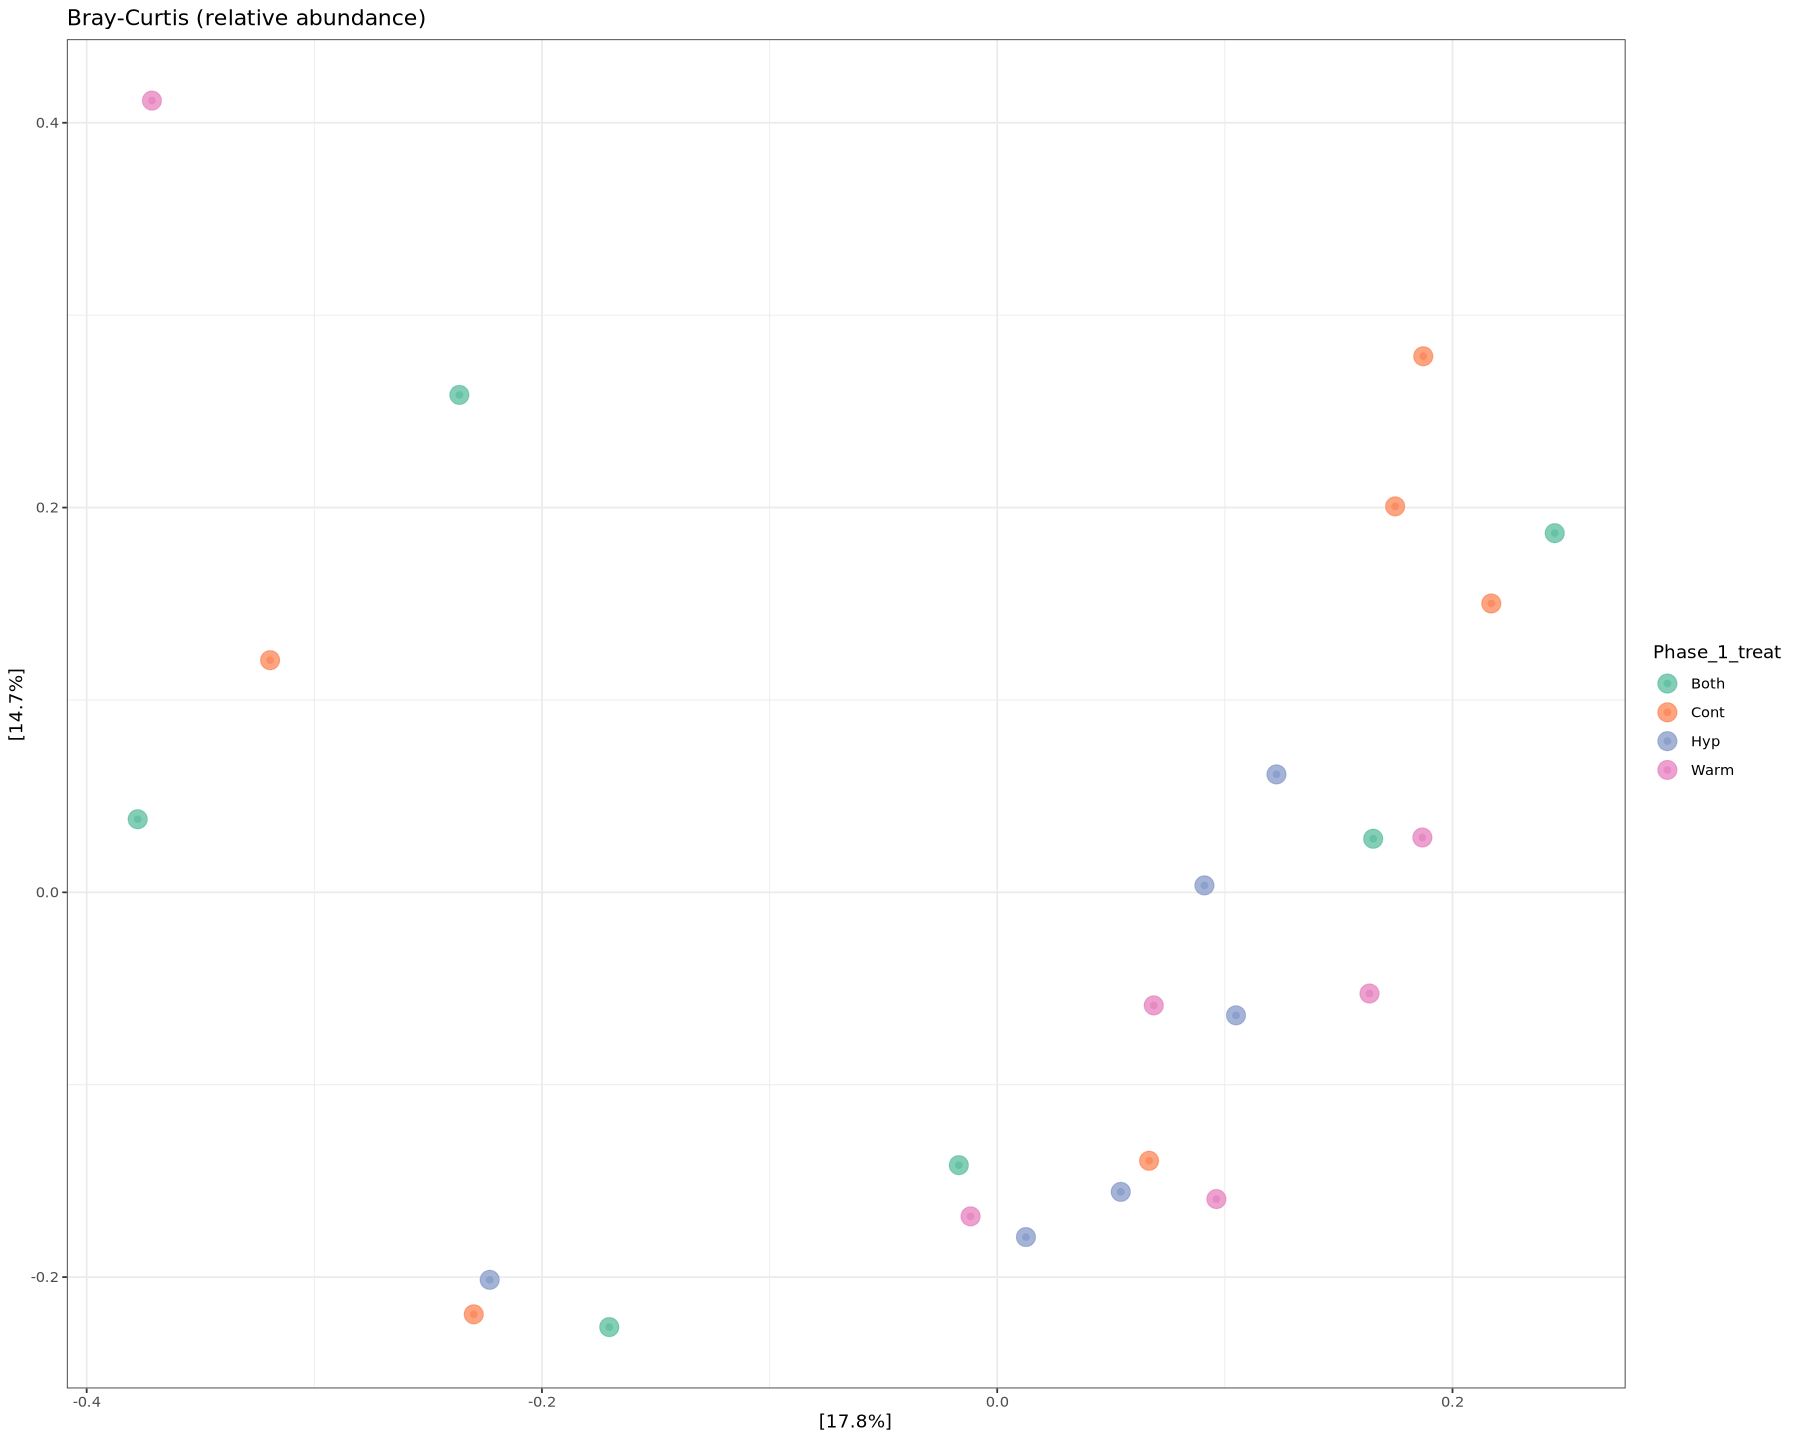

In [91]:
# Visualize PCoA
p_pcoa_bray_gut <- plot_ordination(ps_gut, pcoa_bray_gut, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_pcoa_bray_gut

In [92]:
# Ordinate using nMDS
nmds_bray_gut <- ordinate(ps_gut, method = "NMDS", distance = dist_bray_gut)

Run 0 stress 0.1082412 
Run 1 stress 0.1077226 
... New best solution
... Procrustes: rmse 0.0483309  max resid 0.1359831 
Run 2 stress 0.1233394 
Run 3 stress 0.1051785 
... New best solution
... Procrustes: rmse 0.03943106  max resid 0.1387724 
Run 4 stress 0.1572643 
Run 5 stress 0.1089399 
Run 6 stress 0.1278598 
Run 7 stress 0.1079737 
Run 8 stress 0.1146248 
Run 9 stress 0.1138942 
Run 10 stress 0.1145458 
Run 11 stress 0.1097123 
Run 12 stress 0.1252866 
Run 13 stress 0.1261887 
Run 14 stress 0.1261891 
Run 15 stress 0.1051781 
... New best solution
... Procrustes: rmse 0.0001518124  max resid 0.0004380625 
... Similar to previous best
Run 16 stress 0.1056943 
Run 17 stress 0.1320766 
Run 18 stress 0.1089519 
Run 19 stress 0.1077225 
Run 20 stress 0.1051782 
... Procrustes: rmse 0.0005331507  max resid 0.001558507 
... Similar to previous best
*** Best solution repeated 2 times


In [93]:
# nMDS stress value (< 0.2 okay)
nmds_bray_gut$stress

[1] 0.1051781

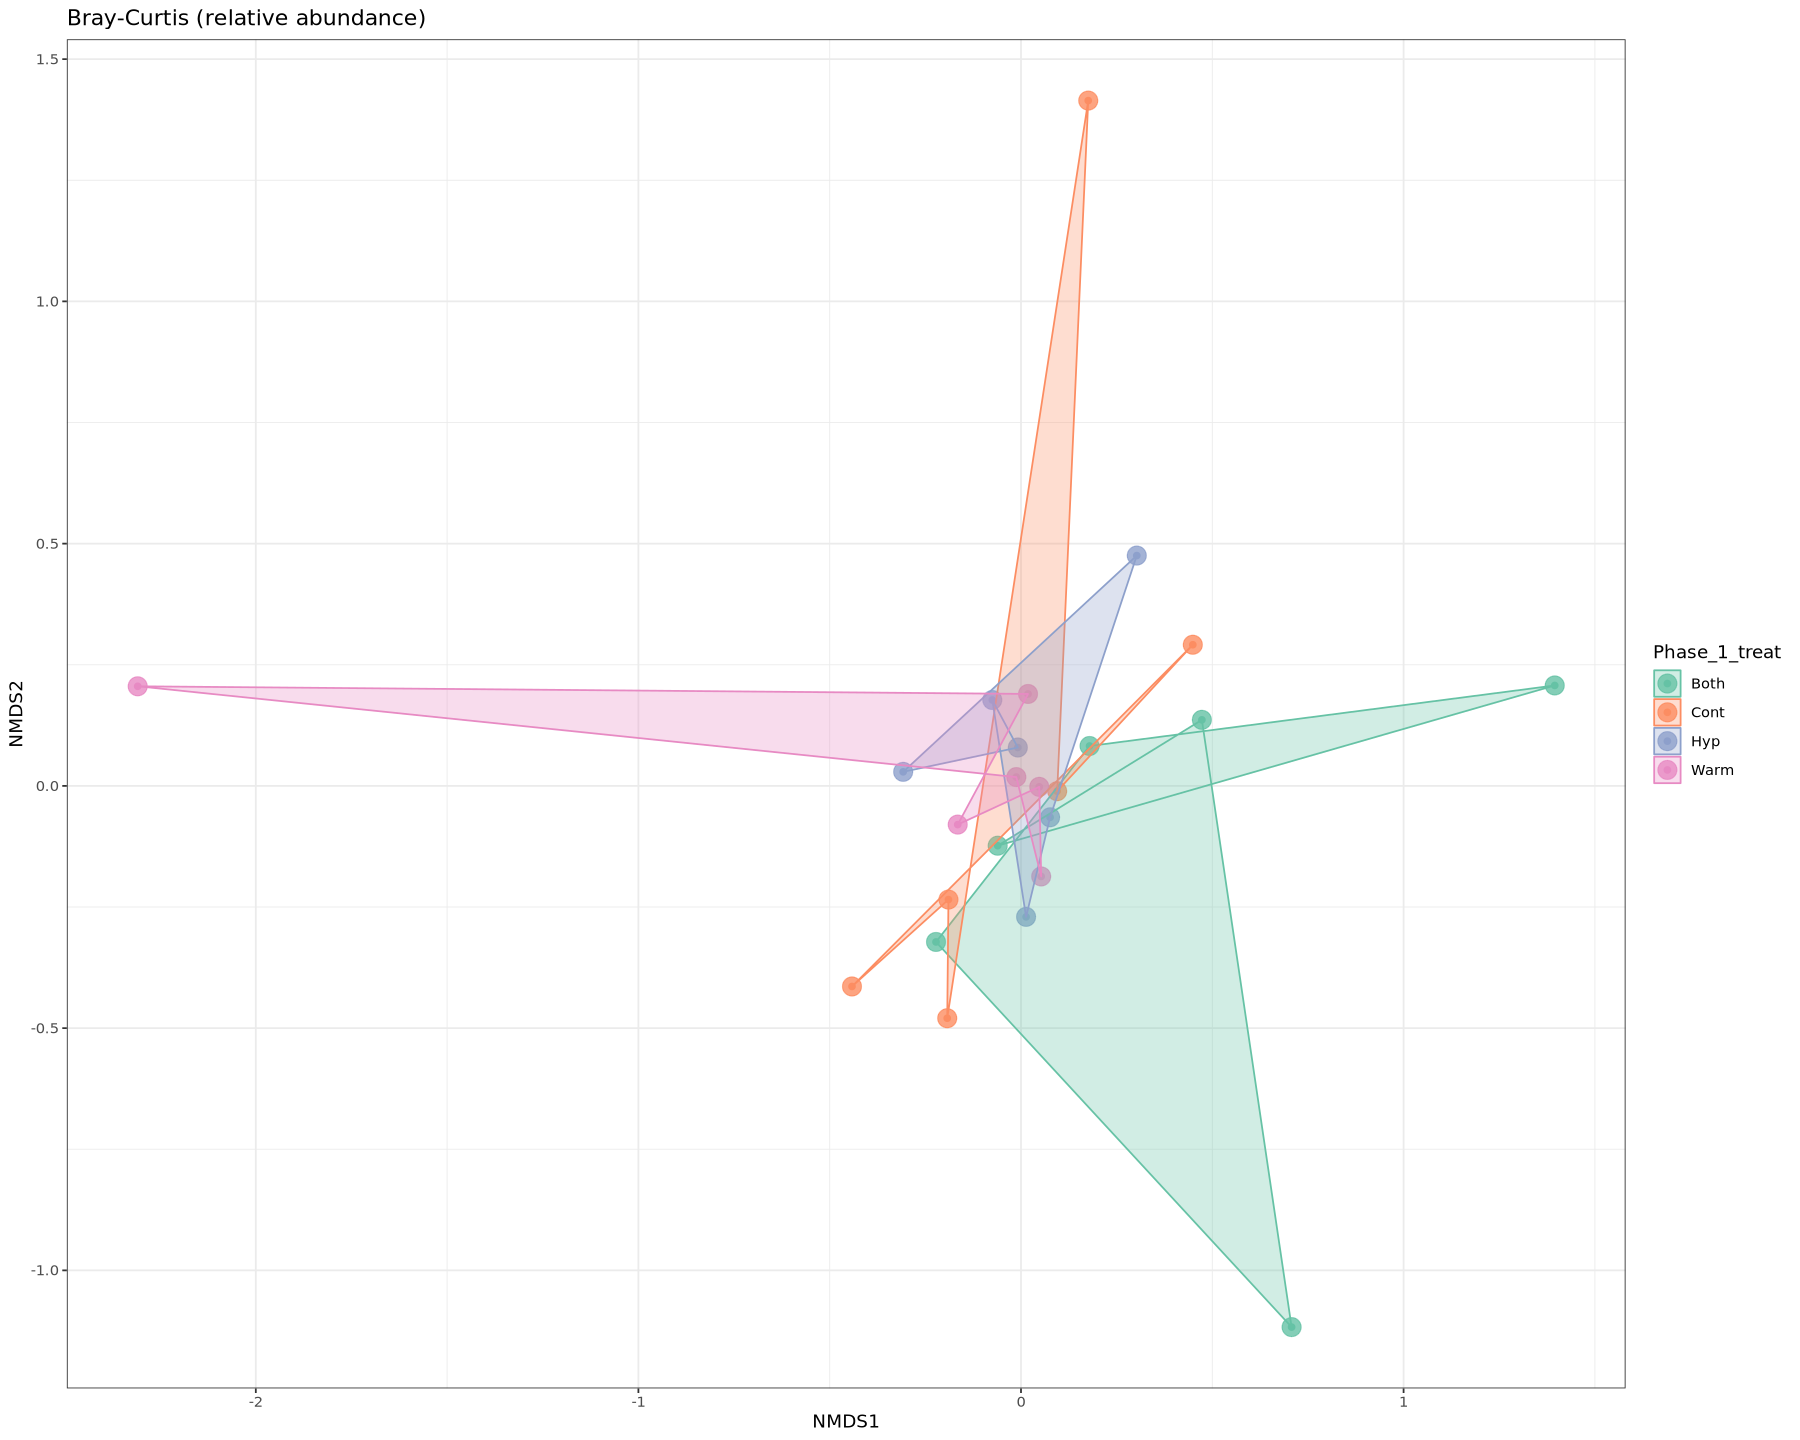

In [94]:
# Visualize nMDS
p_nmds_bray_gut <- plot_ordination(ps_gut, nmds_bray_gut, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw() 
p_nmds_bray_gut

Would be interested in looking at just both and control, if there are significant differences in beta diversity

### Gill + gut, no chloroplasts

In [102]:
# Subset gut samples in new phyloseq object
ps_nc <- subset_taxa(ps, Order != "Chloroplast")
ps_nc <- prune_taxa(taxa_sums(ps_nc) > 0, ps_nc)
ps_nc

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 8705 taxa and 48 samples ]
sample_data() Sample Data:       [ 48 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 8705 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 8705 reference sequences ]

In [103]:
# Compute distance matrix
dist_bray_nc <- phyloseq::distance(ps_nc, method = "bray")

In [104]:
# Ordinate using PCoA
pcoa_bray_nc <- ordinate(ps_nc, method = "PCoA", distance = dist_bray_nc)

# Variance explained by each axis
pcoa_bray_nc$values$Relative_eig[1:5] %>% round(3)

[1] 0.213 0.082 0.080 0.070 0.057

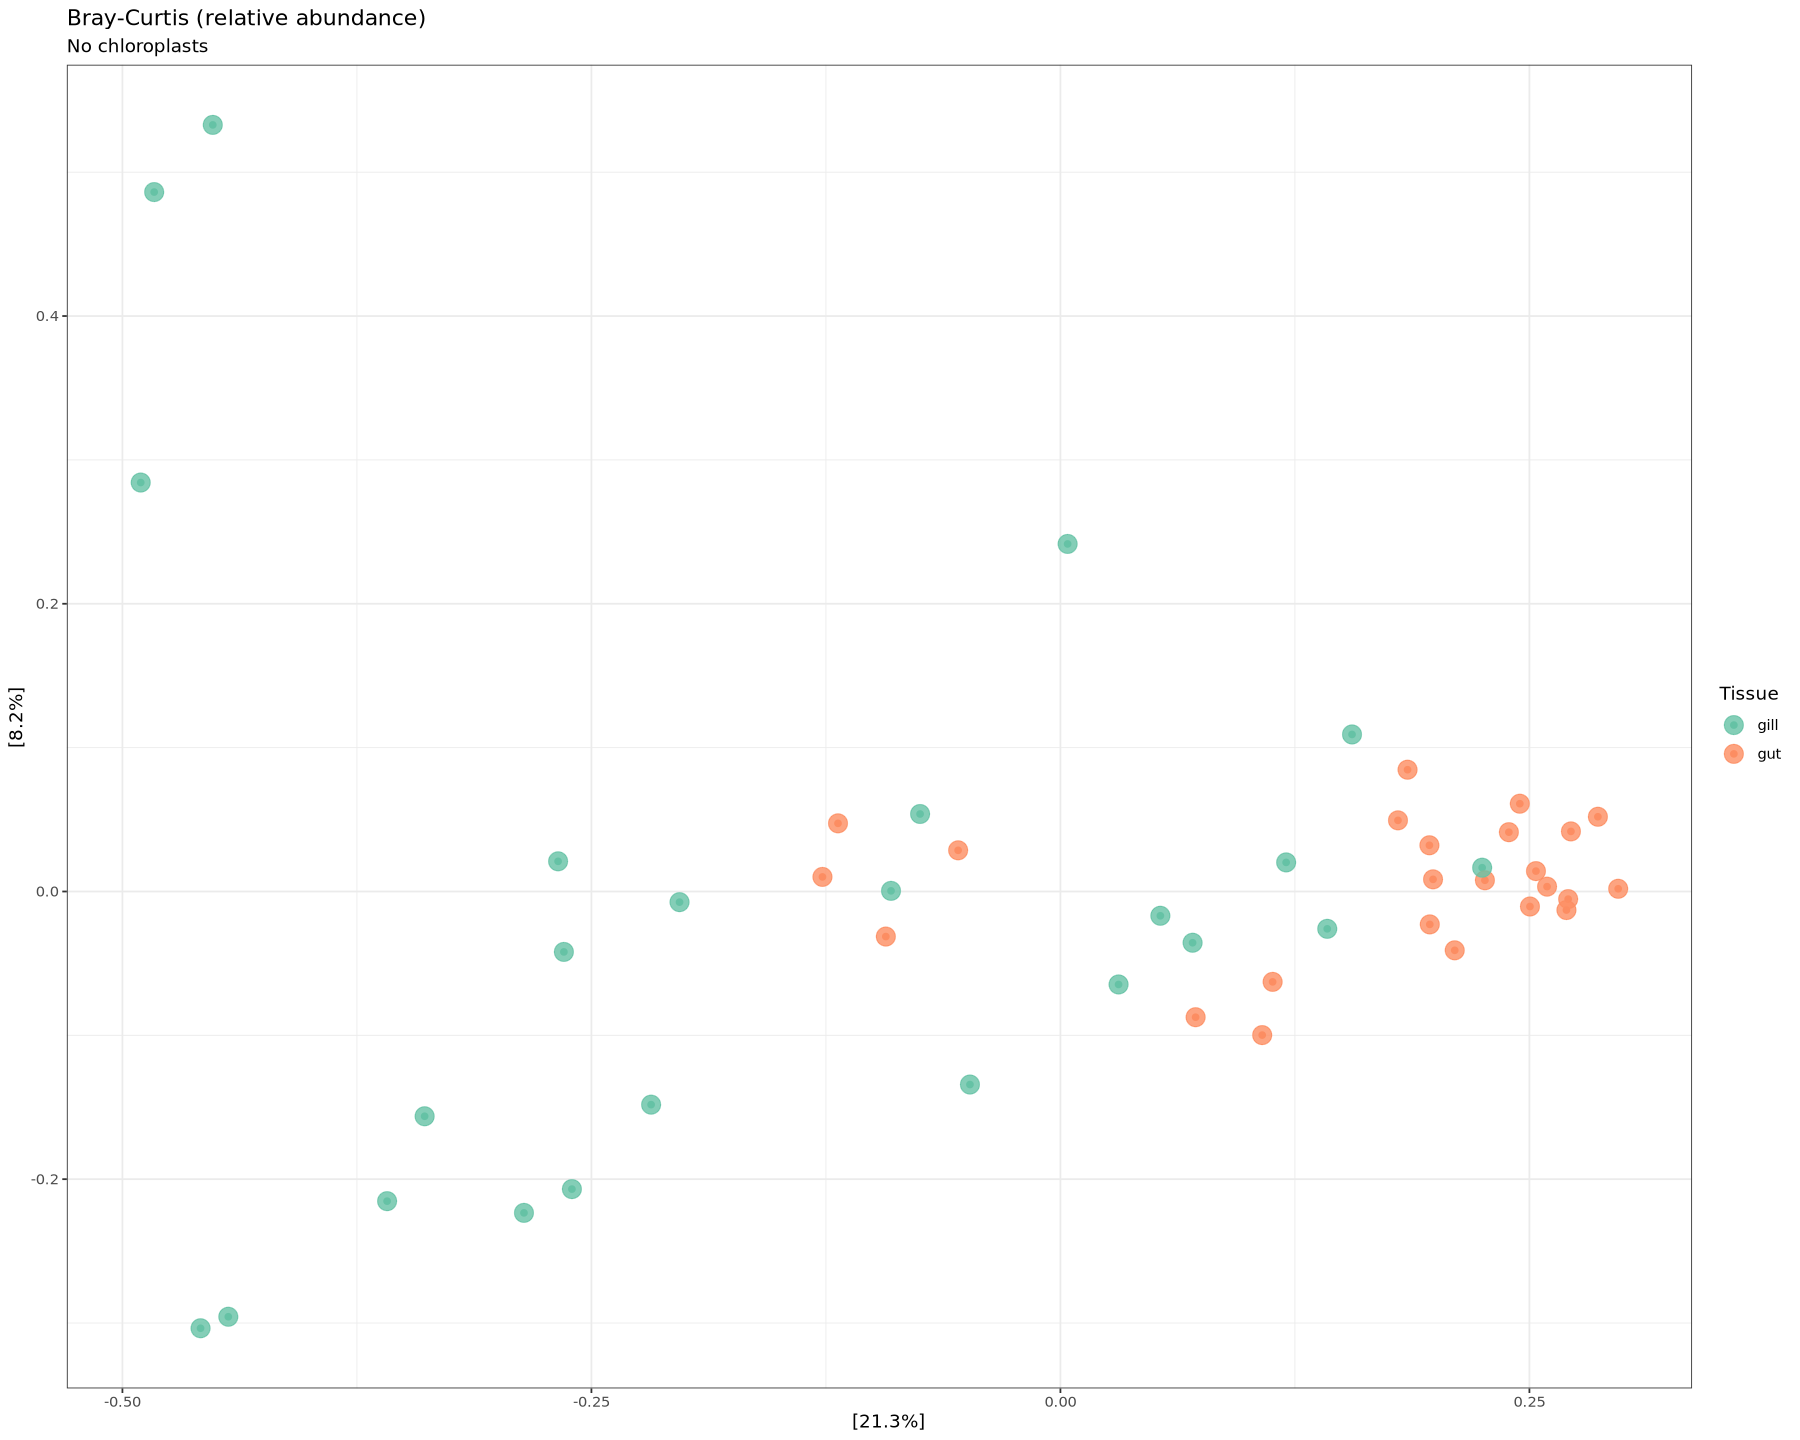

In [107]:
# Visualize PCoA
p_pcoa_bray_nc <- plot_ordination(ps_nc, pcoa_bray_nc, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw()
p_pcoa_bray_nc

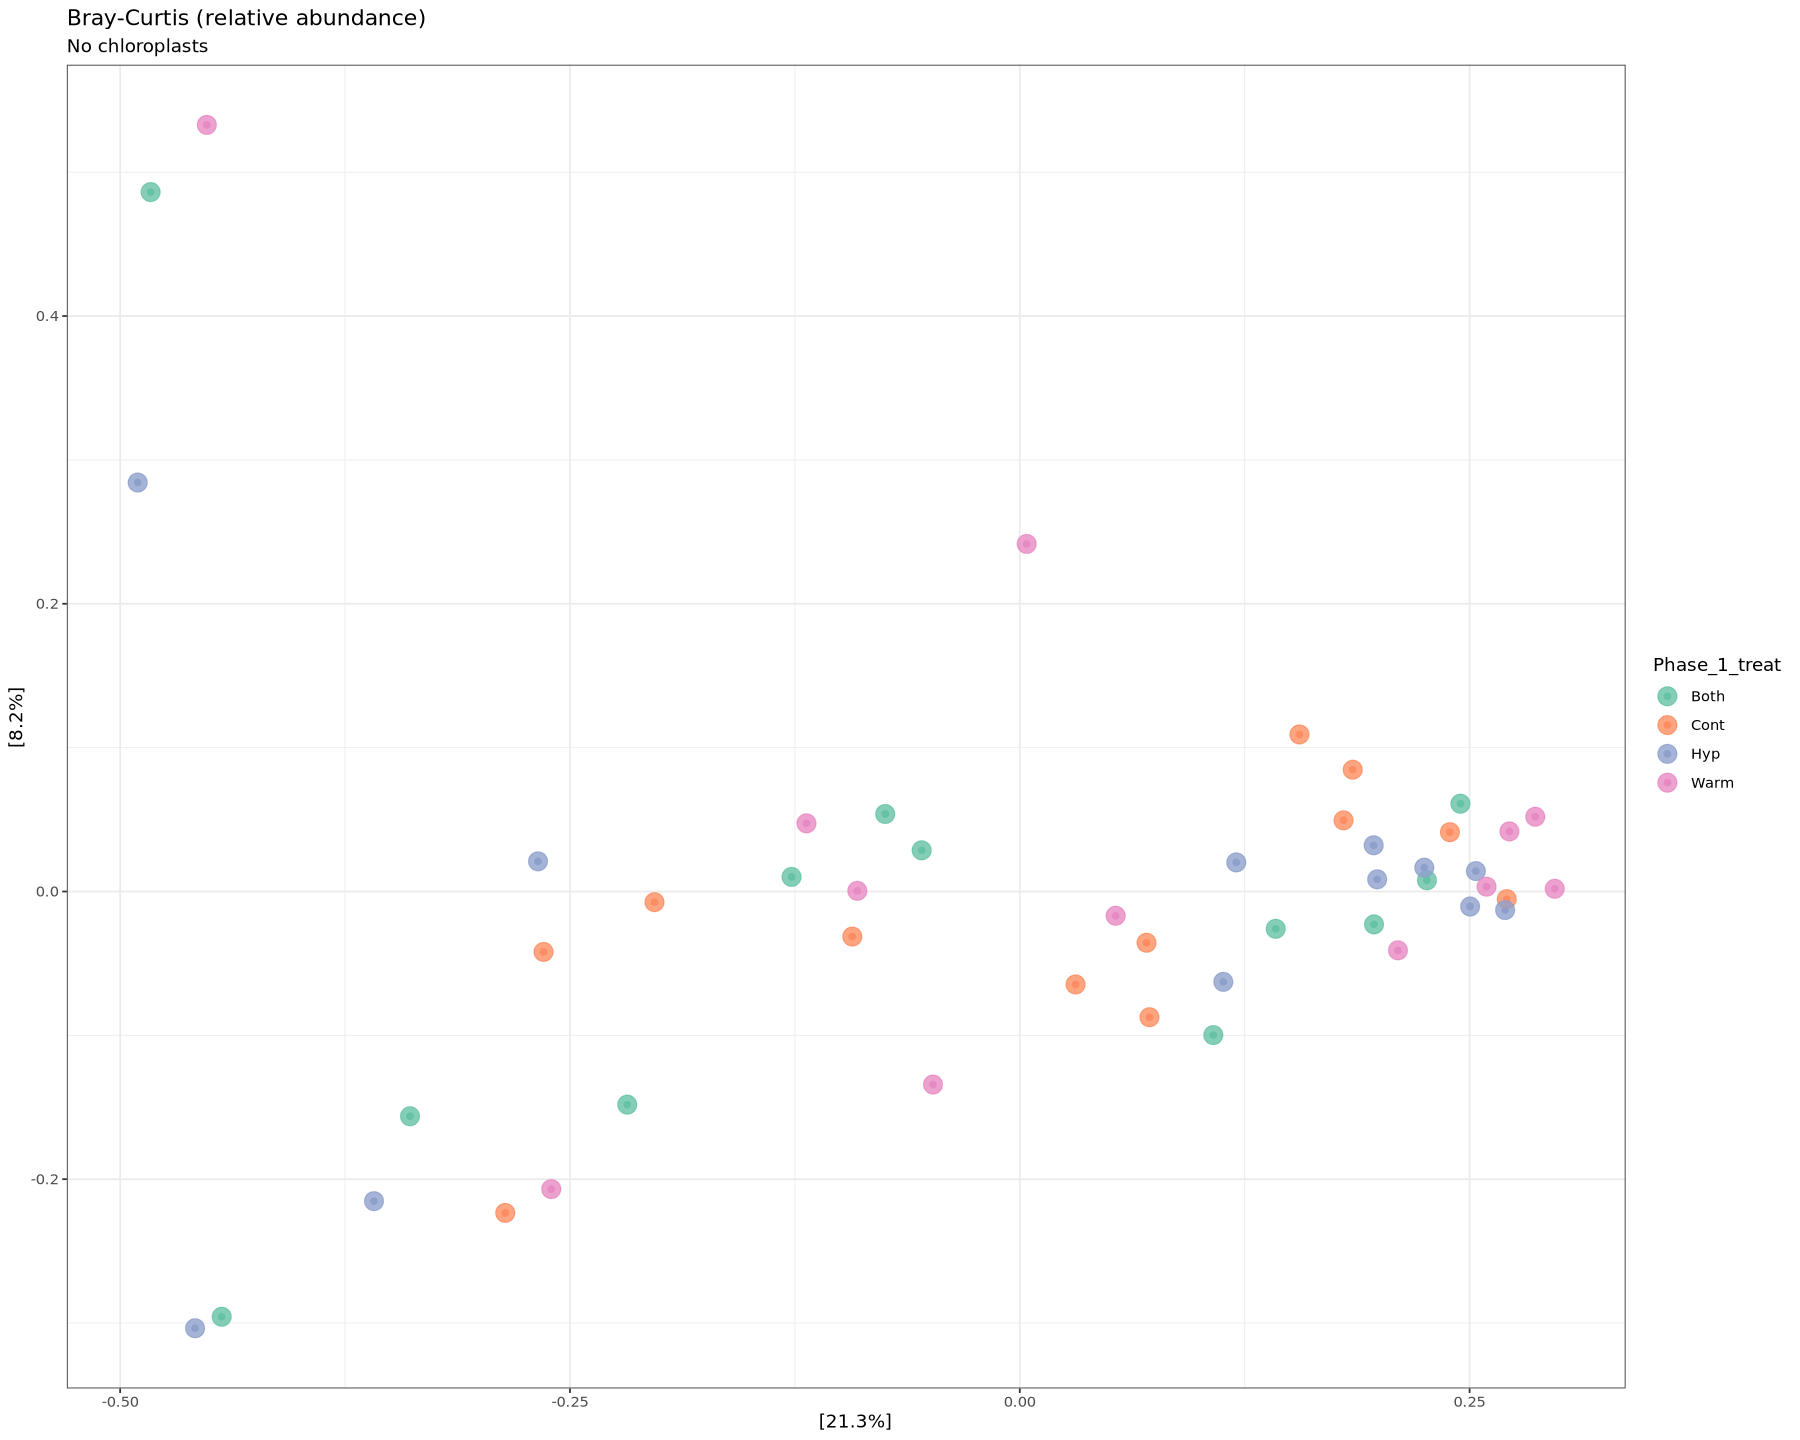

In [108]:
# Visualize PCoA
p_pcoa_bray_nc <- plot_ordination(ps_nc, pcoa_bray_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw()
p_pcoa_bray_nc

In [109]:
# Ordinate using nMDS
nmds_bray_nc <- ordinate(ps_nc, method = "NMDS", distance = dist_bray_nc)

Run 0 stress 0.1799811 
Run 1 stress 0.1668991 
... New best solution
... Procrustes: rmse 0.07415053  max resid 0.2613008 
Run 2 stress 0.1763889 
Run 3 stress 0.1708271 
Run 4 stress 0.1716718 
Run 5 stress 0.1736035 
Run 6 stress 0.1861335 
Run 7 stress 0.1724389 
Run 8 stress 0.1715484 
Run 9 stress 0.1671689 
... Procrustes: rmse 0.08115267  max resid 0.2797647 
Run 10 stress 0.1764463 
Run 11 stress 0.186259 
Run 12 stress 0.1753245 
Run 13 stress 0.1709785 
Run 14 stress 0.1728098 
Run 15 stress 0.1738859 
Run 16 stress 0.1668982 
... New best solution
... Procrustes: rmse 0.00118525  max resid 0.007398819 
... Similar to previous best
Run 17 stress 0.1728241 
Run 18 stress 0.1862871 
Run 19 stress 0.1747151 
Run 20 stress 0.1853676 
*** Best solution repeated 1 times


In [111]:
# nMDS stress value (< 0.2 okay)
nmds_bray_nc$stress

[1] 0.1668982

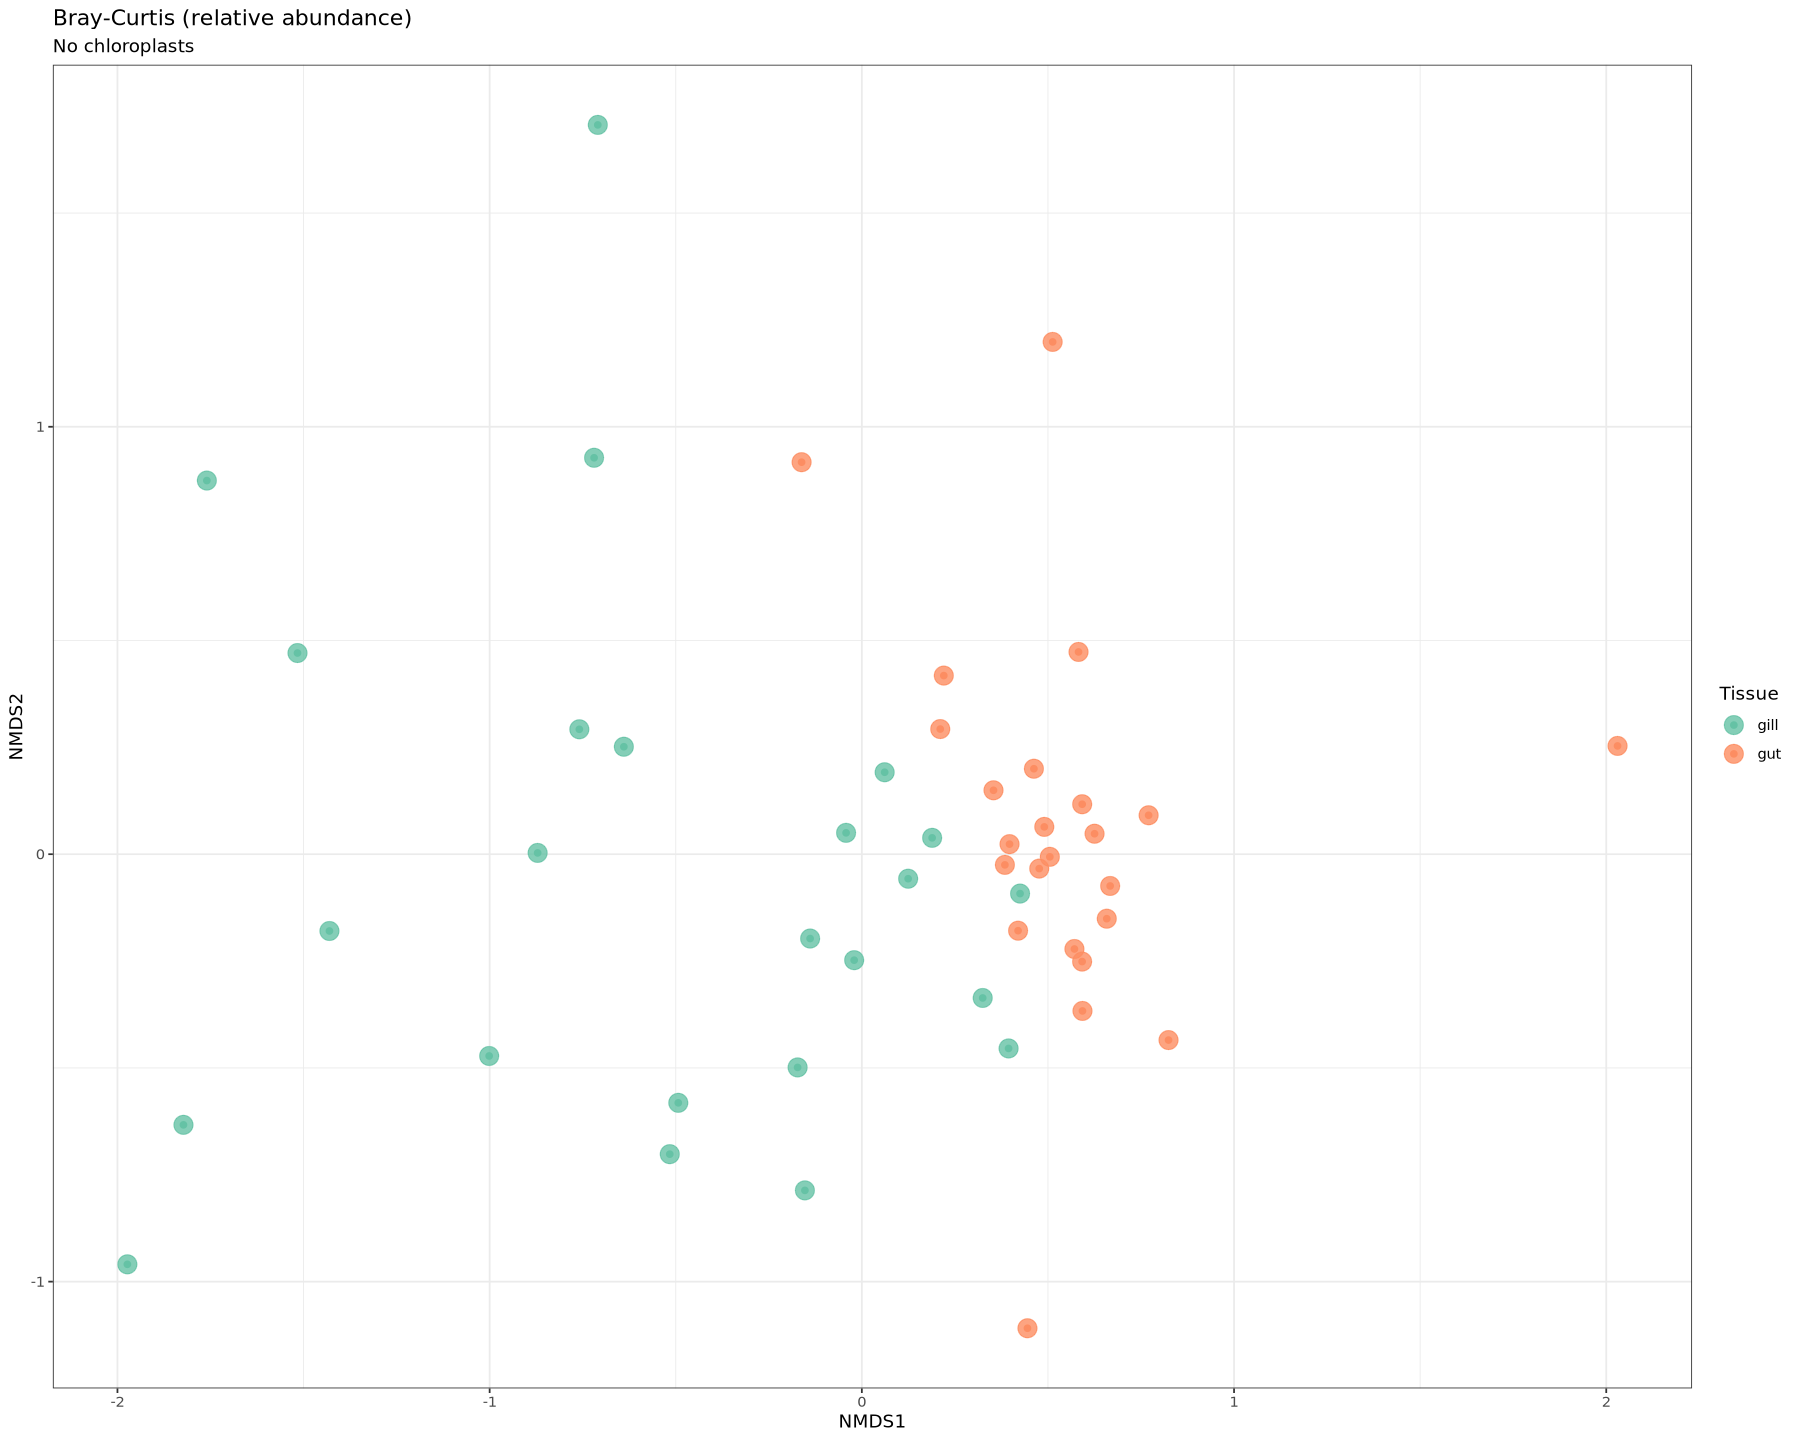

In [112]:
# Visualize nMDS
p_nmds_bray_nc <- plot_ordination(ps_nc, nmds_bray_nc, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw() 
p_nmds_bray_nc

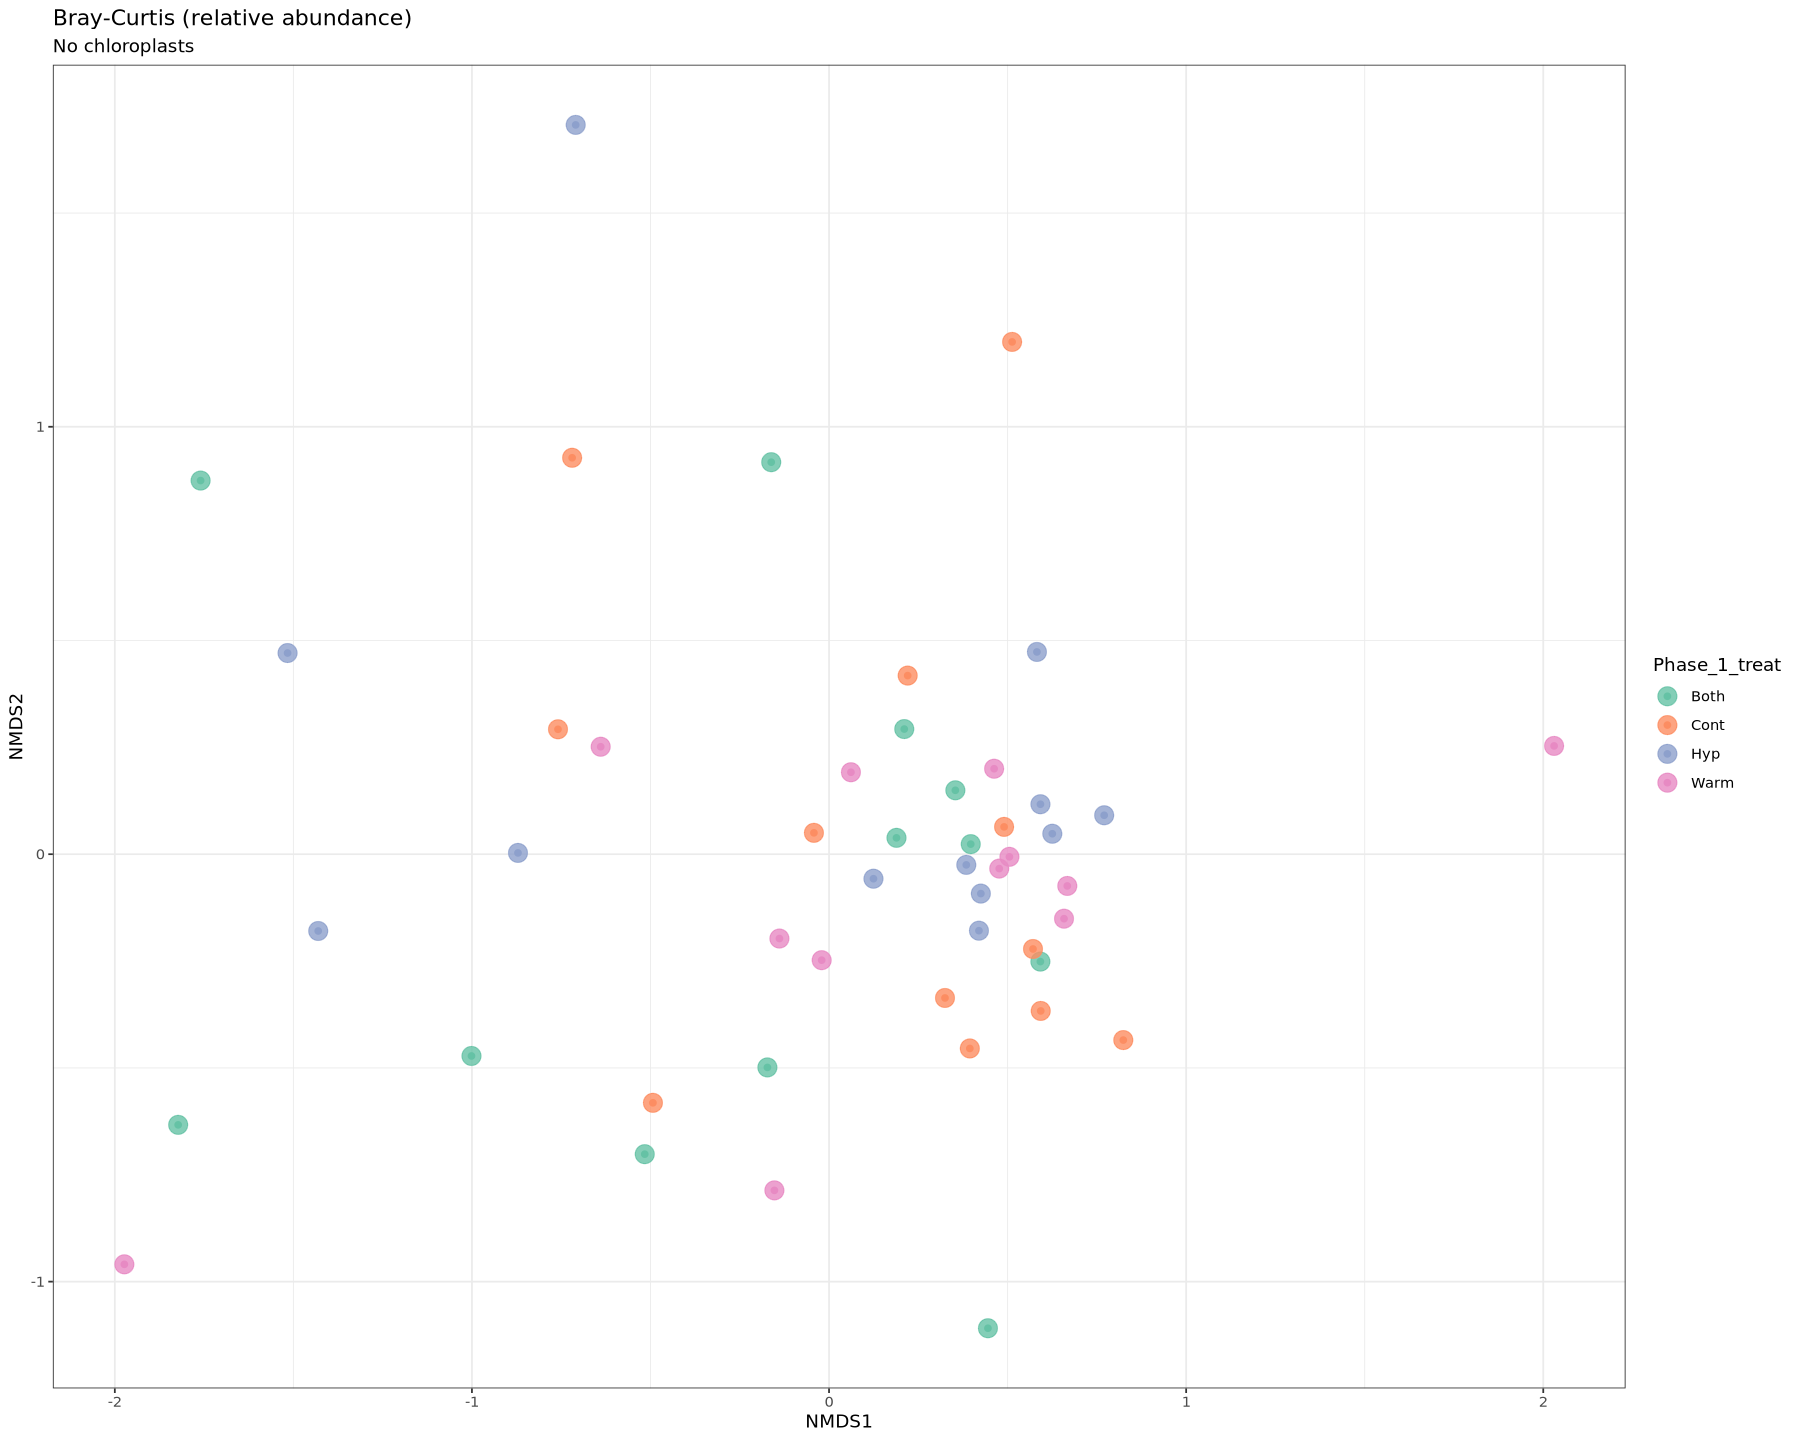

In [113]:
# Visualize nMDS
p_nmds_bray_nc <- plot_ordination(ps_nc, nmds_bray_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw() 
p_nmds_bray_nc

#### Gill

In [114]:
# Subset gill samples
ps_gill_nc <- subset_samples(ps_nc, Tissue == "gill")
ps_gill_nc <- prune_taxa(taxa_sums(ps_gill_nc) > 0, ps_gill_nc)
ps_gill_nc

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 4072 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 4072 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 4072 reference sequences ]

In [115]:
# Compute distance matrix
dist_bray_gill_nc <- phyloseq::distance(ps_gill_nc, method = "bray")

In [116]:
# Ordinate using PCoA
pcoa_bray_gill_nc <- ordinate(ps_gill_nc, method = "PCoA", distance = dist_bray_gill_nc)

# Variance explained by each axis
pcoa_bray_gill_nc$values$Relative_eig[1:5] %>% round(3)

[1] 0.201 0.154 0.121 0.096 0.056

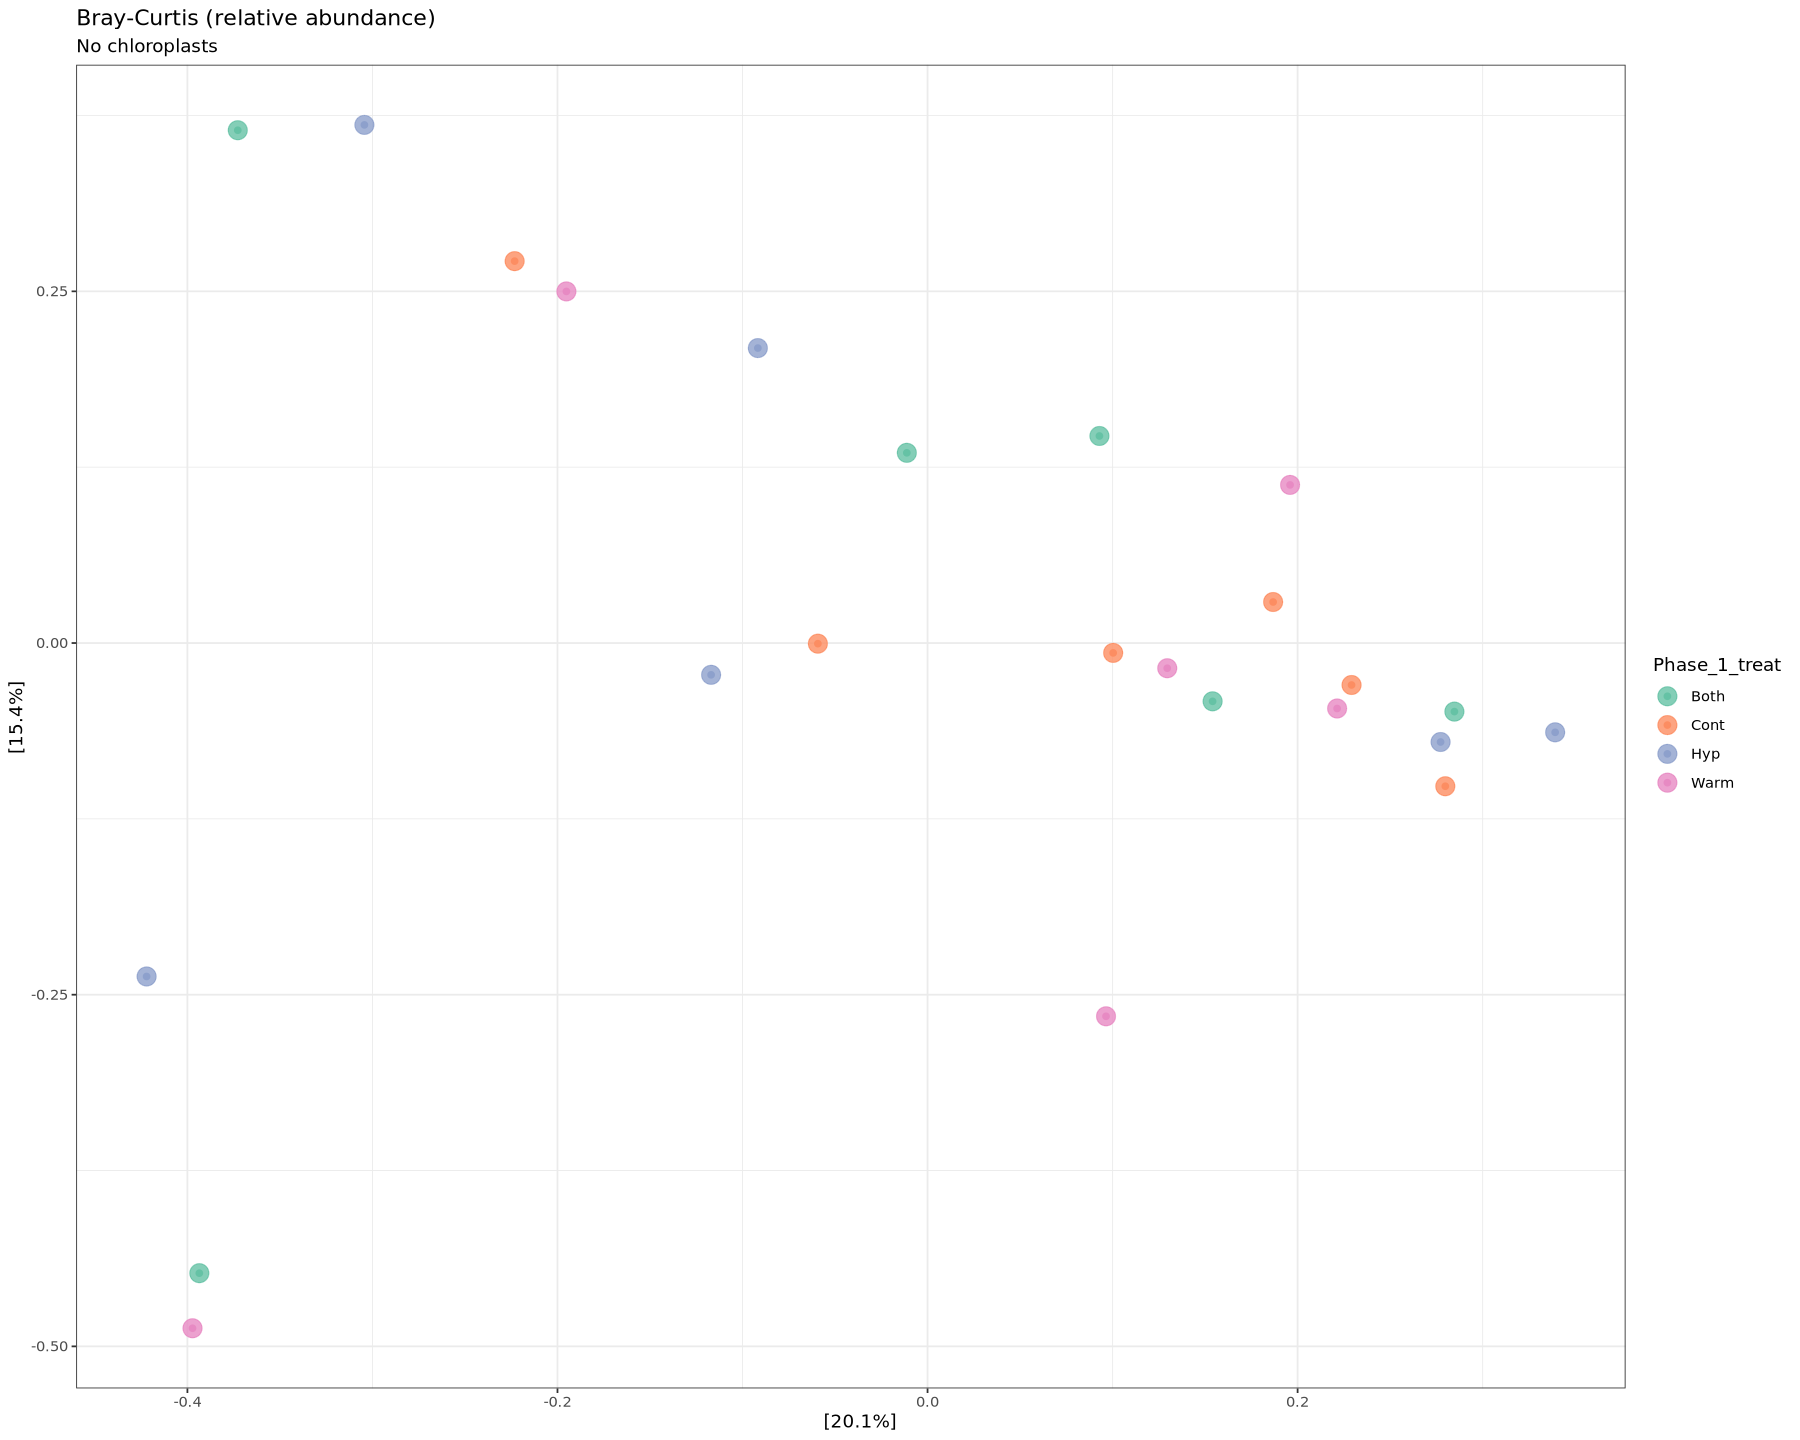

In [117]:
# Visualize PCoA
p_pcoa_bray_gill_nc <- plot_ordination(ps_gill_nc, pcoa_bray_gill_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw()
p_pcoa_bray_gill_nc

In [118]:
# Ordinate using nMDS
nmds_bray_gill_nc <- ordinate(ps_gill_nc, method = "NMDS", distance = dist_bray_gill_nc)

Run 0 stress 0.2092307 
Run 1 stress 0.2026413 
... New best solution
... Procrustes: rmse 0.1324161  max resid 0.4057583 
Run 2 stress 0.2047263 
Run 3 stress 0.2179975 
Run 4 stress 0.2079381 
Run 5 stress 0.1884687 
... New best solution
... Procrustes: rmse 0.171993  max resid 0.5694857 
Run 6 stress 0.1884686 
... New best solution
... Procrustes: rmse 0.0001671813  max resid 0.0006483569 
... Similar to previous best
Run 7 stress 0.2088724 
Run 8 stress 0.2057404 
Run 9 stress 0.2341101 
Run 10 stress 0.2057404 
Run 11 stress 0.1884685 
... New best solution
... Procrustes: rmse 8.709286e-05  max resid 0.0003300974 
... Similar to previous best
Run 12 stress 0.2047262 
Run 13 stress 0.2041782 
Run 14 stress 0.1884686 
... Procrustes: rmse 0.0002002181  max resid 0.0007838834 
... Similar to previous best
Run 15 stress 0.2002835 
Run 16 stress 0.2074771 
Run 17 stress 0.1884685 
... Procrustes: rmse 0.0001302741  max resid 0.0005109359 
... Similar to previous best
Run 18 stress 0

In [119]:
# nMDS stress value (< 0.2 okay)
nmds_bray_gill_nc$stress

[1] 0.1884685

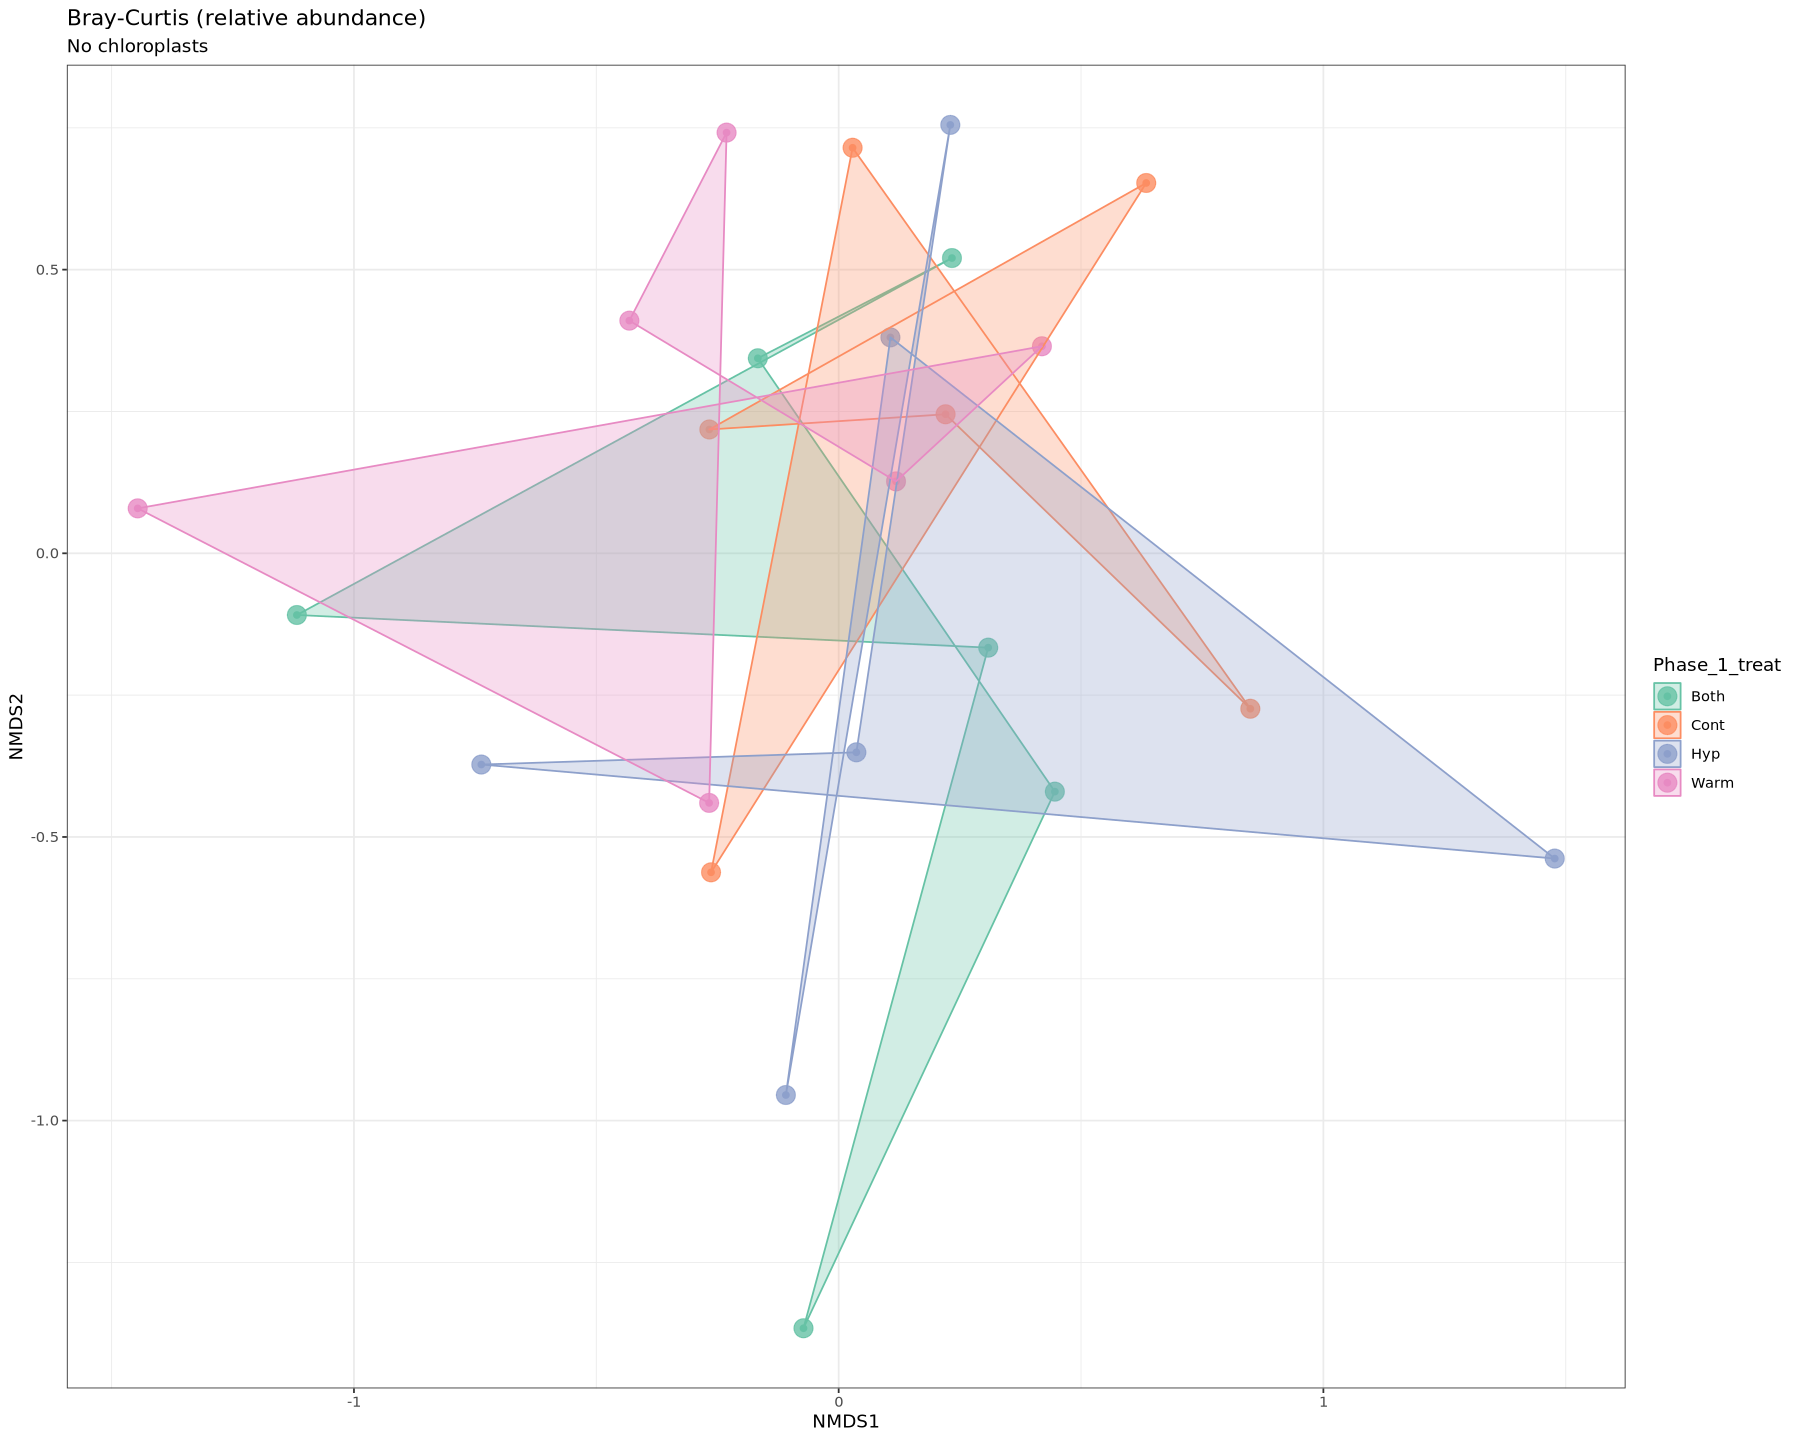

In [128]:
# Visualize nMDS
p_nmds_bray_gill_nc <- plot_ordination(ps_gill_nc, nmds_bray_gill_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw() 
p_nmds_bray_gill_nc

[1] 0.149 0.098 0.073 0.058 0.047

Run 0 stress 0.1536834 
Run 1 stress 0.1646636 
Run 2 stress 0.1536834 
... New best solution
... Procrustes: rmse 1.490384e-05  max resid 3.441266e-05 
... Similar to previous best
Run 3 stress 0.153502 
... New best solution
... Procrustes: rmse 0.01219412  max resid 0.04872104 
Run 4 stress 0.1617281 
Run 5 stress 0.153502 
... Procrustes: rmse 4.620876e-06  max resid 1.238718e-05 
... Similar to previous best
Run 6 stress 0.1536834 
... Procrustes: rmse 0.01221796  max resid 0.0492582 
Run 7 stress 0.1536834 
... Procrustes: rmse 0.012192  max resid 0.04909223 
Run 8 stress 0.153502 
... New best solution
... Procrustes: rmse 1.92649e-06  max resid 4.989667e-06 
... Similar to previous best
Run 9 stress 0.153502 
... Procrustes: rmse 3.71966e-05  max resid 0.0001301039 
... Similar to previous best
Run 10 stress 0.1536834 
... Procrustes: rmse 0.01219276  max resid 0.04909749 
Run 11 stress 0.1660655 
Run 12 stress 0.1536834 
... Procrustes: rmse 0.01218335  max resid 0.04903686 
R

[1] 0.153502

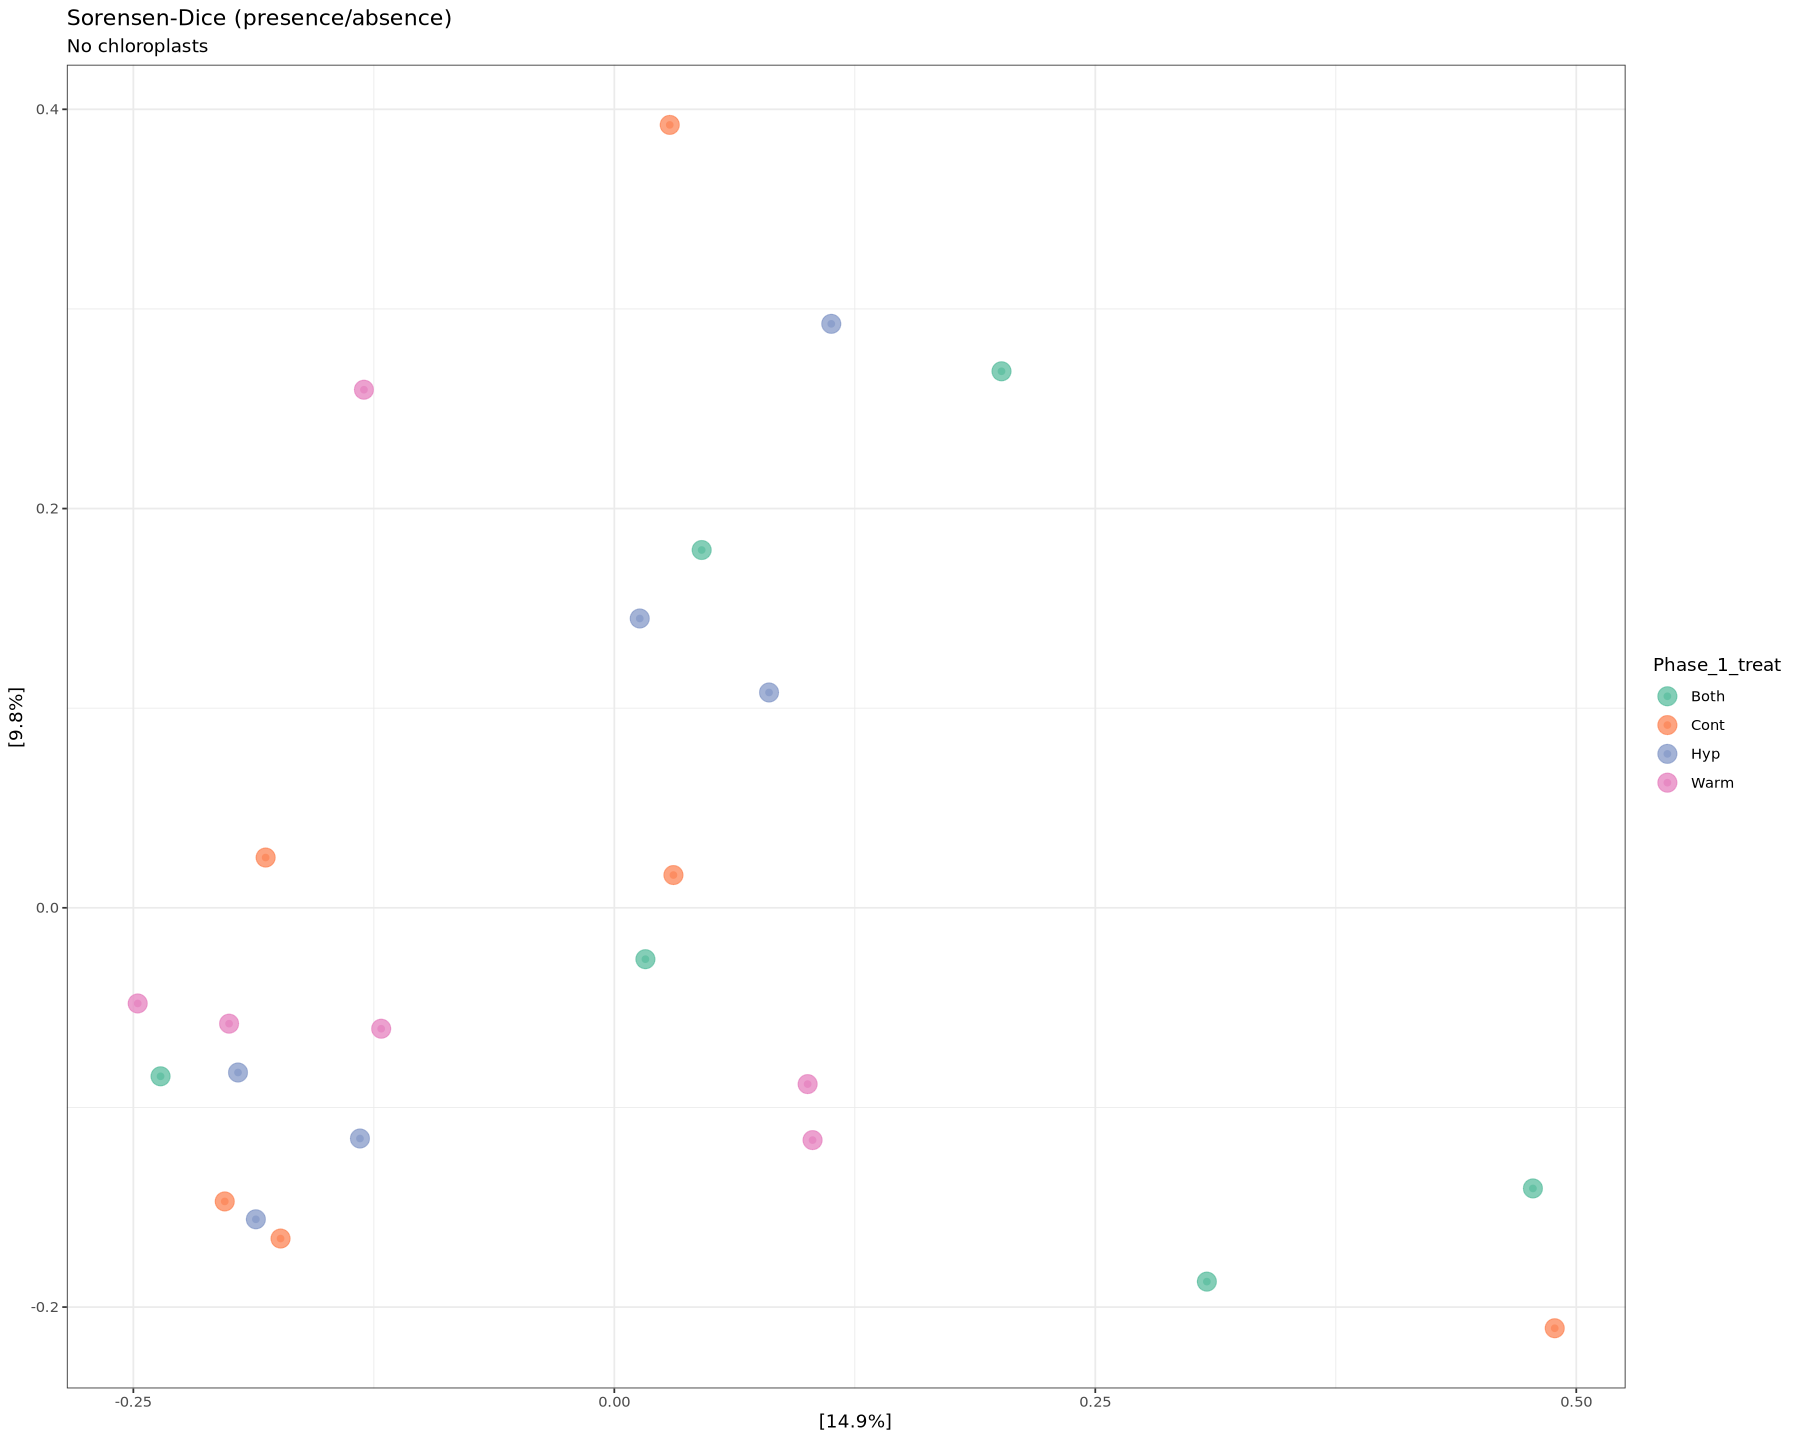

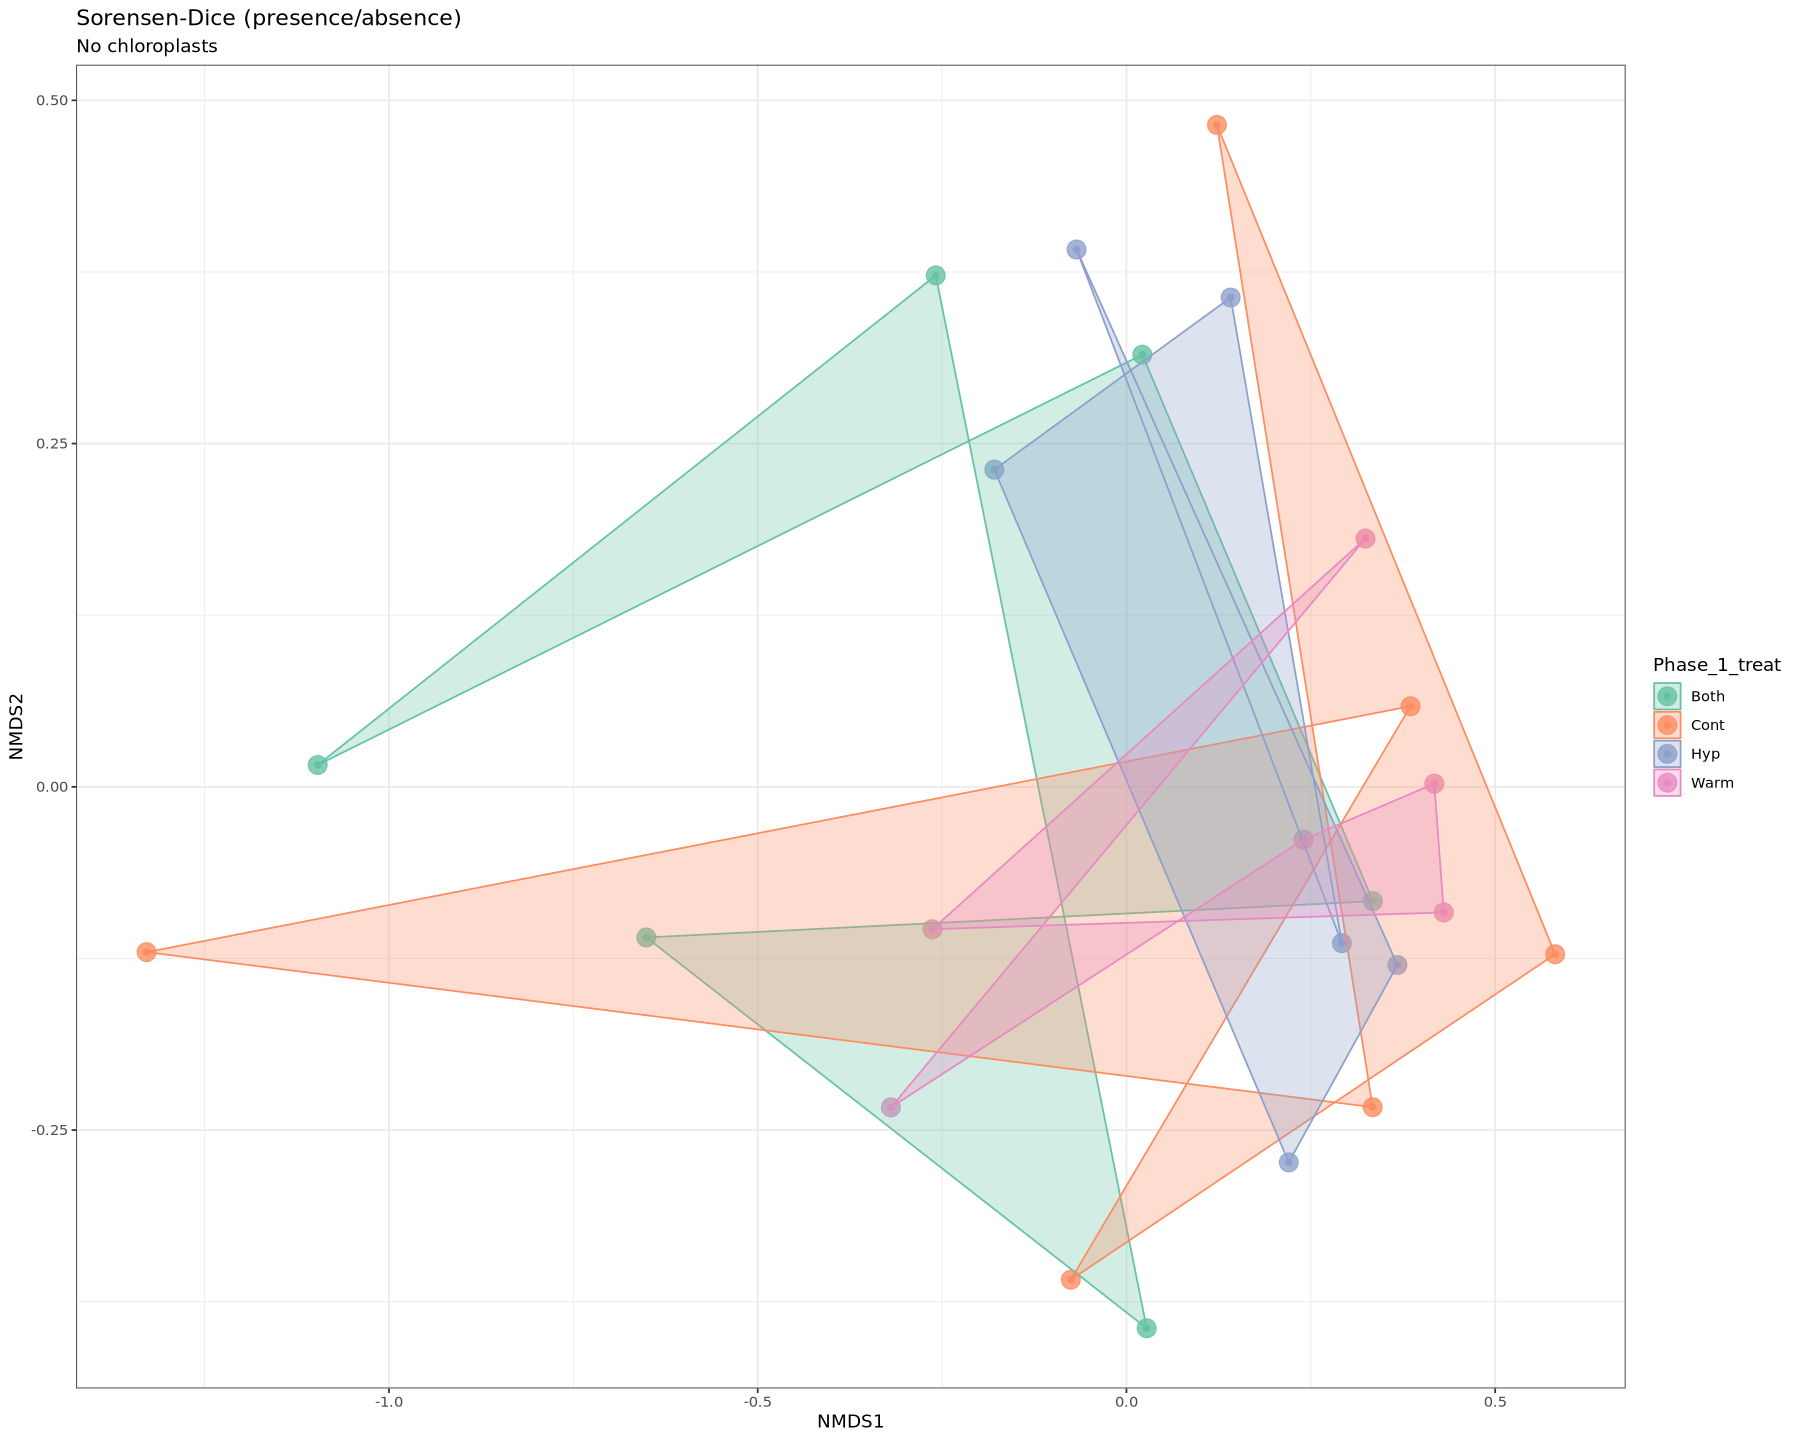

In [138]:
# Compute distance matrix using sorensen dice (presence/absence similarity as opposed to relative abundance)
dist_sdice_gill_nc <- phyloseq::distance(ps_gill_nc, method = "bray", binary = TRUE)

pcoa_sdice_gill_nc <- ordinate(ps_gill_nc, method = "PCoA", distance = dist_sdice_gill_nc)
pcoa_sdice_gill_nc$values$Relative_eig[1:5] %>% round(3)
plot_ordination(ps_gill_nc, pcoa_sdice_gill_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Sorensen-Dice (presence/absence)", subtitle = "No chloroplasts") +
    theme_bw()

nmds_sdice_gill_nc <- ordinate(ps_gill_nc, method = "NMDS", distance = dist_sdice_gill_nc)
nmds_sdice_gill_nc$stress
plot_ordination(ps_gill_nc, nmds_sdice_gill_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Sorensen-Dice (presence/absence)", subtitle = "No chloroplasts") +
    theme_bw() 

[1] 0.103 0.077 0.062 0.052 0.046

Run 0 stress 0.1536834 
Run 1 stress 0.1657419 
Run 2 stress 0.164489 
Run 3 stress 0.153502 
... New best solution
... Procrustes: rmse 0.01218926  max resid 0.04869811 
Run 4 stress 0.1536834 
... Procrustes: rmse 0.01218662  max resid 0.0490619 
Run 5 stress 0.153502 
... Procrustes: rmse 2.638639e-05  max resid 9.112049e-05 
... Similar to previous best
Run 6 stress 0.1536834 
... Procrustes: rmse 0.01220361  max resid 0.04917204 
Run 7 stress 0.153502 
... New best solution
... Procrustes: rmse 8.873047e-06  max resid 2.772462e-05 
... Similar to previous best
Run 8 stress 0.1660653 
Run 9 stress 0.1536834 
... Procrustes: rmse 0.01218767  max resid 0.04907048 
Run 10 stress 0.1631362 
Run 11 stress 0.153502 
... Procrustes: rmse 1.660826e-05  max resid 5.318001e-05 
... Similar to previous best
Run 12 stress 0.153502 
... Procrustes: rmse 2.230851e-05  max resid 7.556787e-05 
... Similar to previous best
Run 13 stress 0.1536834 
... Procrustes: rmse 0.01219537  max resid 0.049115

[1] 0.153502

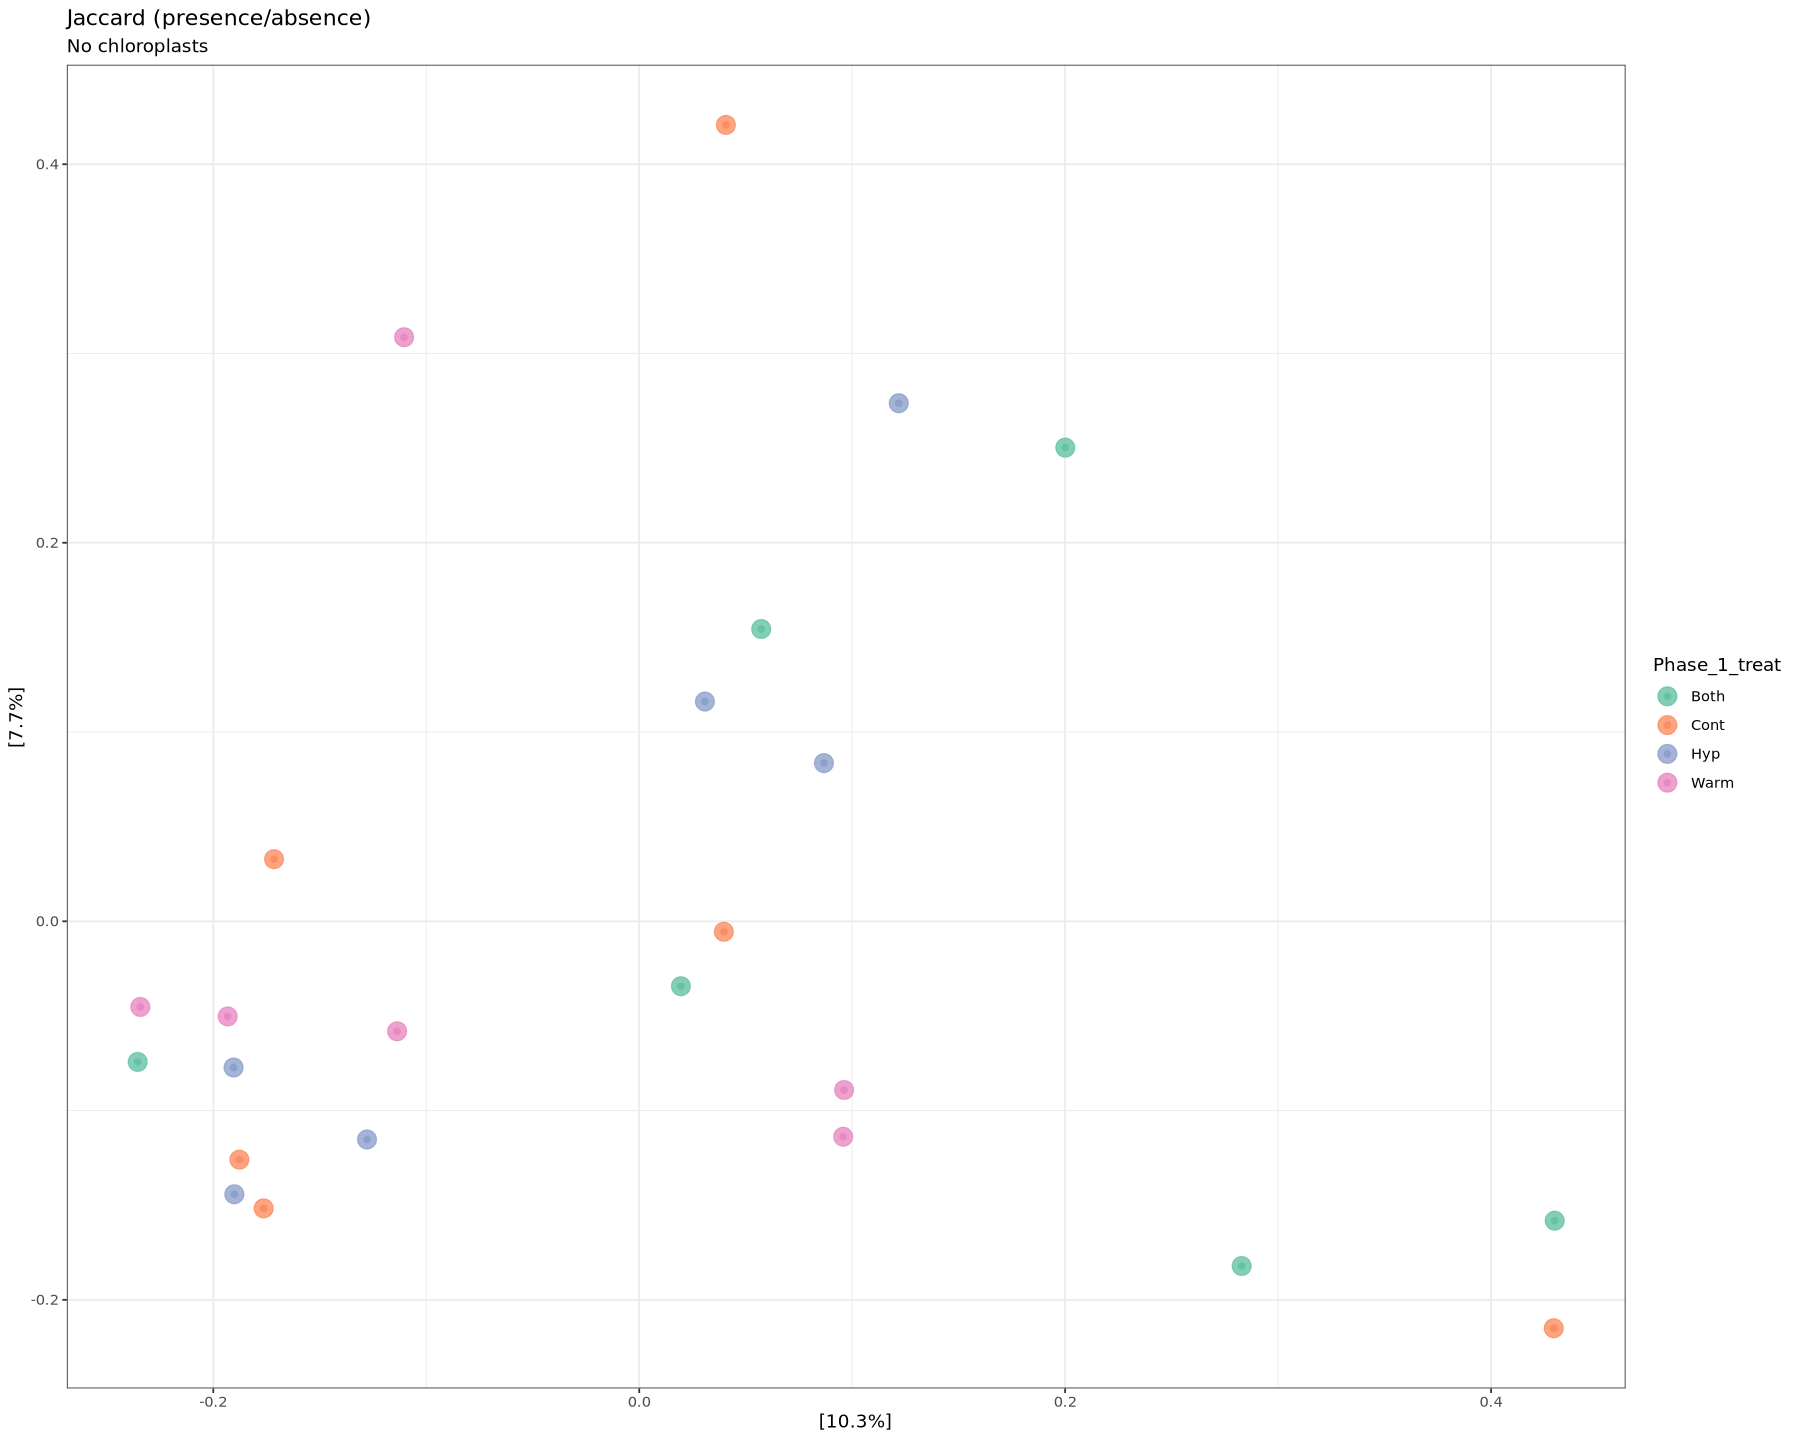

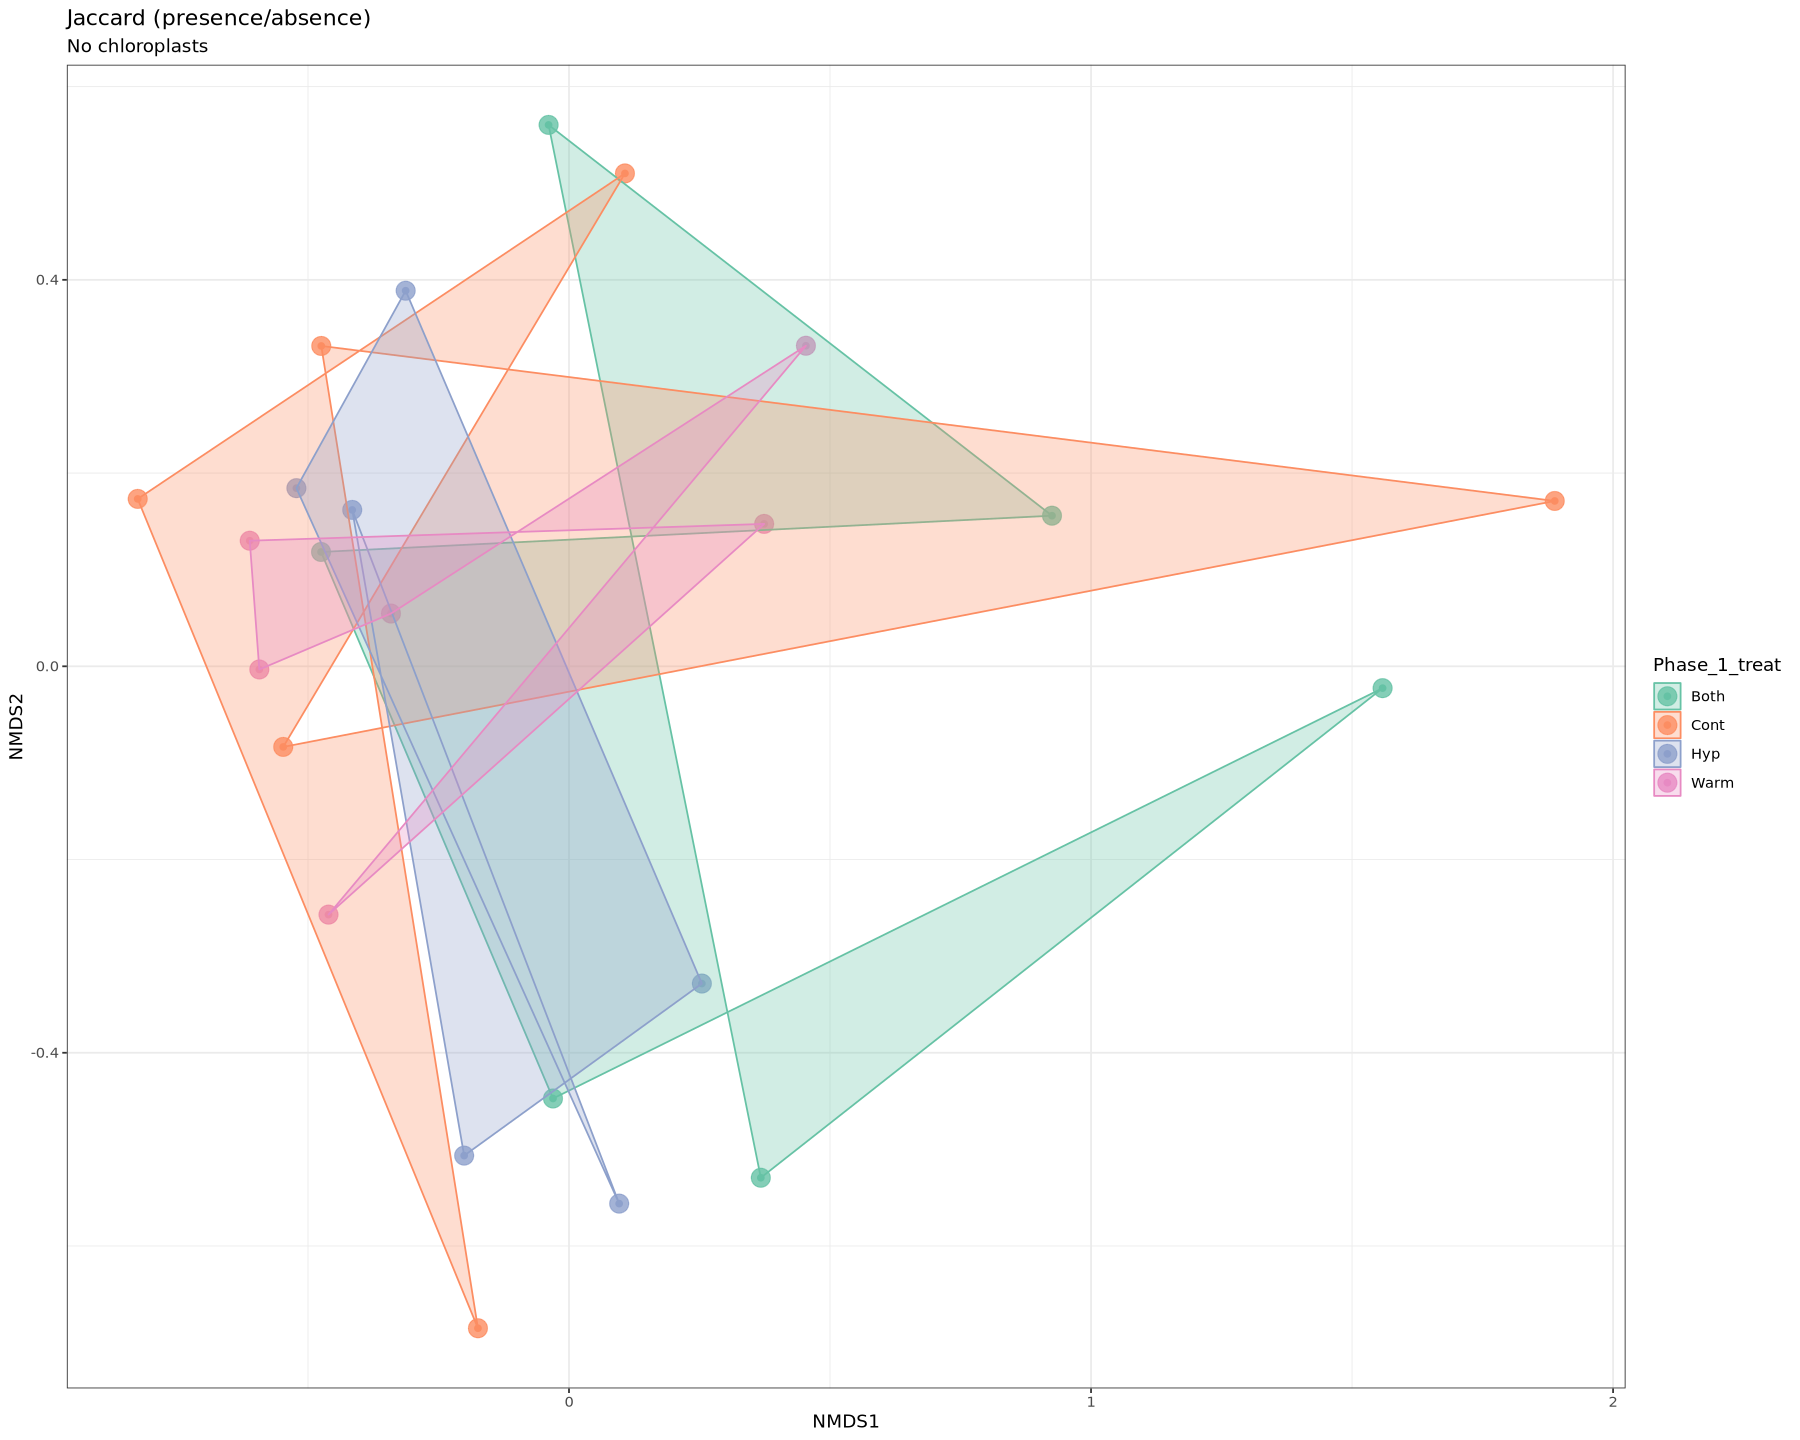

In [139]:
# Compute distance matrix using jaccard (presence/absence similarity as opposed to relative abundance)
dist_jaccard_gill_nc <- phyloseq::distance(ps_gill_nc, method = "jaccard", binary = TRUE)

pcoa_jaccard_gill_nc <- ordinate(ps_gill_nc, method = "PCoA", distance = dist_jaccard_gill_nc)
pcoa_jaccard_gill_nc$values$Relative_eig[1:5] %>% round(3)
plot_ordination(ps_gill_nc, pcoa_jaccard_gill_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Jaccard (presence/absence)", subtitle = "No chloroplasts") +
    theme_bw()

nmds_jaccard_gill_nc <- ordinate(ps_gill_nc, method = "NMDS", distance = dist_jaccard_gill_nc)
nmds_jaccard_gill_nc$stress
plot_ordination(ps_gill_nc, nmds_jaccard_gill_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Jaccard (presence/absence)", subtitle = "No chloroplasts") +
    theme_bw() 

Run 0 stress 0.07778996 
Run 1 stress 0.07940704 
Run 2 stress 0.07733196 
... New best solution
... Procrustes: rmse 0.02524687  max resid 0.07636727 
Run 3 stress 0.08592986 
Run 4 stress 0.07887343 
Run 5 stress 0.0765204 
... New best solution
... Procrustes: rmse 0.01209725  max resid 0.05352136 
Run 6 stress 0.07779013 
Run 7 stress 0.0803954 
Run 8 stress 0.07940708 
Run 9 stress 0.07635086 
... New best solution
... Procrustes: rmse 0.01314587  max resid 0.0593576 
Run 10 stress 0.08593001 
Run 11 stress 0.08033367 
Run 12 stress 0.07779005 
Run 13 stress 0.07779023 
Run 14 stress 0.07887333 
Run 15 stress 0.08130105 
Run 16 stress 0.0788733 
Run 17 stress 0.0826456 
Run 18 stress 0.07779005 
Run 19 stress 0.08039538 
Run 20 stress 0.07887326 
*** Best solution was not repeated -- monoMDS stopping criteria:
    20: stress ratio > sratmax


[1] 0.07635086

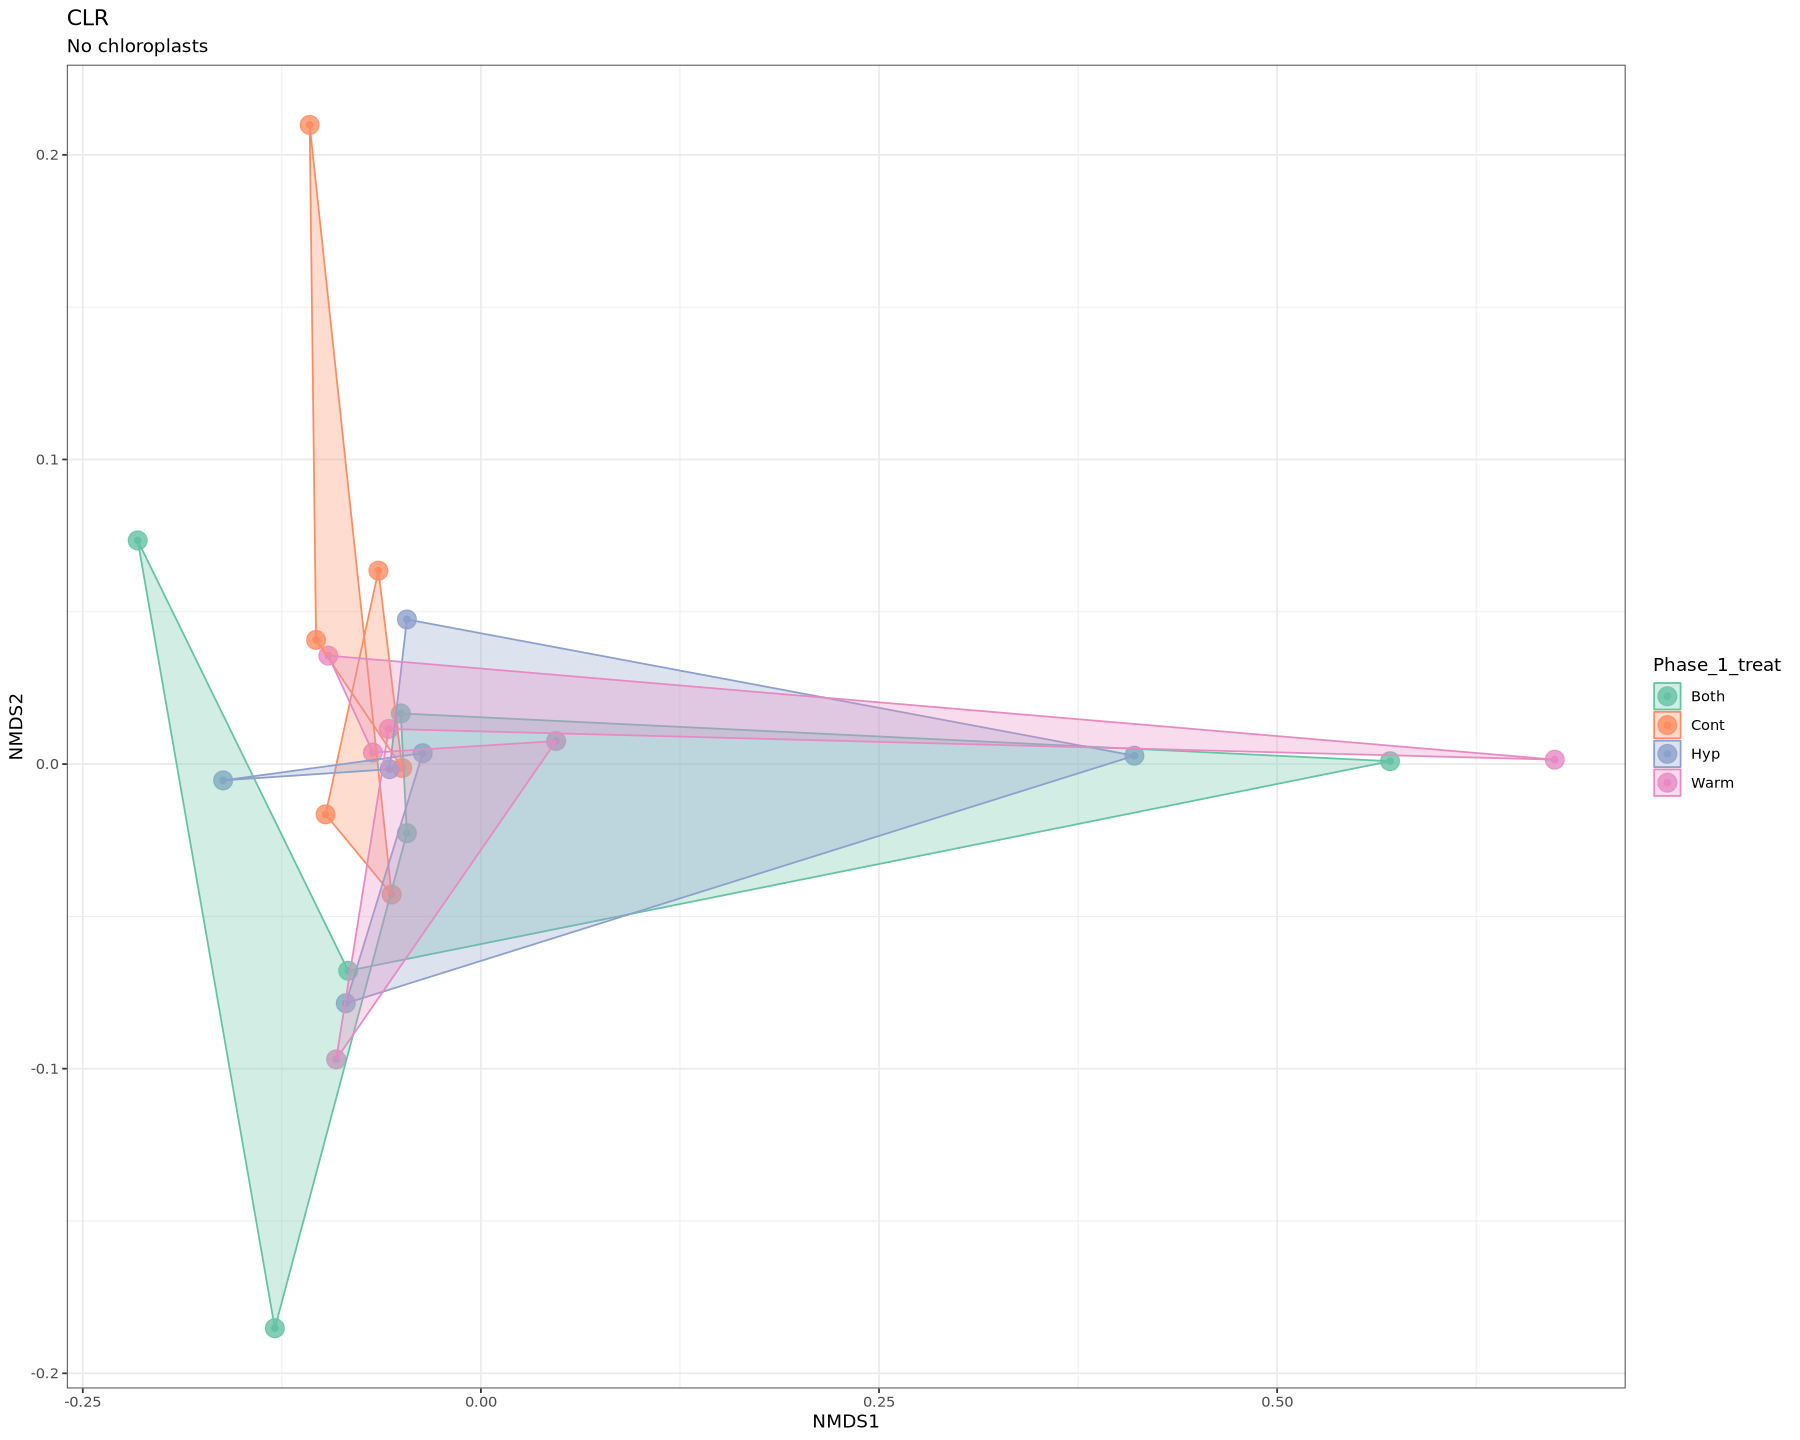

In [147]:
## CLR-transformation
clr_matrix <- t(microbiome::abundances(ps_gill_nc))
dist_aitchison <- dist(clr_matrix, method = "euclidean")

ord_aitch <- ordinate(ps_gill_nc, method = "NMDS", distance = dist_aitchison)
ord_aitch$stress

plot_ordination(ps_gill_nc, ord_aitch, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "CLR", subtitle = "No chloroplasts") +
    theme_bw() 

#### Gut

In [121]:
# Subset gut samples in new phyloseq object
ps_gut_nc <- subset_samples(ps_nc, Tissue == "gut")
ps_gut_nc <- prune_taxa(taxa_sums(ps_gut_nc) > 0, ps_gut_nc)
ps_gut_nc

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 6608 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 6608 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 6608 reference sequences ]

In [122]:
# Compute distance matrix
dist_bray_gut_nc <- phyloseq::distance(ps_gut_nc, method = "bray")

In [123]:
# Ordinate using PCoA
pcoa_bray_gut_nc <- ordinate(ps_gut_nc, method = "PCoA", distance = dist_bray_gut_nc)

# Variance explained by each axis
pcoa_bray_gut_nc$values$Relative_eig[1:5] %>% round(3)

[1] 0.181 0.145 0.095 0.083 0.076

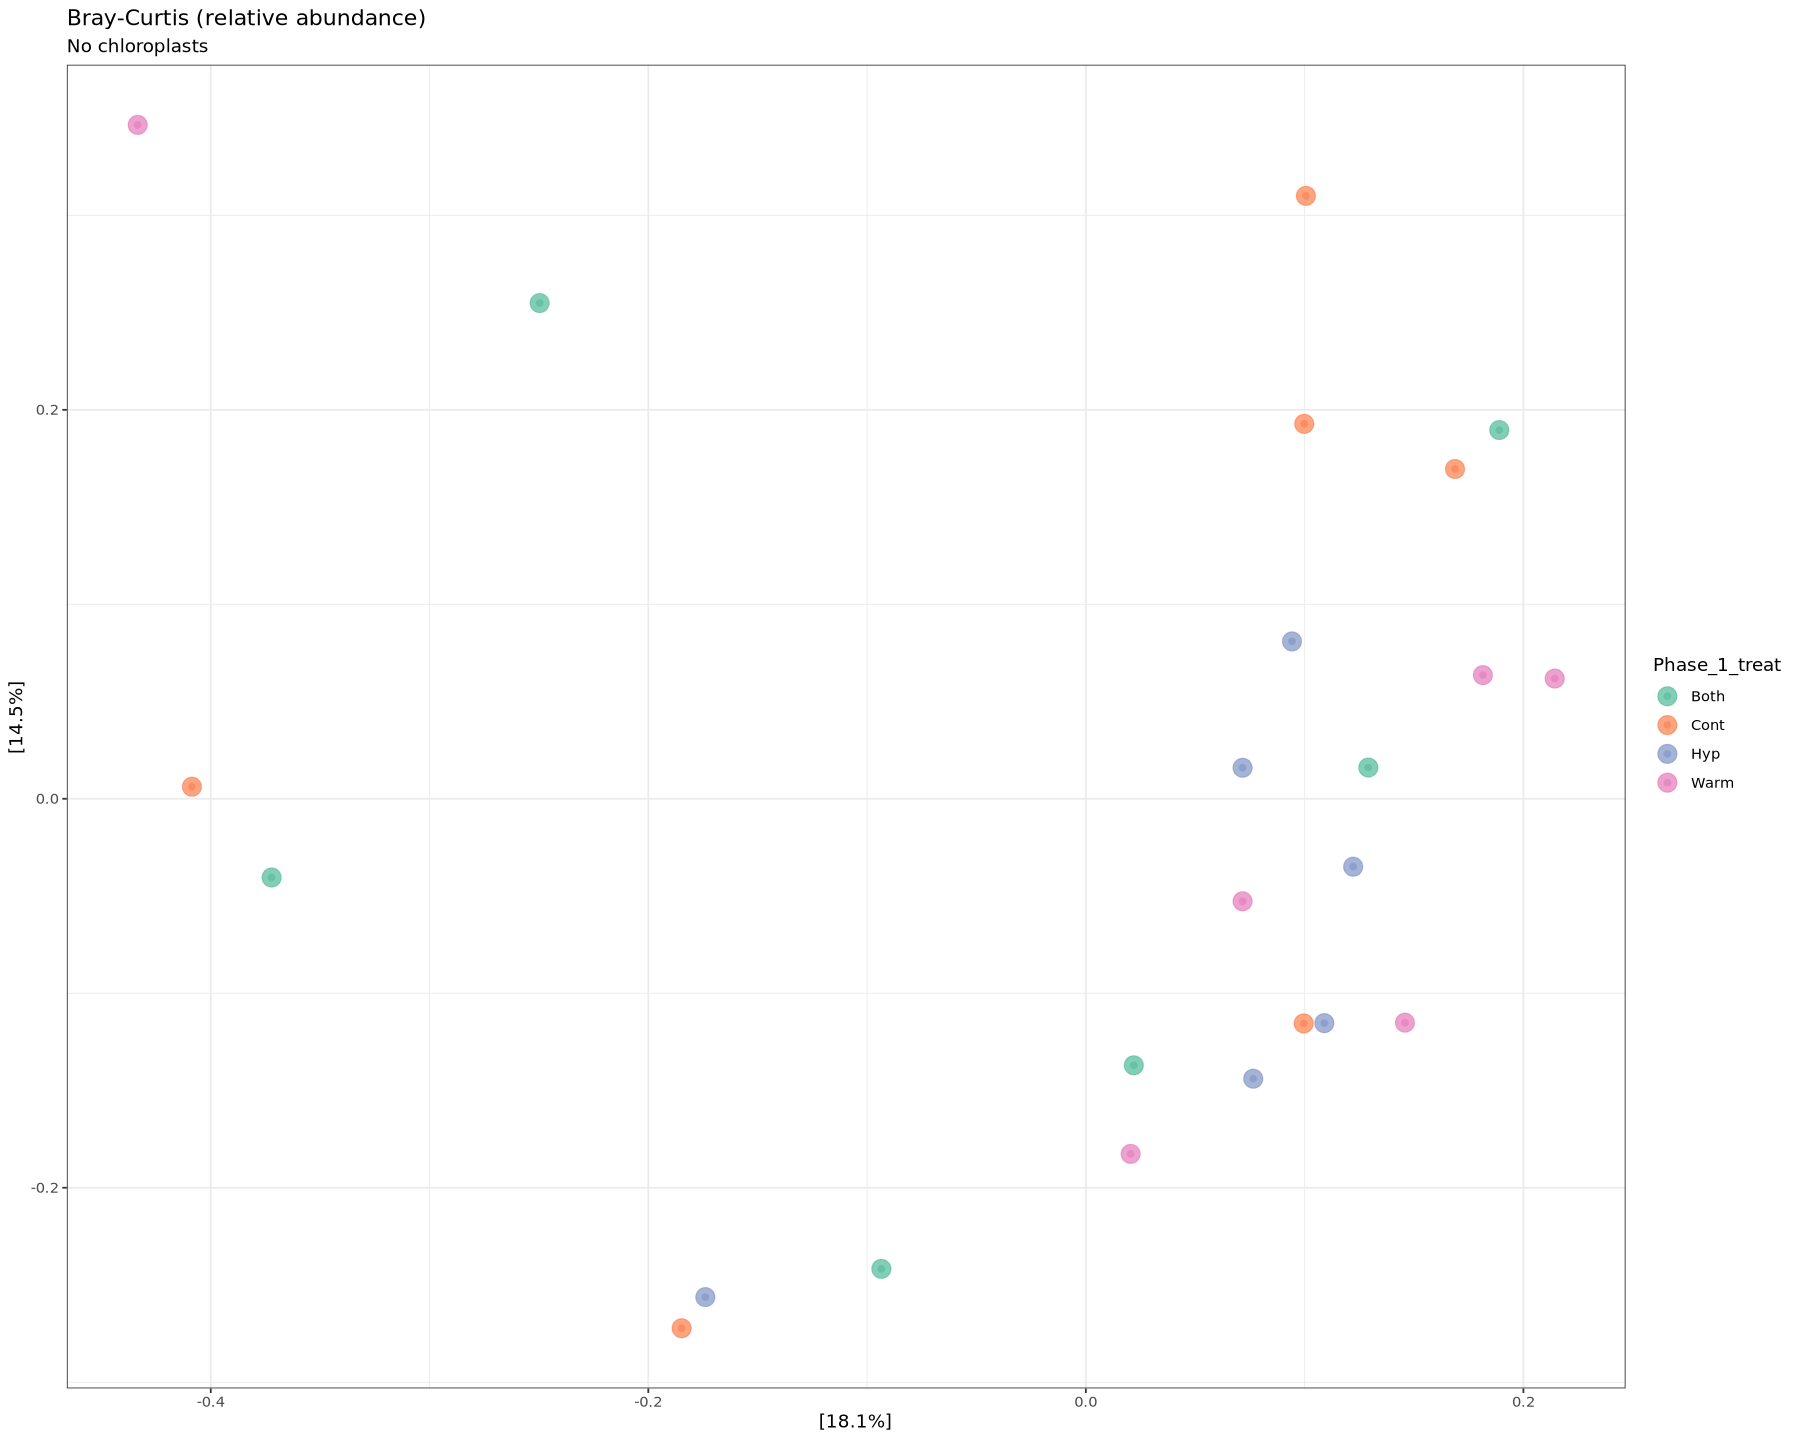

In [129]:
# Visualize PCoA
p_pcoa_bray_gut_nc <- plot_ordination(ps_gut_nc, pcoa_bray_gut_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw()
p_pcoa_bray_gut_nc

In [125]:
# Ordinate using nMDS
nmds_bray_gut_nc <- ordinate(ps_gut_nc, method = "NMDS", distance = dist_bray_gut_nc)

Run 0 stress 0.09010494 
Run 1 stress 0.1384802 
Run 2 stress 0.09651342 
Run 3 stress 0.09010459 
... New best solution
... Procrustes: rmse 0.0001714768  max resid 0.0005553425 
... Similar to previous best
Run 4 stress 0.1108123 
Run 5 stress 0.0958516 
Run 6 stress 0.1476901 
Run 7 stress 0.1280205 
Run 8 stress 0.3840919 
Run 9 stress 0.09982667 
Run 10 stress 0.1038763 
Run 11 stress 0.1136921 
Run 12 stress 0.1136923 
Run 13 stress 0.09010456 
... New best solution
... Procrustes: rmse 2.855479e-05  max resid 9.15207e-05 
... Similar to previous best
Run 14 stress 0.1038768 
Run 15 stress 0.1181038 
Run 16 stress 0.09746871 
Run 17 stress 0.1136919 
Run 18 stress 0.09585196 
Run 19 stress 0.1200362 
Run 20 stress 0.1038762 
*** Best solution repeated 1 times


In [126]:
# nMDS stress value (< 0.2 okay)
nmds_bray_gut_nc$stress

[1] 0.09010456

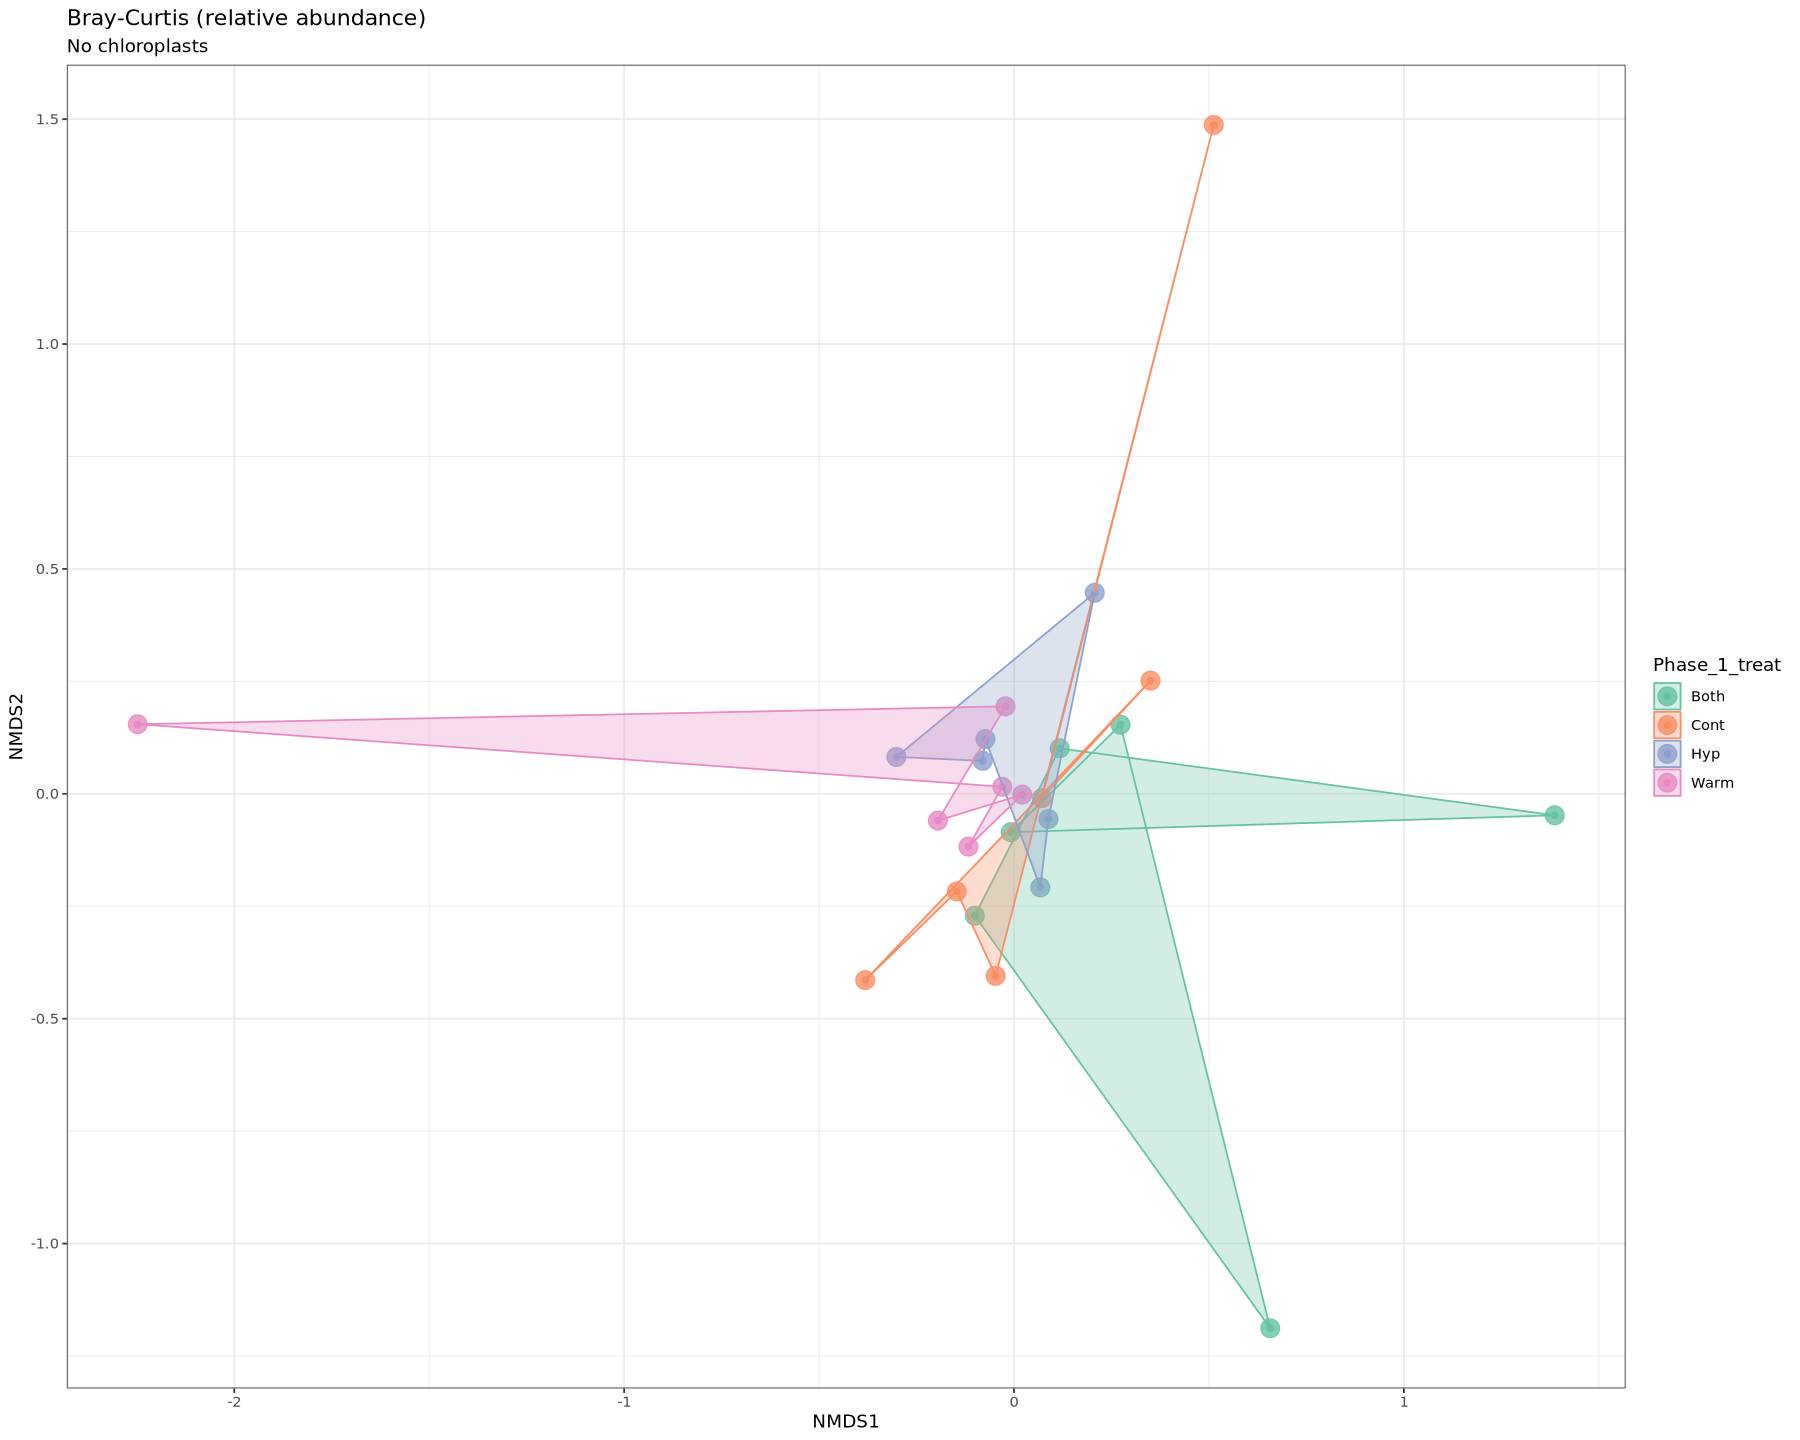

In [130]:
# Visualize nMDS
p_nmds_bray_gut_nc <- plot_ordination(ps_gut_nc, nmds_bray_gut_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "No chloroplasts") +
    theme_bw() 
p_nmds_bray_gut_nc

[1] 0.160 0.087 0.063 0.058 0.046

Run 0 stress 0.1462919 
Run 1 stress 0.1780785 
Run 2 stress 0.1462919 
... New best solution
... Procrustes: rmse 7.772547e-06  max resid 2.057838e-05 
... Similar to previous best
Run 3 stress 0.1780786 
Run 4 stress 0.1607343 
Run 5 stress 0.1462919 
... Procrustes: rmse 1.613077e-05  max resid 4.302476e-05 
... Similar to previous best
Run 6 stress 0.1775766 
Run 7 stress 0.1462919 
... Procrustes: rmse 8.25094e-06  max resid 2.194106e-05 
... Similar to previous best
Run 8 stress 0.1462919 
... Procrustes: rmse 2.058184e-06  max resid 5.702288e-06 
... Similar to previous best
Run 9 stress 0.1503211 
Run 10 stress 0.1780785 
Run 11 stress 0.1895683 
Run 12 stress 0.1462919 
... Procrustes: rmse 6.86607e-06  max resid 1.789623e-05 
... Similar to previous best
Run 13 stress 0.1462919 
... Procrustes: rmse 4.047302e-06  max resid 1.17441e-05 
... Similar to previous best
Run 14 stress 0.1462919 
... Procrustes: rmse 8.596379e-06  max resid 2.322164e-05 
... Similar to previous best


[1] 0.1462919

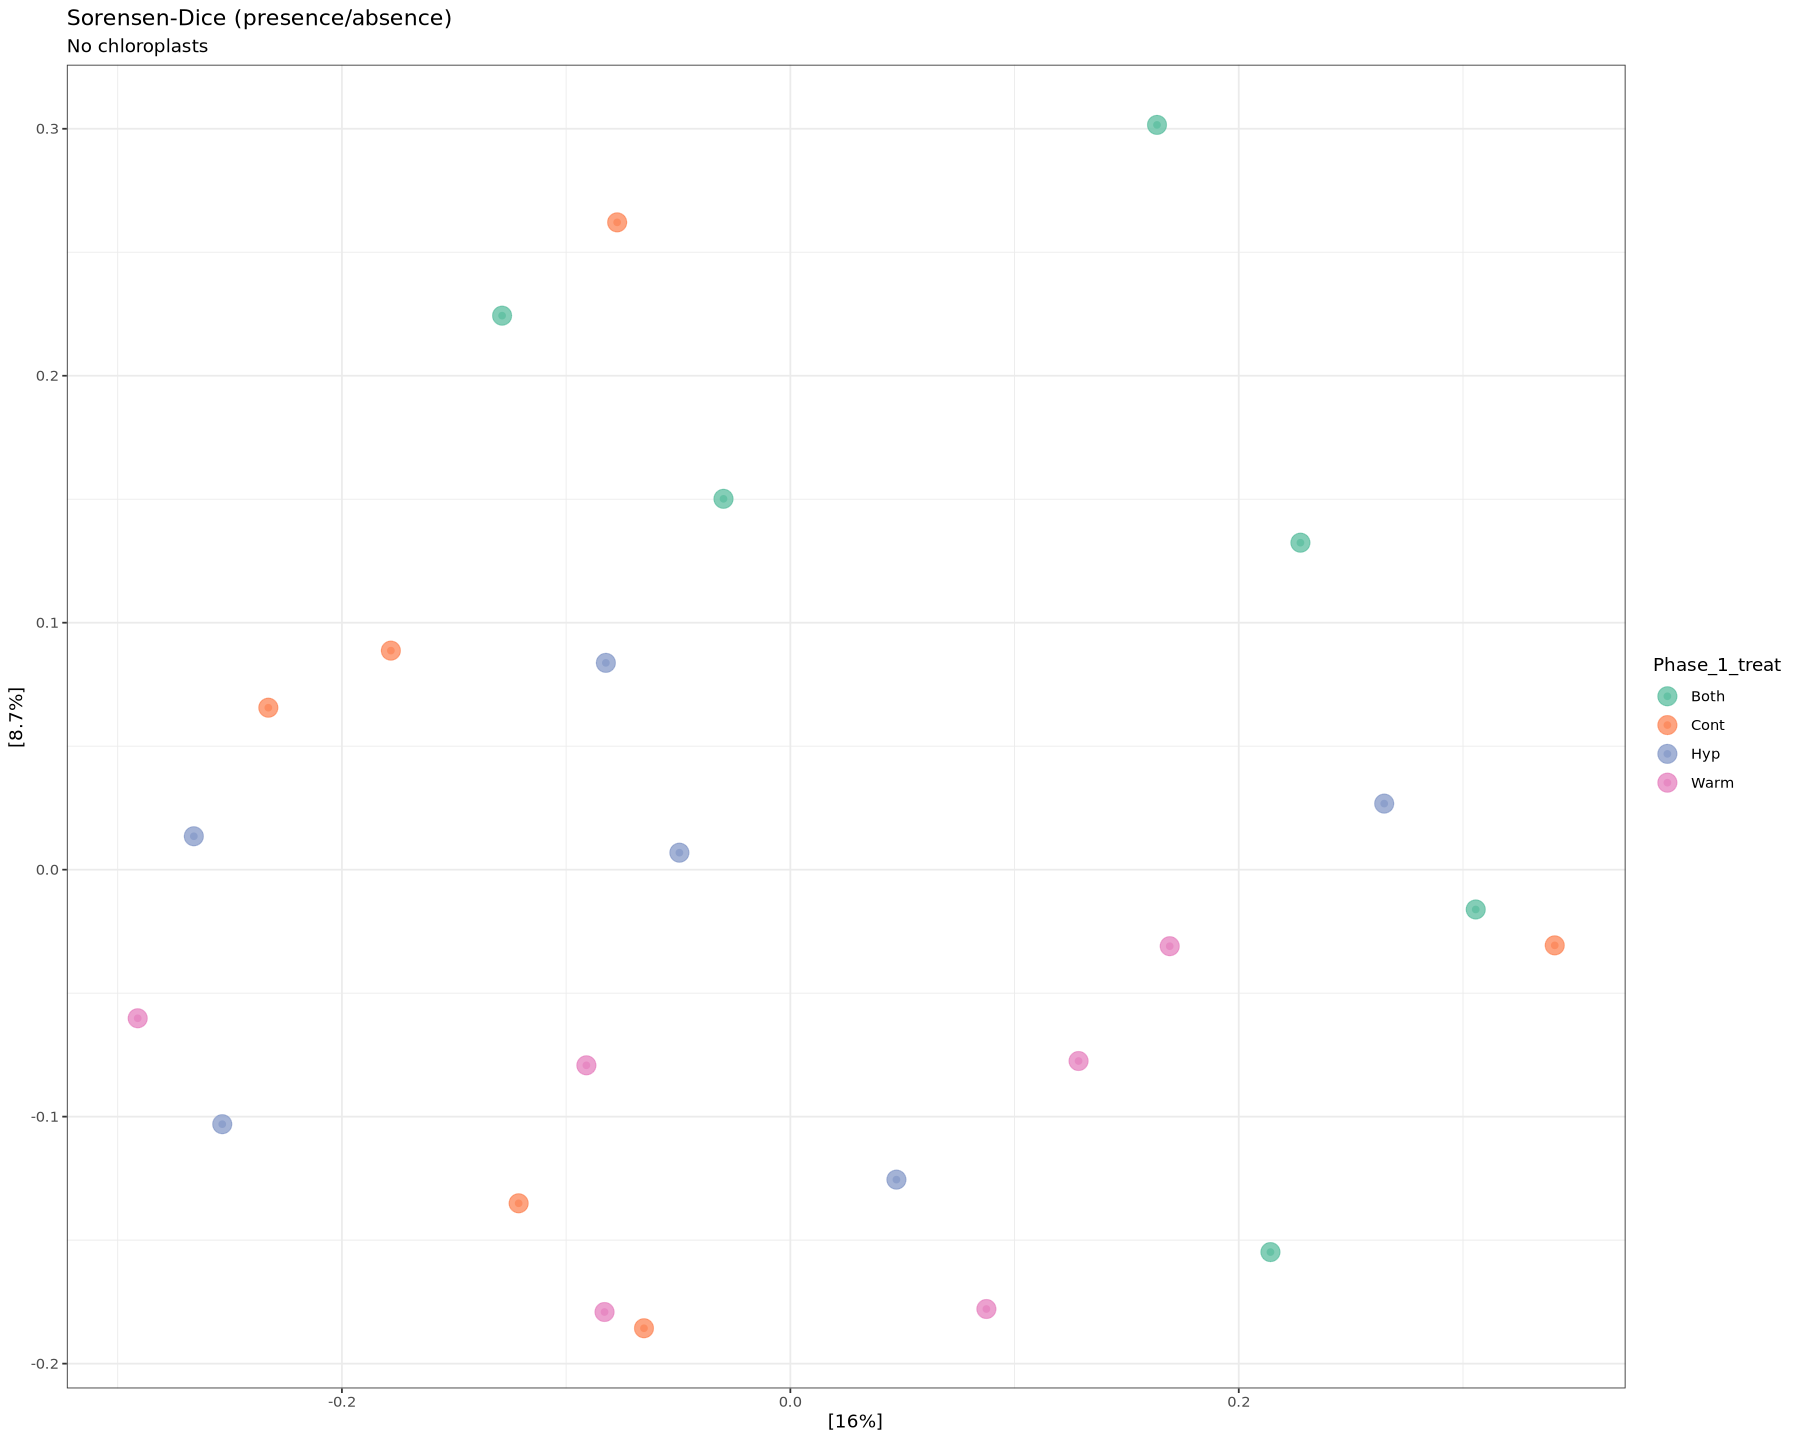

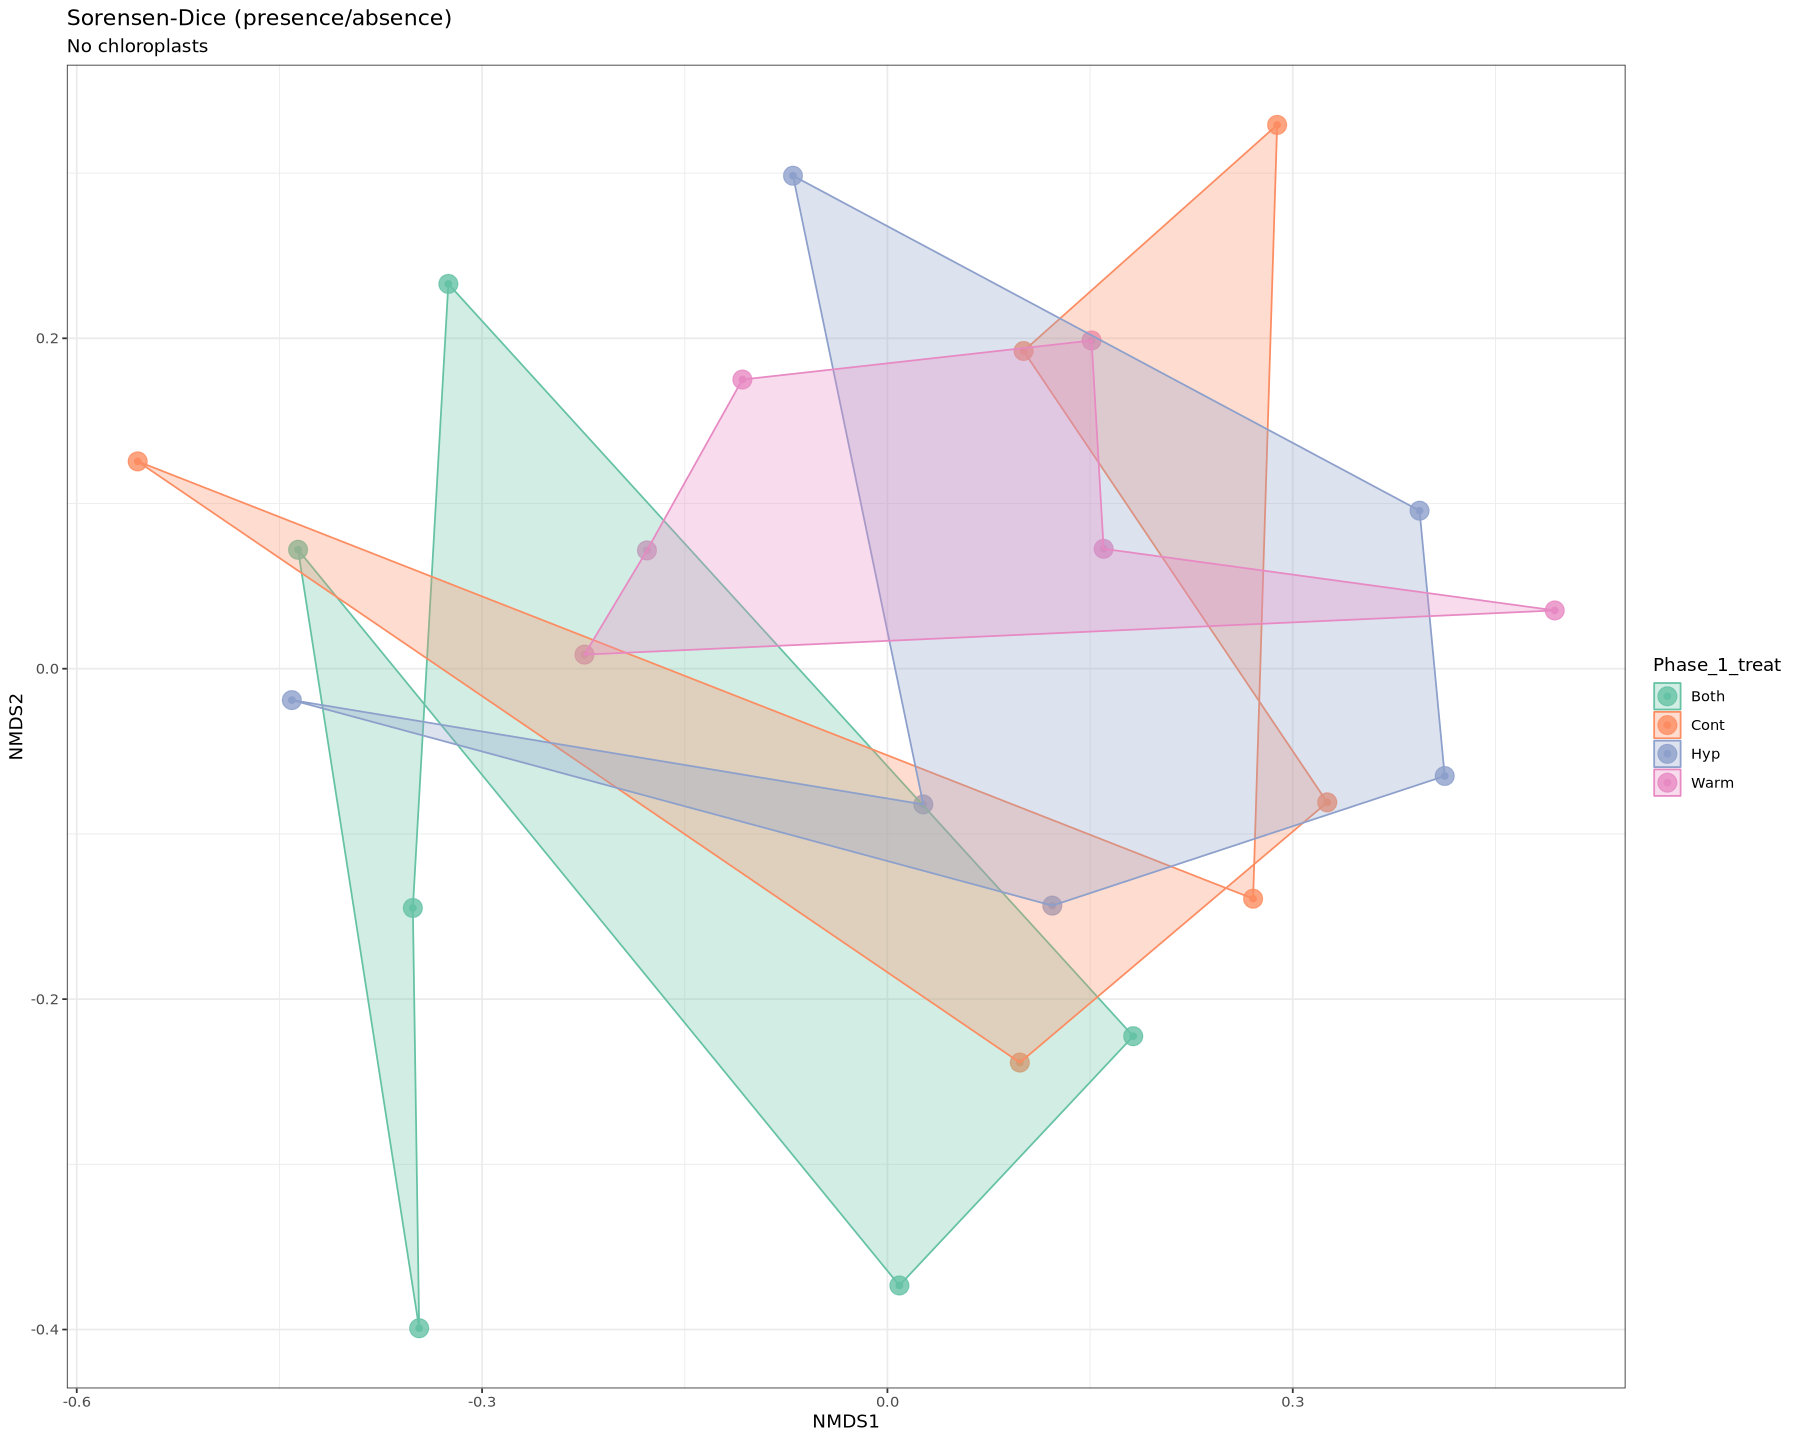

In [140]:
# Compute distance matrix using sorensen dice (presence/absence similarity as opposed to relative abundance)
dist_sdice_gut_nc <- phyloseq::distance(ps_gut_nc, method = "bray", binary = TRUE)

pcoa_sdice_gut_nc <- ordinate(ps_gut_nc, method = "PCoA", distance = dist_sdice_gut_nc)
pcoa_sdice_gut_nc$values$Relative_eig[1:5] %>% round(3)
plot_ordination(ps_gut_nc, pcoa_sdice_gut_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Sorensen-Dice (presence/absence)", subtitle = "No chloroplasts") +
    theme_bw()

nmds_sdice_gut_nc <- ordinate(ps_gut_nc, method = "NMDS", distance = dist_sdice_gut_nc)
nmds_sdice_gut_nc$stress
plot_ordination(ps_gut_nc, nmds_sdice_gut_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Sorensen-Dice (presence/absence)", subtitle = "No chloroplasts") +
    theme_bw() 

# tbd

In [96]:
# Compute distance matrix
dist_bray_gut_nc <- phyloseq::distance(ps_gut_nc, method = "bray")

In [97]:
# Ordinate using PCoA
pcoa_bray_gut_nc <- ordinate(ps_gut_nc, method = "PCoA", distance = dist_bray_gut_nc)

# Variance explained by each axis
pcoa_bray_gut_nc$values$Relative_eig[1:5] %>% round(3)

[1] 0.181 0.145 0.095 0.083 0.076

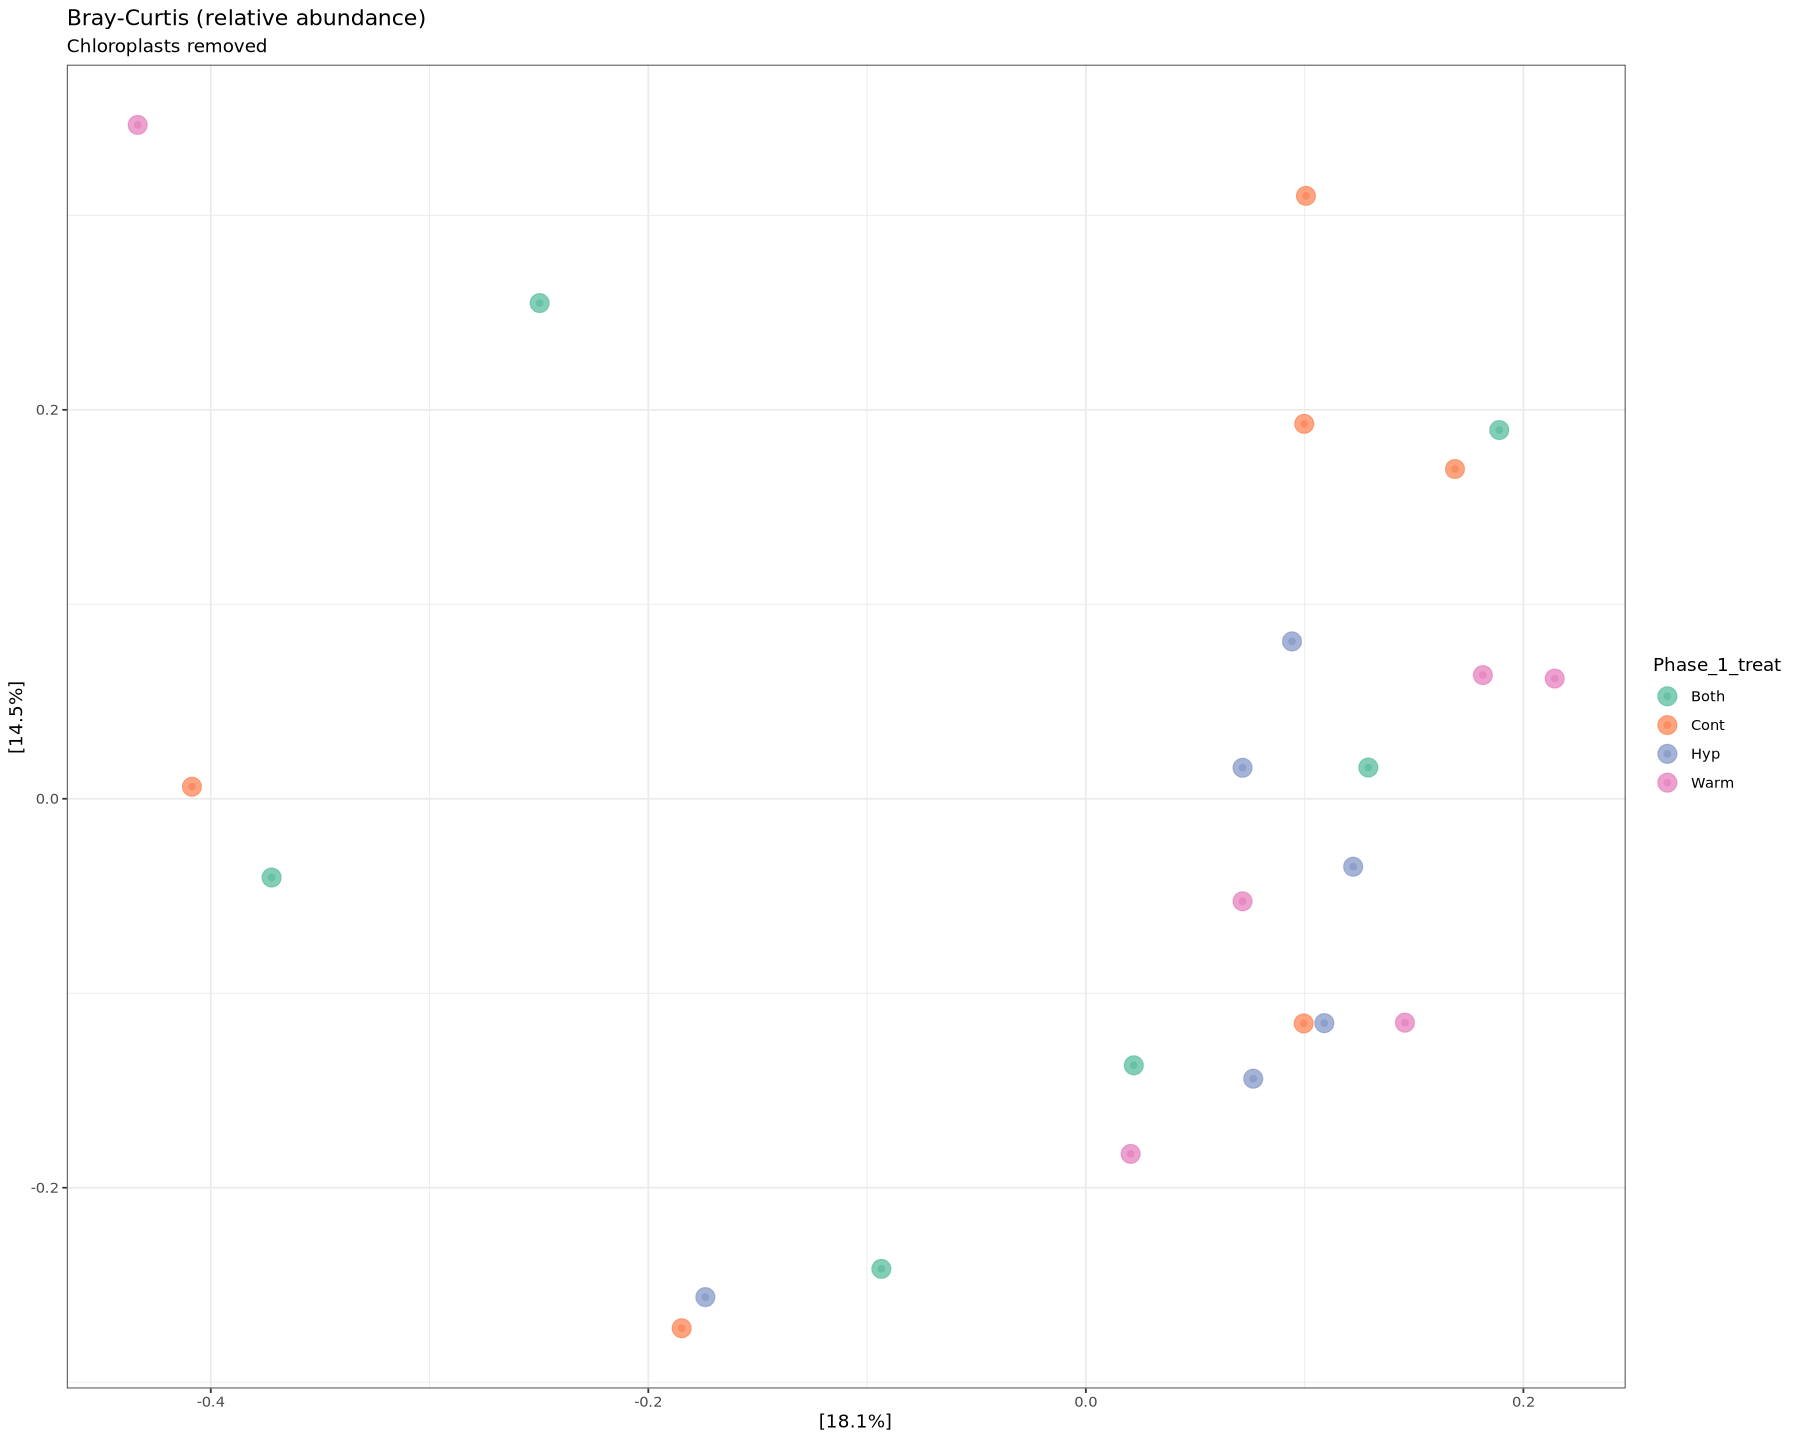

In [98]:
# Visualize PCoA
p_pcoa_bray_gut_nc <- plot_ordination(ps_gut_nc, pcoa_bray_gut_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Chloroplasts removed") +
    theme_bw()
p_pcoa_bray_gut_nc

In [99]:
# Ordinate using nMDS
nmds_bray_gut_nc <- ordinate(ps_gut_nc, method = "NMDS", distance = dist_bray_gut_nc)

Run 0 stress 0.09010494 
Run 1 stress 0.0958516 
Run 2 stress 0.09669111 
Run 3 stress 0.09669124 
Run 4 stress 0.09746895 
Run 5 stress 0.103876 
Run 6 stress 0.1038767 
Run 7 stress 0.128095 
Run 8 stress 0.1281037 
Run 9 stress 0.1136921 
Run 10 stress 0.1038768 
Run 11 stress 0.1108124 
Run 12 stress 0.09746847 
Run 13 stress 0.1085496 
Run 14 stress 0.1092722 
Run 15 stress 0.09669136 
Run 16 stress 0.1108121 
Run 17 stress 0.1272312 
Run 18 stress 0.1126628 
Run 19 stress 0.1085492 
Run 20 stress 0.1108125 
*** Best solution was not repeated -- monoMDS stopping criteria:
    20: stress ratio > sratmax


In [100]:
# nMDS stress value (< 0.2 okay)
nmds_bray_gut_nc$stress

[1] 0.09010494

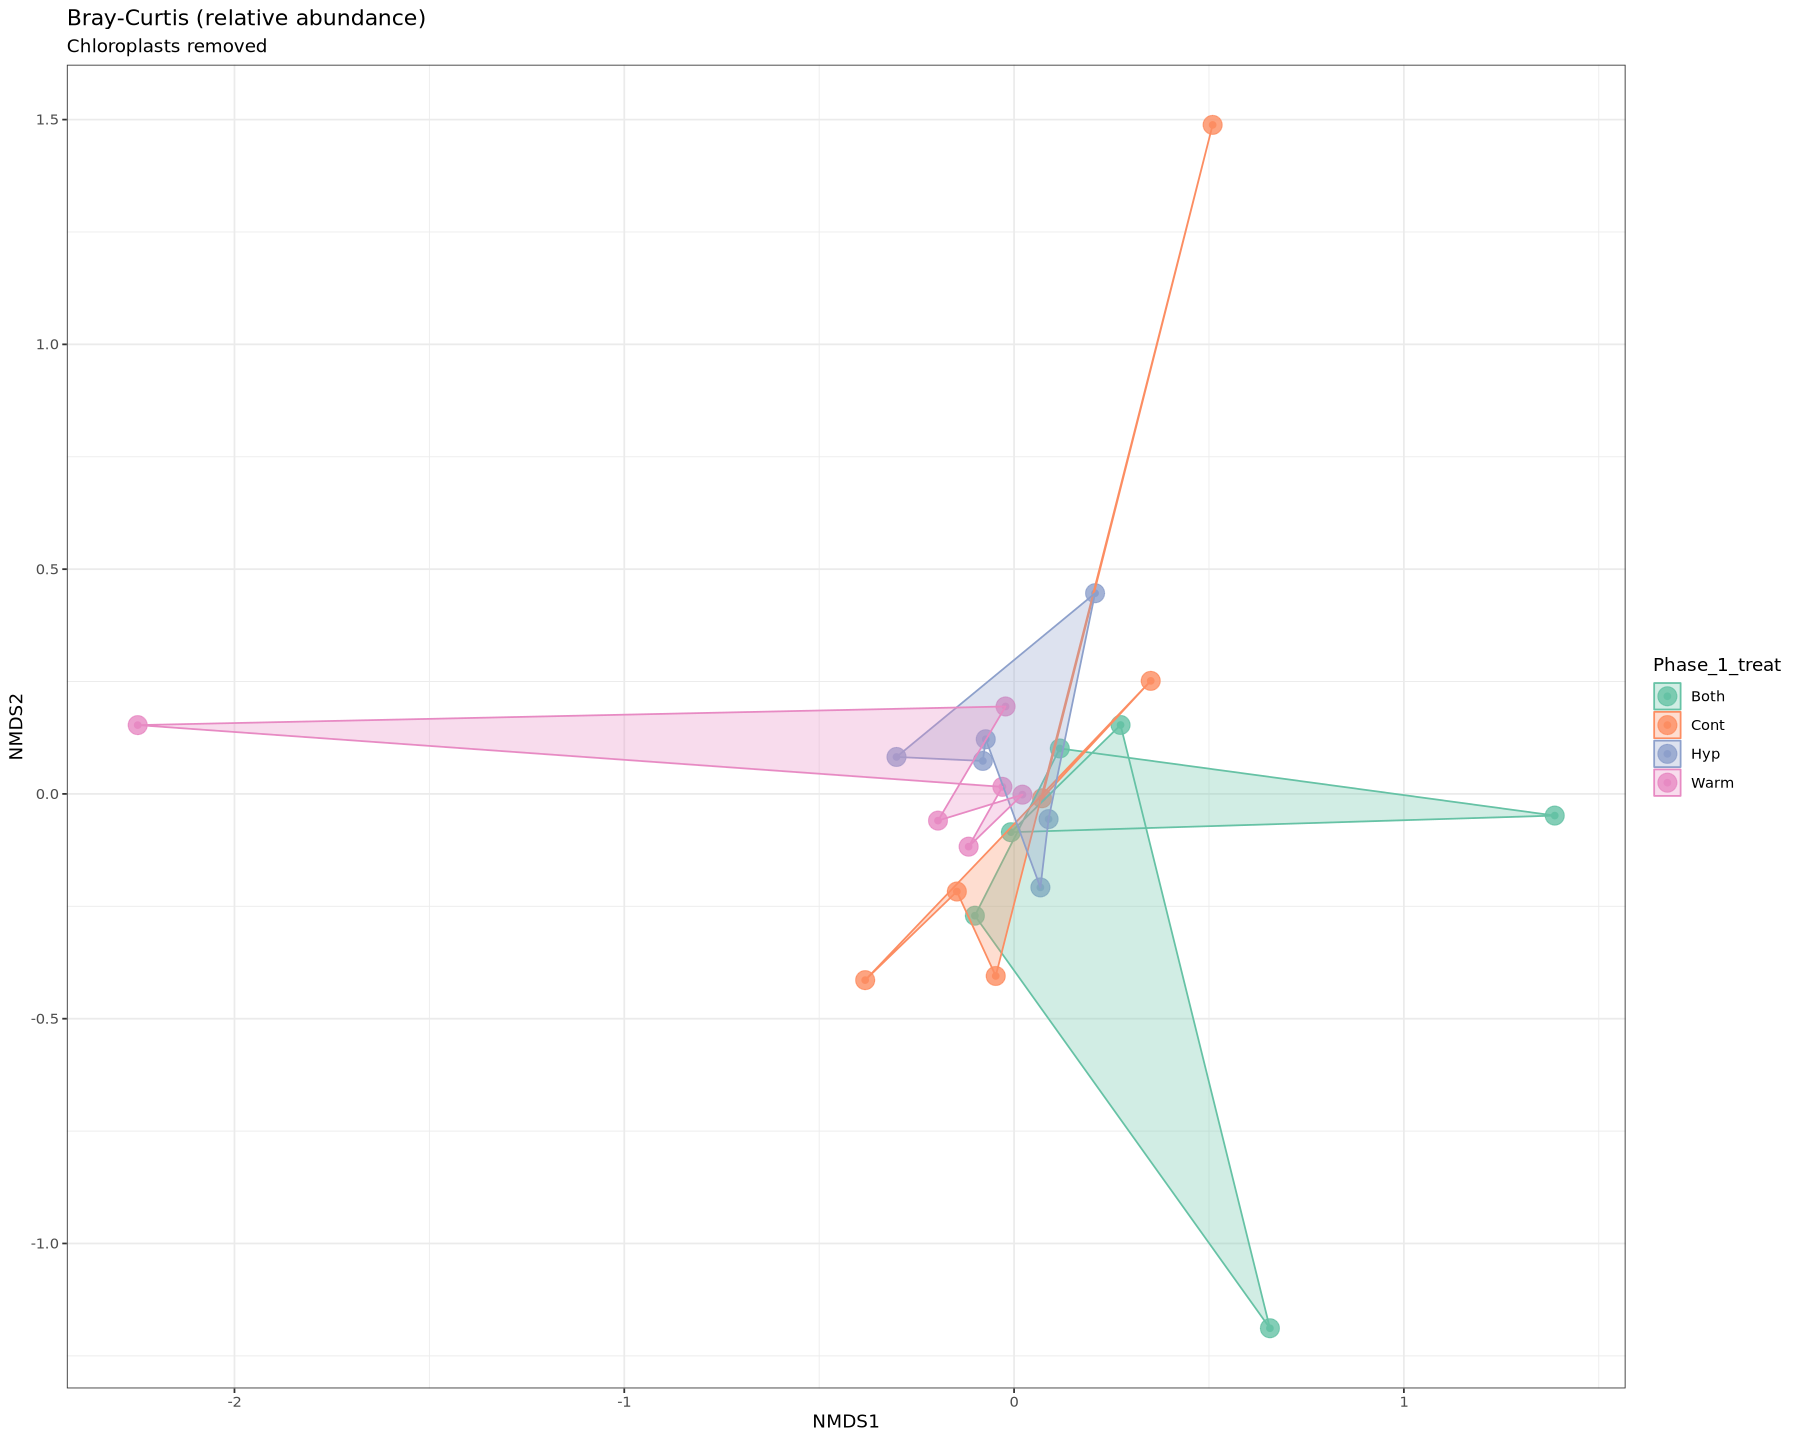

In [101]:
# Visualize nMDS
p_nmds_bray_gut_nc <- plot_ordination(ps_gut_nc, nmds_bray_gut_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Chloroplasts removed") +
    theme_bw() 
p_nmds_bray_gut_nc

# diversity

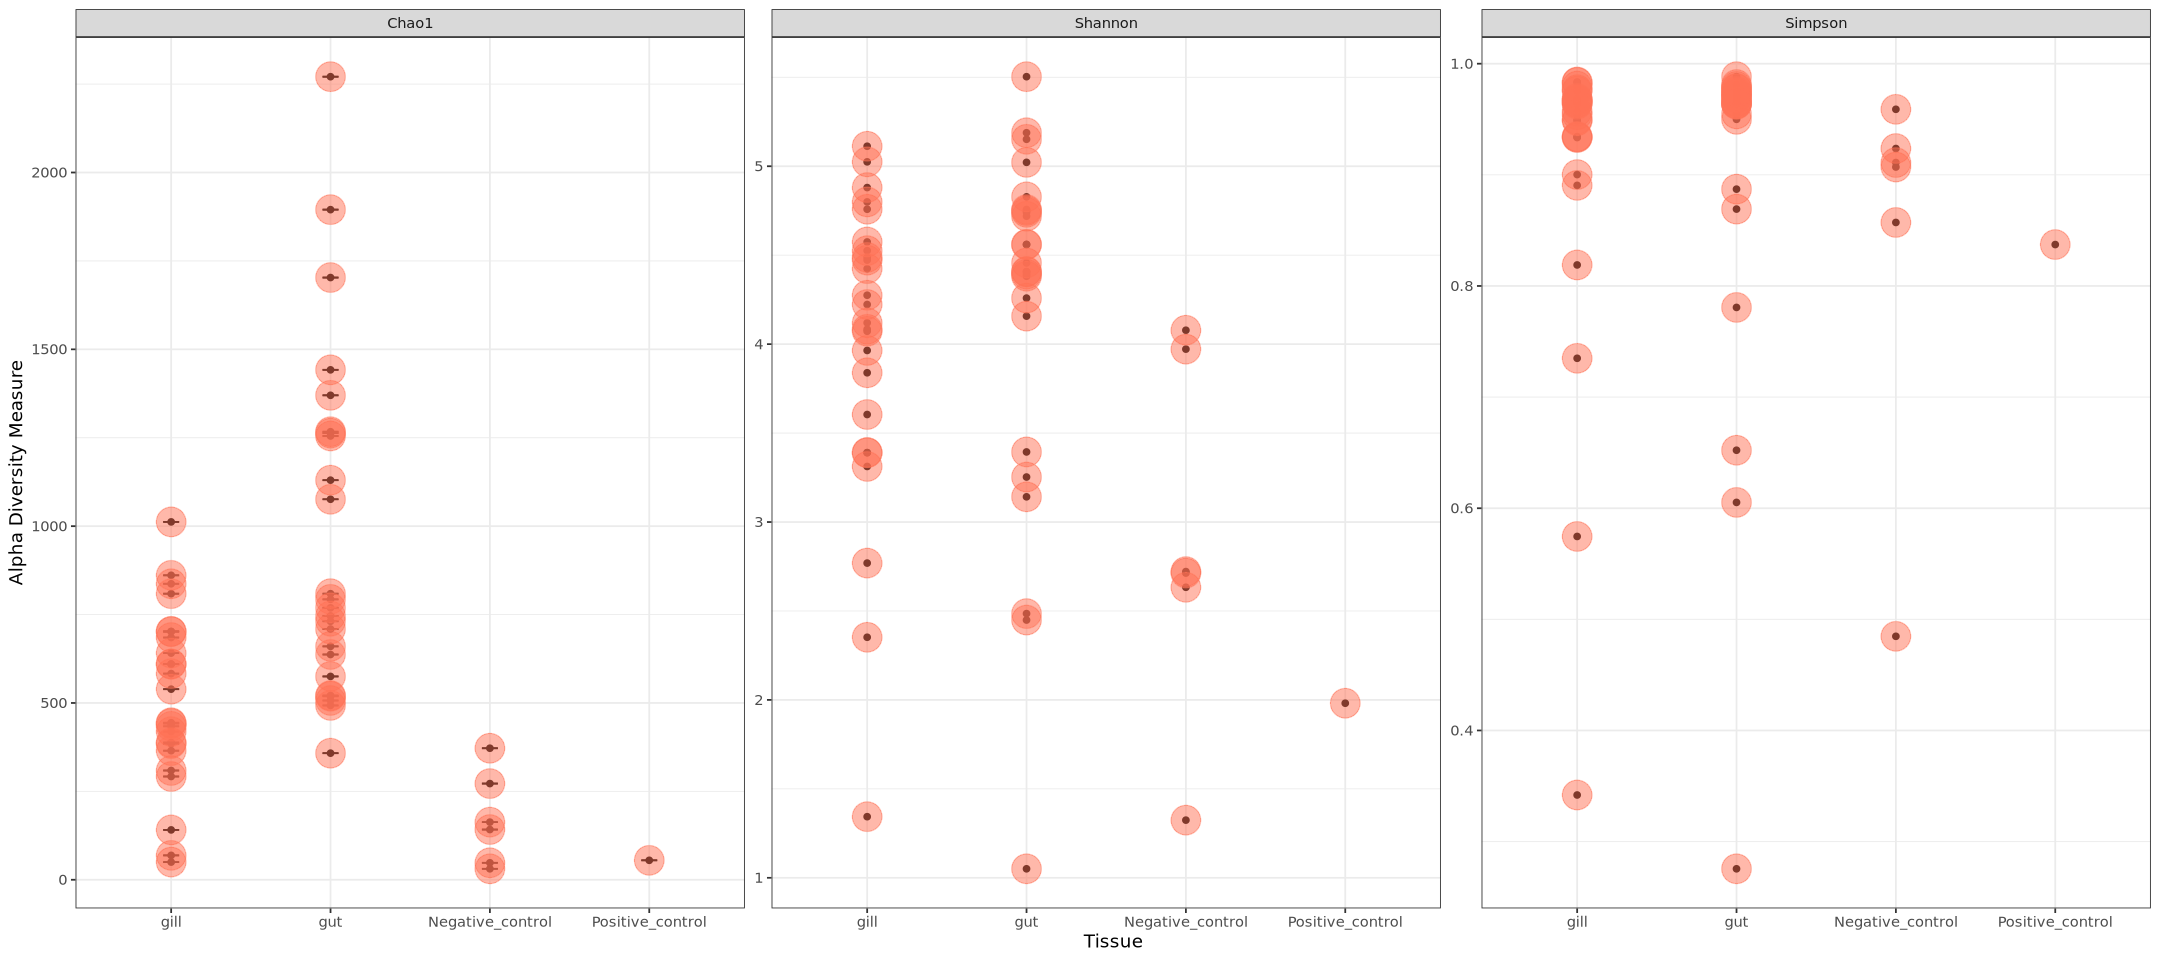

In [5]:
plot_richness(ps_p1, x = "Tissue", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_point(size = 8, alpha = 0.5, color = "coral 1")  +
    theme_bw()